<h1 align="center" style="font-size:2.7em; line-height:1.15">ROTOR magnetohidrodinámico</h1>
<h3 align="center">Simulación con PLUTO y reproducción con solver propio en Python</h3>
<p align="center">Brayan Nicolas Buitrago Montenegro<br>Astrofísica Computacional 2026-II</p>

---

**Resumen.** Se reproduce la configuración #01 del problema de prueba *Rotor* de PLUTO: un disco denso que gira rápidamente dentro de un plasma en reposo, atravesado por un campo magnético uniforme. El problema se resolvió con PLUTO y con un solver propio en Python, basado en el esquema clásico de Lax-Wendroff de dos pasos, al que fue necesario añadir una viscosidad artificial para estabilizarlo frente a los choques.

En una malla de 400², ambos códigos conservan la masa y la energía, mantienen $\nabla\cdot\mathbf{B}$ cerca de $10^{-11}$ y describen la misma física: hasta $t=0.15$, la energía cinética cae un 65–67 %, y alrededor de la mitad de esa pérdida pasa al campo magnético (58 % en PLUTO y 51 % en Python). La diferencia relativa $L_1$ entre códigos va del 1.2 % al 15 % y se concentra en los bordes del anillo denso y en los frentes de choque, donde la viscosidad artificial ensancha las discontinuidades. Al comparar mallas sucesivas de 100², 200² y 400², PLUTO converge con órdenes de 0.61–0.89 y el solver en Python con 0.32–0.63, y la diferencia entre ambos disminuye al refinar la malla.

**Palabras clave:** magnetohidrodinámica, rotor MHD, ondas de Alfvén, frenado magnético, transporte restringido, PLUTO.

---

| Sección | Contenido |
|---|---|
| **1. Introducción** | El problema del rotor, estado del arte, objetivo y alcance |
| **2. Modelo físico** | Ecuaciones, condiciones iniciales y de frontera, escalas |
| **3. Parte I: PLUTO** | Problema de prueba, método, paso a paso, resultados, verificación y resolución |
| **4. Parte II: Python** | Solver propio, validación, resultado preliminar y elección de la viscosidad, ejecución y resultados |
| **5. Comparación** | Métricas, resultados en 400², convergencia, fuentes de error y literatura |
| **6. Conclusiones** | Síntesis, limitaciones, referencias y reproducibilidad |

## 1. Introducción

### 1.1 El problema del rotor

El rotor MHD fue propuesto por Balsara y Spicer y es una prueba habitual de los códigos magnetohidrodinámicos. Un disco denso gira rápidamente dentro de un medio en reposo y más liviano, atravesado por un campo magnético uniforme. El campo inicial $\mathbf{B}_0$ apunta en $x$ y el eje de giro en $z$, es decir, son perpendiculares.

Como el plasma está acoplado al campo, el giro del disco tuerce las líneas de campo. Esa torsión se propaga hacia afuera, principalmente a lo largo de $\mathbf{B}_0$, como ondas de Alfvén de torsión que transportan momento angular del disco al medio. El resultado es un **frenado magnético**: el disco pierde rotación y su energía cinética pasa al campo y al gas.

La siguiente animación muestra un esquema del sistema entre $t=0$ y $t=0.15$:

<p align="center"><img src="figuras/animacion_rotor.gif" width="460"></p>

*Esquema animado del rotor. Al inicio, el disco ($\rho=10$) gira con velocidad angular $\omega$ dentro del plasma en reposo ($\rho=1$, $p=1$), atravesado por el campo uniforme $\mathbf{B}_0$. Con el tiempo, la torsión de las líneas avanza hacia $\pm x$ con velocidad $v_A$, de modo que el frente llega a $\lvert x\rvert=r_1+v_A t$, y las flechas verdes indican el momento angular que sale del disco.*

El problema resulta exigente porque combina varias dificultades en poco tiempo:

- Choques y discontinuidades creados por el movimiento supersónico;
- Regiones de presión muy baja, donde es difícil mantener la presión positiva;
- La necesidad de conservar $\nabla\cdot\mathbf{B}=0$ en la malla.

Este frenado magnético aparece en sistemas muy distintos:

- **Formación estelar.** El rotor MHD se originó como una versión simplificada del frenado magnético en la formación de estrellas [1]. Mouschovias y Paleologou obtuvieron una solución exacta, dependiente del tiempo, para un rotor alineado con el campo.
- **Estrellas de neutrones y púlsares.** Su magnetosfera corrota con la estrella, y esa rotación modifica la propagación de las ondas en el plasma, por ejemplo la polarización observada en los púlsares [2].
- **Chorros y discos de acreción.** Los flujos magnetizados en rotación están presentes en chorros estelares y extragalácticos, discos de acreción y la inestabilidad magnetorrotacional. PLUTO fue diseñado para estudiar estos sistemas [3]. En chorros de núcleos activos de galaxias y en estallidos de rayos gamma, los flujos son además relativistas [4].
- **Laboratorio.** El control de la rotación de plasmas con ondas se estudia para conceptos alternativos de fusión y para separar masas en plasmas [2]. La MHD también se usa en el diseño de experimentos de fusión por confinamiento inercial [1].

### 1.2 Estado del arte

**El rotor en la literatura numérica.** Balsara y Spicer lo usaron para evaluar su esquema de malla escalonada, y desde entonces se usa con frecuencia para probar códigos MHD:

- **Londrillo y Del Zanna** lo resolvieron hasta $t=0.15$, con la misma función de transición, comparando mallas de 200² con una referencia de 400² [5]. Encontraron un orden de precisión bajo por las discontinuidades, y que dos esquemas de segundo orden se comportan de forma muy parecida. Ambos hallazgos anticipan lo que se observa aquí.
- **El artículo de PLUTO** lo incluye como prueba en coordenadas cartesianas y polares, con 400² celdas, y compara el transporte restringido con el método de ocho ondas de Powell. Ambos resultados coinciden [3].
- **Dumbser et al.** lo resolvieron con un esquema ADER-DG de alto orden, dentro de un modelo hiperbólico unificado de mecánica de medios continuos y electrodinámica, y obtuvieron un acuerdo cualitativo con Balsara y Spicer [6].
- **Nikl et al.** lo resolvieron con elementos finitos curvilíneos lagrangianos de alto orden. Señalan que es poco común en códigos lagrangianos, porque la malla se enreda al girar [1].
- **van der Holst et al.** estudiaron una versión relativista con refinamiento adaptativo. Observaron choques rápidos que viajan hacia afuera y hacia el centro, y la deflexión del campo que frena la rotación inicial [4].

**Control de $\nabla\cdot\mathbf{B}$.** Las ecuaciones exigen $\nabla\cdot\mathbf{B}=0$, pero un método numérico puede violarlo. Hay dos grandes familias:

- **Transporte restringido (CT).** Evans y Hawley lo introdujeron. Balsara y Spicer lo combinaron con flujos de Godunov, y después llegaron formulaciones como la de Londrillo y Del Zanna [5] y el método no separado de Gardiner y Stone. Conserva la divergencia en la malla hasta el error de redondeo.
- **Limpieza de divergencia.** Tolera el error y lo elimina o amortigua durante la evolución. Dedner et al. desarrollaron una versión hiperbólica.

Tóth comparó siete esquemas para mantener esta restricción, y Balsara y Kim contrastaron la limpieza de divergencia con el enfoque de malla escalonada en un problema exigente, donde encontraron deficiencias en los esquemas de limpieza.

**Solvers de Riemann.** El solver HLLD de Miyoshi y Kusano resuelve de forma aproximada varias ondas de la MHD, incluidas las discontinuidades rotacionales, y se reduce a HLLC cuando el campo se anula. Es el que usa PLUTO en este proyecto. Los métodos de este tipo, llamados de Godunov, calculan el flujo en cada cara resolviendo de forma aproximada un problema de Riemann. Antes de ellos se usaban esquemas centrados, como el de Lax-Wendroff, que no resuelven ningún problema de Riemann y necesitan una viscosidad artificial para manejar los choques; el solver en Python de este proyecto pertenece a esta familia.

**Tendencias recientes.** Las investigaciones actuales buscan aprovechar mejor las supercomputadoras y los aceleradores:

- Athena++ ofrece un marco de AMR para MHD con alta eficiencia paralela.
- Idefix implementa métodos de Godunov portables entre arquitecturas mediante Kokkos.
- gPLUTO reescribe PLUTO en C++ con OpenACC para GPU, con opciones de ocho ondas, limpieza de divergencia y CT.

**Lugar de este proyecto.** PLUTO se ejecuta con un método de Godunov de segundo orden: HLLD con CT, reconstrucción MC y RK2. El solver en Python usa un esquema más básico y anterior, el Lax-Wendroff de dos pasos con viscosidad artificial. El aporte no es un método nuevo, sino medir cuánto se acerca un esquema clásico, escrito desde cero, a un código de producción, y de dónde vienen las diferencias.

### 1.3 Objetivo y alcance

**Objetivo.** Reproducir la **configuración #01** de `Test_Problems/MHD/Rotor` y, para ello:

- simular el problema con PLUTO y visualizar todas las variables con pyPLUTO;
- reproducirlo con un solver propio en Python, escrito solo con NumPy, a partir del esquema de Lax-Wendroff;
- cuantificar las diferencias entre ambos, su convergencia y sus posibles causas.

**Alcance.** La siguiente tabla resume lo que incluye el proyecto y lo que queda fuera:

| Incluido | Fuera del alcance |
|---|---|
| MHD ideal en 2D cartesiano | Problemas 3D o en otras geometrías |
| Mallas uniformes de 100² a 400² | Refinamiento adaptativo (AMR) con Chombo |
| Evolución hasta $t=0.15$ | Resistividad, viscosidad y otros efectos no ideales |
| Configuración #01 sin modificar `init.c` | Las otras diez configuraciones del problema |

## 2. Modelo físico

### 2.1 Ecuaciones que rigen el sistema

Se resuelven las ecuaciones de la **MHD ideal**, sin viscosidad, resistividad ni gravedad. En forma conservativa:

$$\frac{\partial \rho}{\partial t}+\nabla\cdot(\rho\mathbf{v})=0 \tag{1}$$

$$\frac{\partial (\rho\mathbf{v})}{\partial t}+\nabla\cdot\left(\rho\mathbf{v}\mathbf{v}-\mathbf{B}\mathbf{B}+p_t\mathsf{I}\right)=0 \tag{2}$$

$$\frac{\partial E}{\partial t}+\nabla\cdot\left[(E+p_t)\mathbf{v}-\mathbf{B}(\mathbf{v}\cdot\mathbf{B})\right]=0 \tag{3}$$

$$\frac{\partial \mathbf{B}}{\partial t}-\nabla\times(\mathbf{v}\times\mathbf{B})=0,\qquad \nabla\cdot\mathbf{B}=0 \tag{4}$$

donde $\rho$ es la densidad, $\mathbf{v}$ la velocidad, $\mathbf{B}$ el campo magnético y $p$ la presión térmica. La presión total y la energía total son

$$p_t=p+\frac{B^2}{2},\qquad E=\frac{p}{\gamma-1}+\frac{1}{2}\rho v^2+\frac{B^2}{2}. \tag{5}$$

El sistema se cierra con la ecuación de estado de gas ideal, con $\gamma=1.4$. En las unidades de PLUTO, el factor $4\pi$ queda absorbido en la definición de $\mathbf{B}$, por eso la presión magnética se escribe como $B^2/2$.

Como el problema es 2D y parte con $v_z=B_z=0$, estas ecuaciones no generan componentes en $z$. Por eso ambas variables deben permanecer exactamente nulas.

### 2.2 Condiciones iniciales y de frontera

**Dominio y tiempo.** $(x,y)\in[-0.5,0.5]^2$, con evolución hasta $t=0.15$.

**Estado inicial.** La presión es uniforme ($p=1$), el campo es uniforme ($B_x=5/\sqrt{4\pi}$, $B_y=0$) y, con $r=\sqrt{x^2+y^2}$, $r_0=0.1$, $r_1=0.115$ y $\omega=20$:

$$\rho=\begin{cases}10 & r\le r_0\\ 1+9f & r_0<r<r_1\\ 1 & r\ge r_1\end{cases} \tag{6}$$

$$(v_x,v_y)=\begin{cases}\omega\,(-y,\;x) & r\le r_0\\ f\,\omega\,\dfrac{r_0}{r}\,(-y,\;x) & r_0<r<r_1\\ (0,\;0) & r\ge r_1\end{cases} \tag{7}$$

La función $f=(r_1-r)/(r_1-r_0)$ suaviza la unión entre el disco y el medio. Dentro del disco, la ecuación (7) es una rotación rígida, $v_\phi=\omega r$.

**Fronteras.** Se usa `outflow` en los cuatro bordes, que deja salir el flujo sin imponer valores externos. La sección 3.5 muestra que hasta $t=0.15$ las perturbaciones aún no llegan a los bordes.

### 2.3 Escalas características

La siguiente tabla muestra las velocidades características del medio y del disco, calculadas a partir del estado inicial:

| Cantidad | Medio ($\rho=1$) | Disco ($\rho=10$) |
|---|---|---|
| Velocidad del sonido, $c_s=\sqrt{\gamma p/\rho}$ | 1.183 | 0.374 |
| Velocidad de Alfvén, $v_A=B/\sqrt{\rho}$ | 1.411 | 0.446 |

La velocidad en el borde del disco es $\omega r_0=2$, unas 5.3 veces la velocidad del sonido local: el rotor es fuertemente supersónico. Además, $\beta=2p/B^2\approx1.0$, de modo que las presiones térmica y magnética son comparables. El periodo de giro inicial es $2\pi/\omega\approx0.314$, así que $t=0.15$ equivale a un poco menos de media vuelta.

## 3. Parte I: simulación con PLUTO

### 3.1 El problema de prueba de PLUTO

El simulador PLUTO [7] incluye una colección de **problemas de prueba**. Cada problema tiene una carpeta con los archivos necesarios para configurarlo y ejecutarlo. En el caso del rotor MHD (`Test_Problems/MHD/Rotor`), la siguiente tabla describe los archivos principales:

| Archivo | Función |
|---|---|
| `init.c` | Define las condiciones iniciales y las funciones propias del problema |
| `definitions_XX.h` | Opciones de compilación de cada configuración XX: física, geometría y métodos numéricos |
| `pluto_XX.ini` | Opciones de ejecución de cada configuración: malla, tiempo, solver, fronteras y salidas |

Para usar la configuración XX, sus dos archivos se copian a la carpeta de trabajo como `definitions.h` y `pluto.ini`. Las configuraciones disponibles están documentadas en una tabla dentro de `init.c`, que muestra la siguiente figura:

<img src="capturas/03_configuraciones_rotor.png" width="430">

Se eligió la configuración **#01**, que usa geometría cartesiana (`CARTESIAN`, coordenadas $(x,y)$) y transporte restringido (`CT`) para controlar $\nabla\cdot\mathbf{B}$, sin campo de fondo (`BCK_FIELD = NO`) y sin refinamiento adaptativo (`AMR = NO`). Es la única configuración cartesiana con CT, así que cumple las condiciones del proyecto, 2D y sin Chombo, y conserva $\nabla\cdot\mathbf{B}$ hasta el error de redondeo.

La siguiente figura muestra la descripción del problema que aparece en el comentario inicial de `init.c`:

<img src="capturas/04_init_descripcion.png" width="680">

*Descripción del problema en el comentario inicial de `init.c`.* Corresponde a las ecuaciones (6) y (7): el disco tiene densidad 10 y gira con $v_\phi=\omega r$, la transición usa la función $f$, y fuera de ella $\rho=1$ y $v=0$. También fija $\Gamma=1.4$ en la ecuación de estado (5). La línea 21 del archivo omite la letra $f$ al definir la función de transición; la definición correcta, $f=(r_1-r)/(r_1-r_0)$, es la que usa el código.

La siguiente figura muestra los parámetros físicos que define `init.c`:

<img src="capturas/05_init_parametros.png" width="470">

*Parámetros físicos definidos en `init.c`.* La siguiente tabla relaciona cada línea con el modelo de la sección 2:

| Línea en `init.c` | Parámetro | Dónde aparece |
|---|---|---|
| `g_gamma = 1.4` | Índice adiabático $\gamma$ | Ecuación de estado, (5) |
| `v[PRS] = 1.0` | Presión inicial $p=1$ | Estado inicial, sección 2.2 |
| `omega = 20.0` | Velocidad angular $\omega$ | Ecuación (7) |
| `Bx = 5.0/sqrt(4.0*CONST_PI)` | Campo inicial $B_x$ | Estado inicial, sección 2.2 |
| `r0 = 0.1`, `r1 = 0.115` | Radios del disco y de la transición | Ecuaciones (6) y (7) |
| `v[BX1] = Bx`, `v[BX2] = 0.0` | Componentes de $\mathbf{B}$ | Estado inicial, sección 2.2 |

El bloque `#if HAVE_ENERGY` solo se activa cuando se resuelve la ecuación de energía (3), como en este caso.

### 3.2 Método numérico

PLUTO resuelve las ecuaciones por volúmenes finitos. En cada celda guarda un promedio, y las interfaces se tratan como pequeños problemas de Riemann. La siguiente tabla resume los componentes del método que usa la configuración #01:

| Componente | Elección | Función |
|---|---|---|
| Malla | 400 × 400, uniforme | Discretiza el dominio ($\Delta x=0.0025$) |
| Reconstrucción | Lineal, limitador MC | Estima los valores en las caras sin crear oscilaciones en los choques |
| Solver de Riemann | HLLD | Calcula los flujos entre celdas, incluyendo las ondas de Alfvén |
| Avance temporal | RK2, CFL = 0.4 | Integra en el tiempo, con $\Delta t$ limitado por las ondas más rápidas |
| Control de $\nabla\cdot\mathbf{B}$ | Transporte restringido (CT) [5] | Guarda $\mathbf{B}$ en las caras para conservar la divergencia en la malla |
| Promedio de la EMF | `ARITHMETIC` | Obtiene el campo eléctrico en las esquinas de las celdas |

### 3.3 Simulación

#### 3.3.1 Configuración

Se creó una carpeta de trabajo y se copiaron allí los archivos de la configuración #01: `init.c`, `definitions_01.h` como `definitions.h` y `pluto_01.ini` como `pluto.ini`. Luego se ejecutó el programa de configuración de PLUTO:

```bash
python $PLUTO_DIR/setup.py
```

El menú cargó la configuración de `definitions.h`. La siguiente figura muestra las opciones generales, donde se comprobó que el problema fuera 2D, cartesiano y MHD, con reconstrucción lineal y RK2:

<img src="capturas/01_setup_problema.png" width="520">

*Opciones generales del problema.*

La siguiente figura muestra el menú de MHD, donde se comprobó la ecuación de estado ideal y el transporte restringido, sin términos adicionales de física:

<img src="capturas/02_setup_mhd.png" width="560">

*Opciones de MHD.*

Al terminar se seleccionó `Linux.gcc.defs`, que genera un `makefile` para compilar con `gcc` en serie.

#### 3.3.2 Compilar

```bash
make 2>&1 | tee make.log
```

La compilación generó el ejecutable `pluto`. Solo aparecieron avisos del compilador sobre el código fuente de PLUTO, sin errores.

#### 3.3.3 Ajustar `pluto.ini`

La siguiente figura muestra los parámetros de ejecución de `pluto.ini`. La malla, el tiempo final, el solver y las fronteras se mantuvieron como en la plantilla:

<img src="capturas/06_pluto_ini.png" width="760">

*Parámetros de ejecución en `pluto.ini`.*

El único cambio fue el intervalo de salida, de `1.015` a `0.05`, para guardar estados intermedios, como muestra la siguiente figura. Este cambio no requiere recompilar.

<img src="capturas/07_pluto_ini_salidas.png" width="420">

*Salida `dbl` cada 0.05 unidades de tiempo.*

#### 3.3.4 Ejecutar

```bash
./pluto 2>&1 | tee run.log
```

Las siguientes figuras muestran el inicio y el final de la corrida:

<img src="capturas/08_inicio_corrida.png" width="760">

*Inicio de la corrida.*

<img src="capturas/09_fin_corrida.png" width="600">

*Final de la corrida: terminó con `Done` en 1 min 9 s.*

En cada paso, el log informa un número de Mach máximo; al final de la corrida es `Mach = 6.646913`. PLUTO lo calcula en las interfaces entre celdas, usando solo la velocidad normal a cada cara. Por eso no coincide exactamente con el Mach máximo que se obtiene más adelante a partir de los mapas (sección 3.4), donde se usa el módulo completo de la velocidad en el centro de cada celda.

#### 3.3.5 Verificar las salidas

La siguiente figura muestra los archivos de salida y el contenido de `dbl.out`:

<img src="capturas/10_verificacion_salidas.png" width="760">

*Se obtuvieron cuatro archivos `.dbl`. En `dbl.out`, las columnas son número de salida, tiempo, paso de tiempo y paso de integración.*

La corrida terminó en el paso 590. Los tiempos intermedios no son exactamente 0.05 y 0.10, porque PLUTO escribe en el primer paso que supera cada instante.

#### 3.3.6 Visualizar con pyPLUTO

Los resultados se movieron a `pluto_run_400/`. Primero se exploraron con la interfaz gráfica `pypluto-gui`; la siguiente figura muestra la salida 3:

<img src="capturas/11_pypluto_gui.png" width="720">

*Densidad en $t=0.15$ en la interfaz de pyPLUTO, en escala logarítmica.*

Para las figuras de este informe no se usó la interfaz gráfica, sino las funciones de pyPLUTO desde código Python (celdas siguientes). Así las figuras se generan de forma reproducible, con el mismo formato y las mismas escalas para todas las salidas, y se pueden comparar directamente con las del solver en Python.

In [1]:
from pathlib import Path
import re, time, subprocess
import numpy as np
import matplotlib.pyplot as plt
import pyPLUTO as pp
%matplotlib inline

RAIZ = Path.cwd()
FIGURAS = RAIZ / "figuras"; FIGURAS.mkdir(exist_ok=True)
GAMMA = 1.4                 # índice adiabático, igual que en init.c
MALLAS = (100, 200, 400)    # resoluciones estudiadas
CORRER_PLUTO = False        # True: vuelve a ejecutar ./pluto en cada malla (sección 3.3); False: usa las salidas guardadas
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 150})
print("Carpeta de trabajo:", RAIZ)

PyPLUTO version: 1.2.6   session: Jupyter notebook or qtconsole
Carpeta de trabajo: /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2


In [2]:
def correr_pluto(N):
    """Ejecuta PLUTO en pluto_run_N/."""
    carpeta = RAIZ / f"pluto_run_{N}"
    carpeta.mkdir(exist_ok=True)
    ini = (RAIZ / "pluto" / "pluto.ini").read_text()
    ini = re.sub(r"(X[12]-grid\s+1\s+-0\.5\s+)\d+", rf"\g<1>{N}", ini)
    (carpeta / "pluto.ini").write_text(ini)
    with open(carpeta / "run.log", "w") as log:
        subprocess.run([str(RAIZ / "pluto" / "pluto")], cwd=carpeta, stdout=log, stderr=subprocess.STDOUT, check=True)

if CORRER_PLUTO:
    for N in MALLAS:
        correr_pluto(N)
else:
    print("Se usan las salidas de PLUTO ya calculadas:", ", ".join(f"pluto_run_{N}/" for N in MALLAS))

Se usan las salidas de PLUTO ya calculadas: pluto_run_100/, pluto_run_200/, pluto_run_400/


In [3]:
def derivadas(f):
    """Añade el número de Mach y |B| a un estado (diccionario de arreglos con orden [x, y])."""
    cs = np.sqrt(GAMMA * f["prs"] / f["rho"])
    f["mach"] = np.sqrt(f["vx1"]**2 + f["vx2"]**2 + f["vx3"]**2) / cs
    f["bmag"] = np.sqrt(f["Bx1"]**2 + f["Bx2"]**2 + f["Bx3"]**2)
    return f

def tiempos_pluto(N):
    """Tiempos de salida de dbl.out (D.timelist de pyPLUTO trae todos, no el de cada salida)."""
    return np.loadtxt(RAIZ / f"pluto_run_{N}" / "dbl.out", usecols=1, ndmin=1)

def cargar_pluto(N, n):
    """Lee la salida n de pluto_run_N con pyPLUTO. Incluye Bx1s y Bx2s, el campo en las caras (malla CT)."""
    D = pp.Load(path=str(RAIZ / f"pluto_run_{N}") + "/", datatype="dbl", nout=n)
    f = {k: np.array(v) for k, v in D.d_vars.items()}
    f.update(t=float(tiempos_pluto(N)[n]), x=np.array(D.x1), y=np.array(D.x2))
    return derivadas(f)

PL = {n: cargar_pluto(400, n) for n in range(len(tiempos_pluto(400)))}       # las 4 salidas de 400²
PLf = {N: cargar_pluto(N, len(tiempos_pluto(N)) - 1) for N in MALLAS}         # estado final de cada malla
for n, f in PL.items():
    print(f"400², salida {n}: t = {f['t']:.5f}   rho en [{f['rho'].min():.4f}, {f['rho'].max():.4f}]")

Load: folder /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2/pluto_run_400/,     output 0


Load: folder /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2/pluto_run_400/,     output 1


Load: folder /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2/pluto_run_400/,     output 2


Load: folder /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2/pluto_run_400/,     output 3


Load: folder /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2/pluto_run_100/,     output 3


Load: folder /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2/pluto_run_200/,     output 3


Load: folder /home/bnbuitragom/Computational-Astrophysics/09_Proyecto2/pluto_run_400/,     output 3


400², salida 0: t = 0.00000   rho en [1.0000, 10.0000]
400², salida 1: t = 0.04985   rho en [0.8394, 17.1030]
400², salida 2: t = 0.09990   rho en [0.6373, 14.0575]
400², salida 3: t = 0.15000   rho en [0.4810, 13.0479]


La función siguiente dibuja con pyPLUTO (`Image.create_axes` e `Image.display`) los 10 paneles de cada salida. Es una función genérica: se usa aquí para las salidas de PLUTO y en la sección 4.5 para las del solver en Python. `display` recibe los arreglos con orden $[x,y]$, igual que los devuelve `pp.Load`.

In [4]:
def limites(a, simetrico):
    """vmin y vmax de un panel. Los campos con signo se centran en cero."""
    if simetrico:
        m = max(np.abs(a).max(), 1e-2)              # evita un rango nulo en v_z y B_z
        return -m, m
    vmin, vmax = a.min(), a.max()
    if vmax - vmin < 1e-6 * max(1.0, abs(vmax)):    # campo casi uniforme: no resaltar el ruido de redondeo
        c, w = 0.5 * (vmin + vmax), 0.1 * max(abs(0.5 * (vmin + vmax)), 1.0)
        return c - w, c + w
    return vmin, vmax

def nota_uniforme(a, etiqueta):
    """Texto para un panel sin estructura; None si el campo no es uniforme."""
    if np.ptp(a) > 1e-10 * max(1.0, np.abs(a).max()):
        return None
    return f"{etiqueta} = 0\nen todo el dominio" if np.abs(a).max() == 0.0 else f"{etiqueta} = {a.mean():.3f}\n(uniforme)"

def paneles(f):
    """(arreglo, colormap, etiqueta, escala simétrica) de los 10 paneles: escalares, velocidad, campo y |B|."""
    return [(np.log10(f["rho"]), "inferno", r"$\log_{10}\rho$", False), (f["prs"], "viridis", r"$p$", False),
            (f["mach"], "magma", r"$M$", False), (f["vx1"], "RdBu_r", r"$v_x$", True), (f["vx2"], "RdBu_r", r"$v_y$", True),
            (f["vx3"], "RdBu_r", r"$v_z$", True), (f["Bx1"], "RdBu_r", r"$B_x$", True), (f["Bx2"], "RdBu_r", r"$B_y$", True),
            (f["Bx3"], "RdBu_r", r"$B_z$", True), (f["bmag"], "plasma", r"$|B|$", False)]

def figura(f, archivo, ref=None):
    """Figura de 10 paneles de un estado f, hecha con pyPLUTO (Image.create_axes e Image.display).
    Sirve para las salidas de PLUTO y para las del solver en Python. ref es el estado del que se toman
    los límites de color (por defecto, el mismo f); para Python se pasa el de PLUTO, así las figuras se comparan directamente."""
    ref = f if ref is None else ref
    I = pp.Image(LaTeX=False)
    ejes = np.ravel(I.create_axes(ncol=3, nrow=4, figsize=[16, 18]))
    for ax, (arr, cmap, etiqueta, sim), (arr_ref, _, _, _) in zip(ejes, paneles(f), paneles(ref)):
        vmin, vmax = limites(arr_ref, sim)
        I.display(arr, x1=f["x"], x2=f["y"], ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, cpos="right", clabel=etiqueta,
                  title=f"{etiqueta}   t = {f['t']:.3f}", xtitle="x", ytitle="y", aspect="equal")
        ax.set_xticks([-0.4, 0.0, 0.4])
        nota = nota_uniforme(arr, etiqueta)
        if nota:
            ax.text(0.5, 0.5, nota, transform=ax.transAxes, ha="center", va="center", fontsize=14,
                    bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.5"))
    for ax in ejes[10:]:
        ax.set_visible(False)                       # la última fila solo tiene |B|
    I.savefig(str(FIGURAS / archivo), dpi=150)
    plt.show()

### 3.4 Resultados con PLUTO

Las siguientes figuras muestran, para cada salida, $\log_{10}\rho$, $p$, el número de Mach $M=|\mathbf{v}|/c_s$, $|\mathbf{B}|$ y las tres componentes de $\mathbf{v}$ y de $\mathbf{B}$.

#### 3.4.1 Estado inicial, $t=0$

La siguiente figura muestra el estado inicial:

Image class created at nwin 1


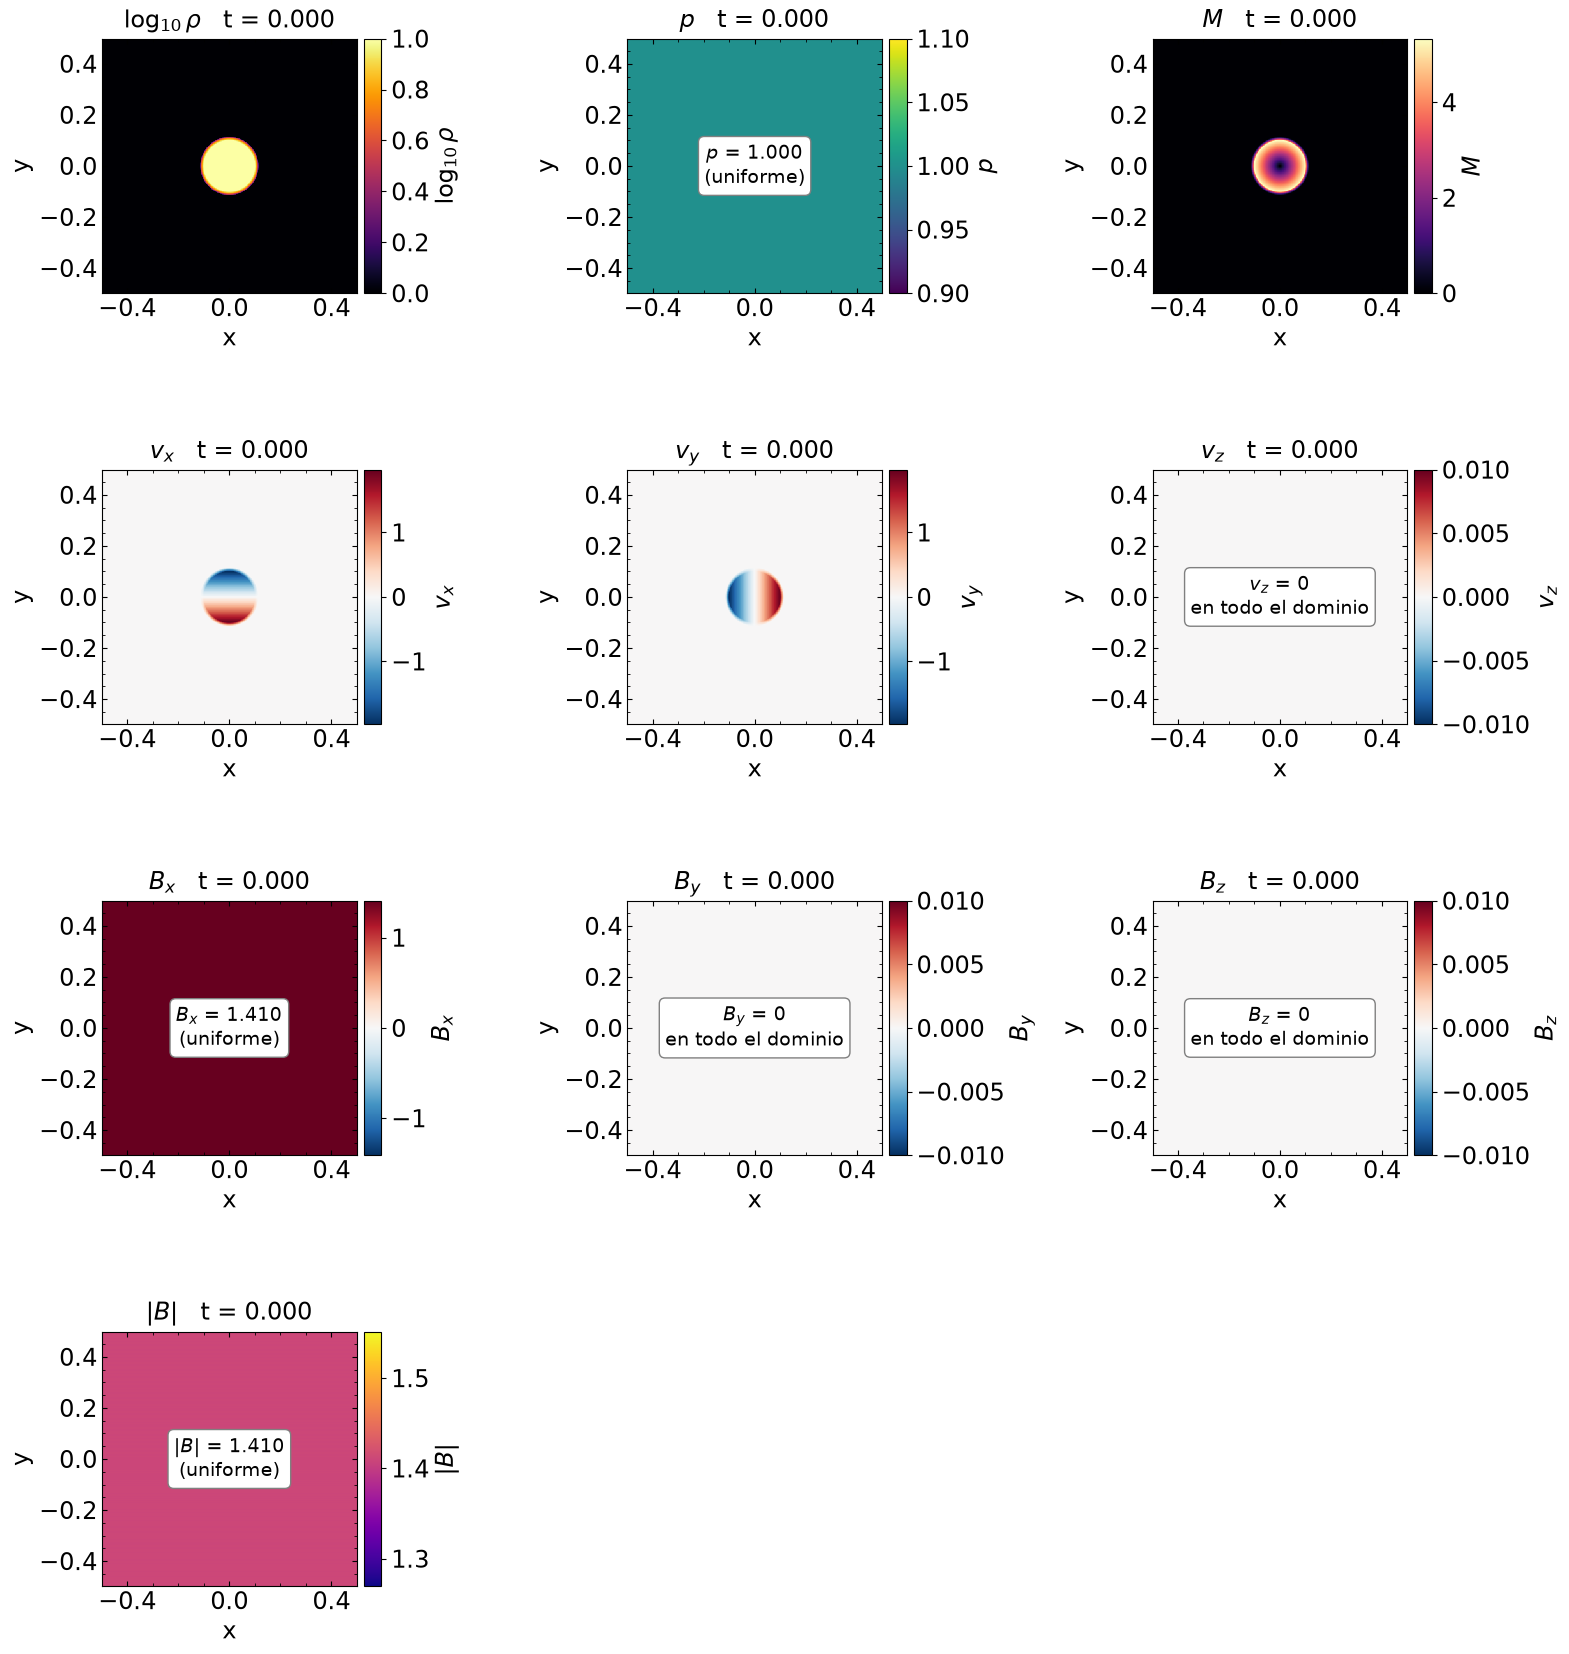

In [5]:
figura(PL[0], "pluto_rotor_0000.png")

#### 3.4.2 Primera etapa, $t\approx0.05$

La siguiente figura muestra la salida 1:

Image class created at nwin 1


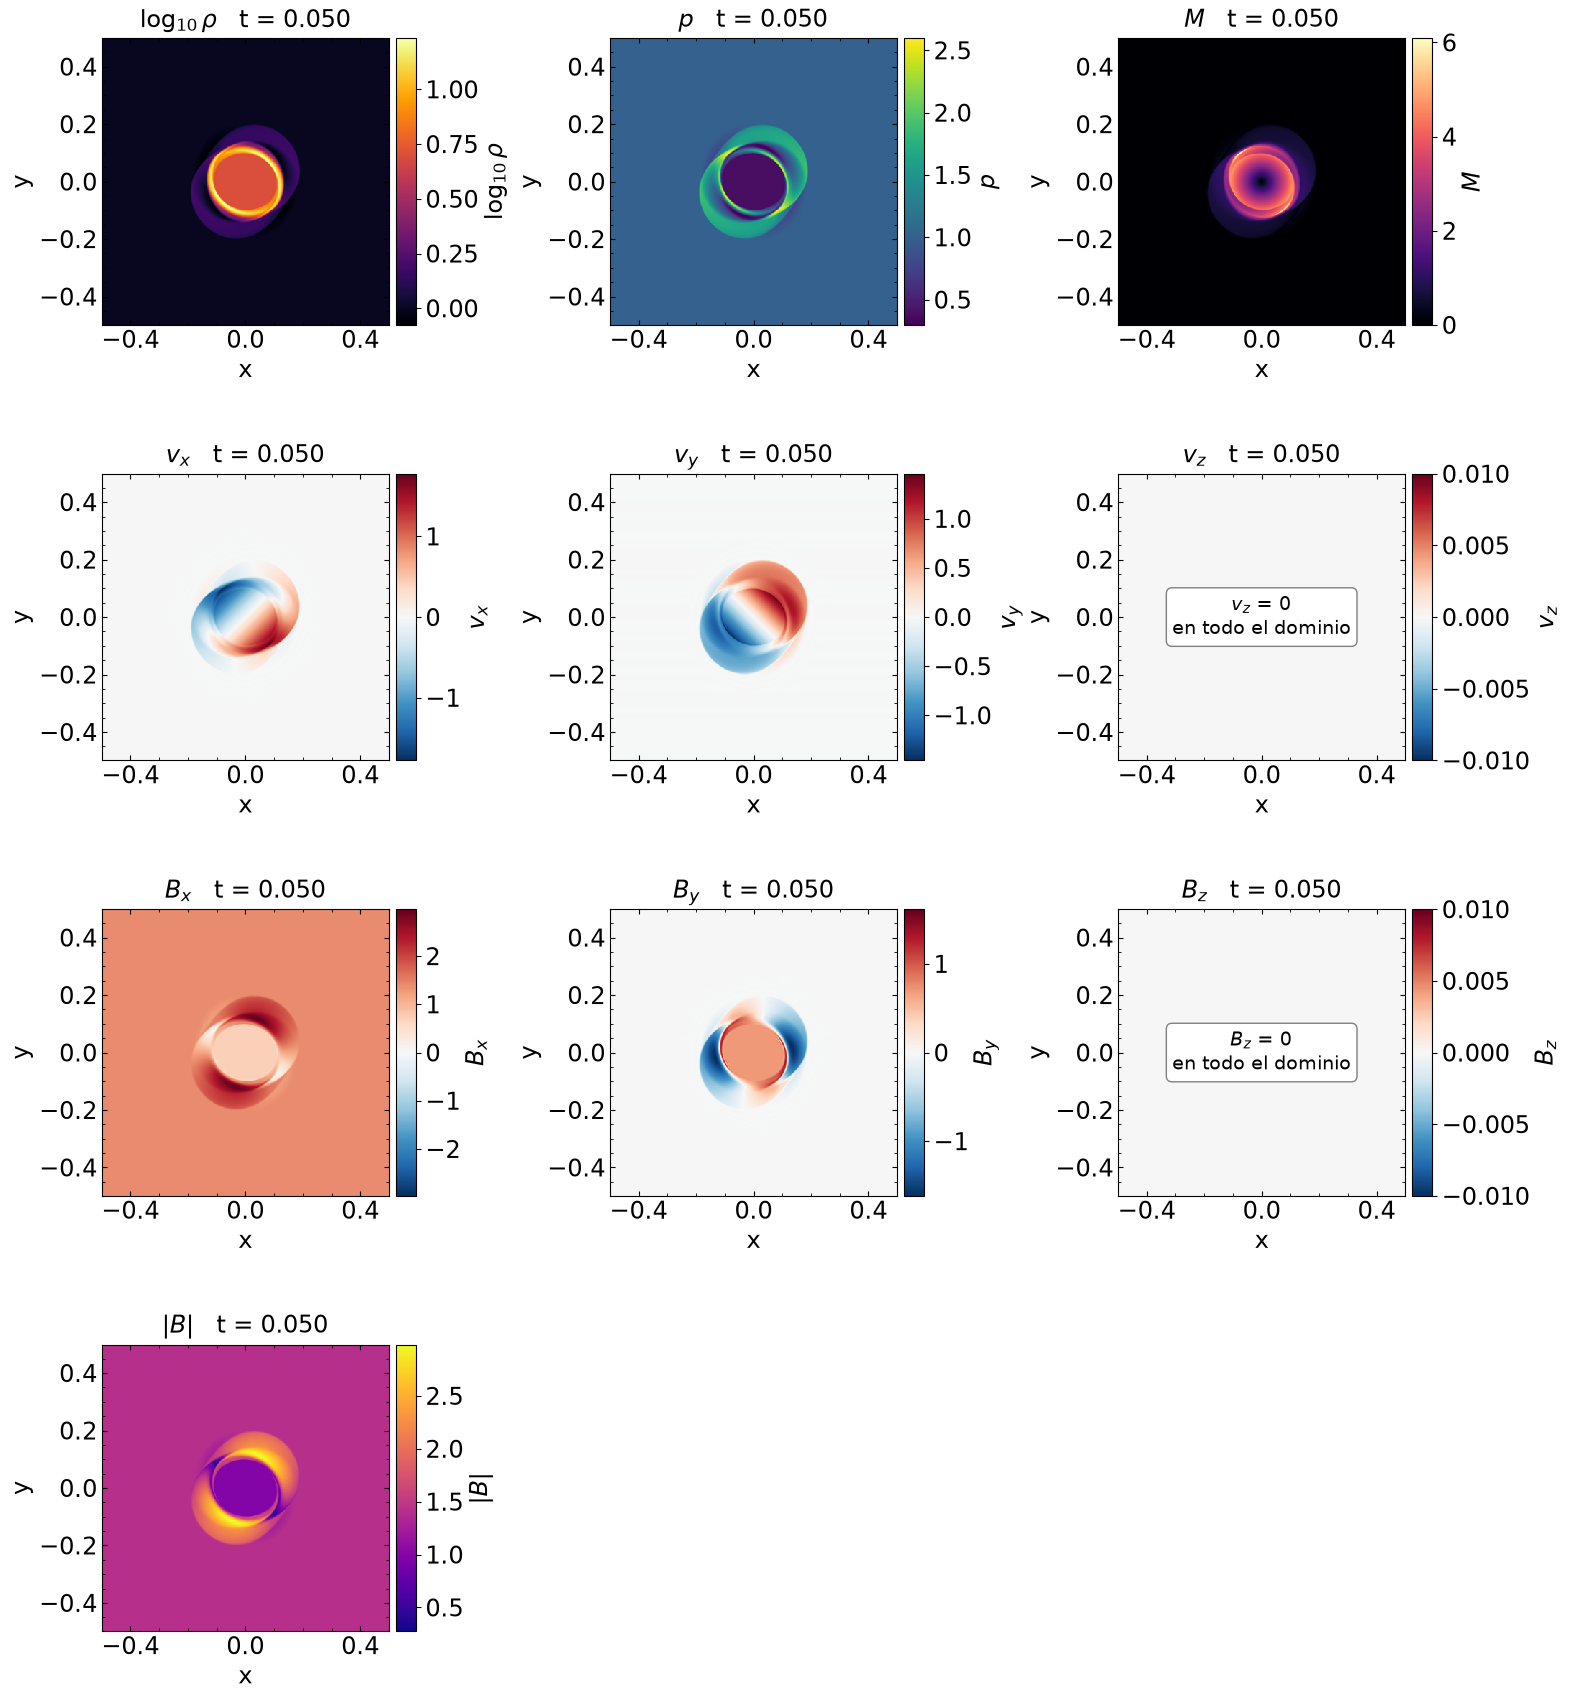

In [6]:
figura(PL[1], "pluto_rotor_0001.png")



#### 3.4.3 Etapa intermedia, $t\approx0.10$

La siguiente figura muestra la salida 2:

Image class created at nwin 1


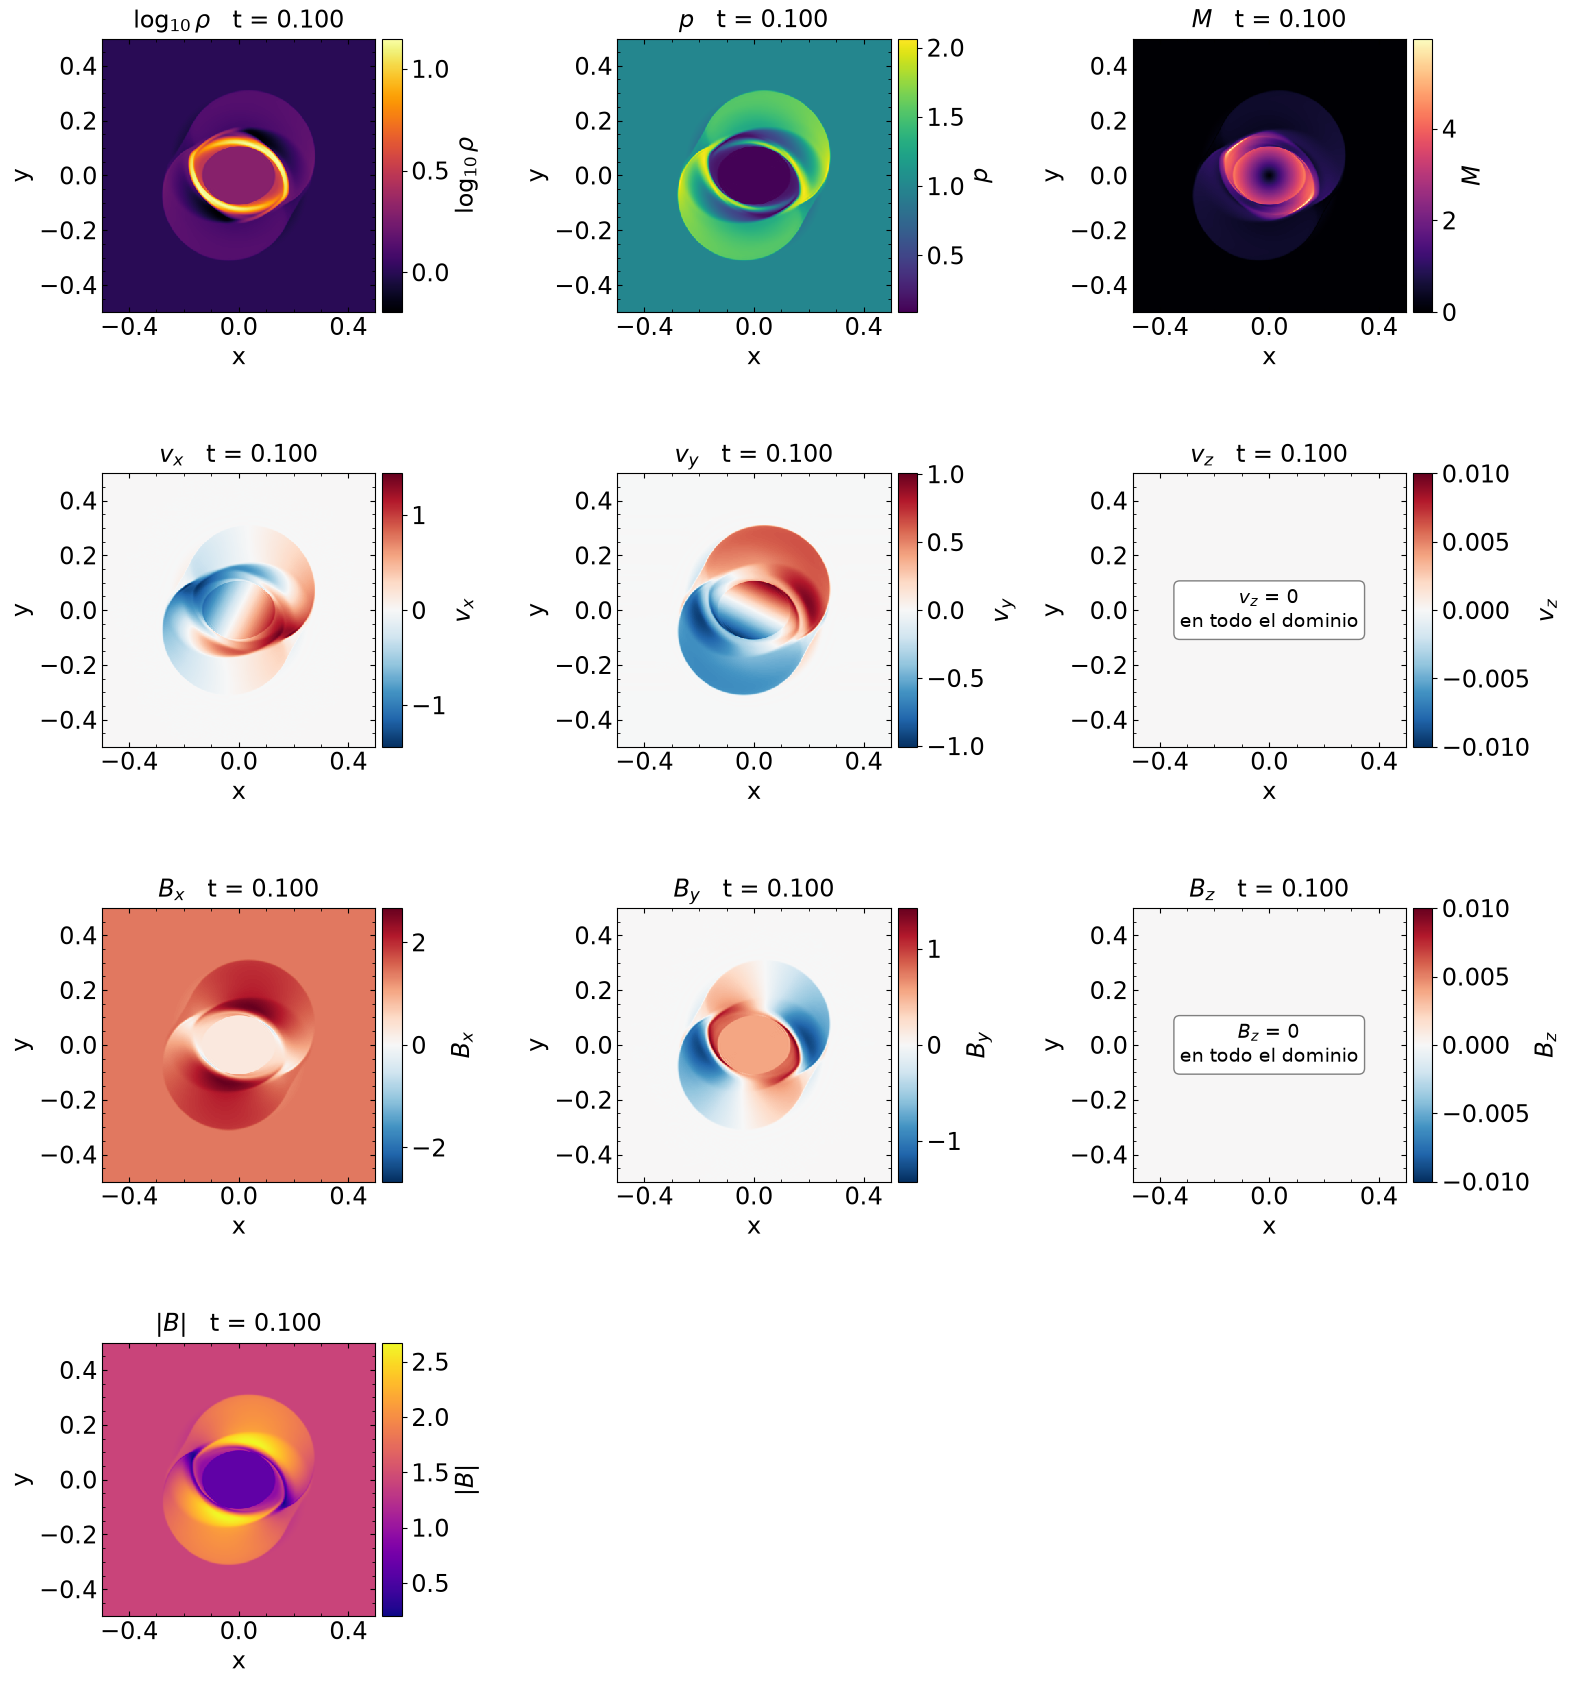

In [7]:
figura(PL[2], "pluto_rotor_0002.png")

#### 3.4.4 Estado final, $t=0.15$

La siguiente figura muestra el estado final:

Image class created at nwin 1


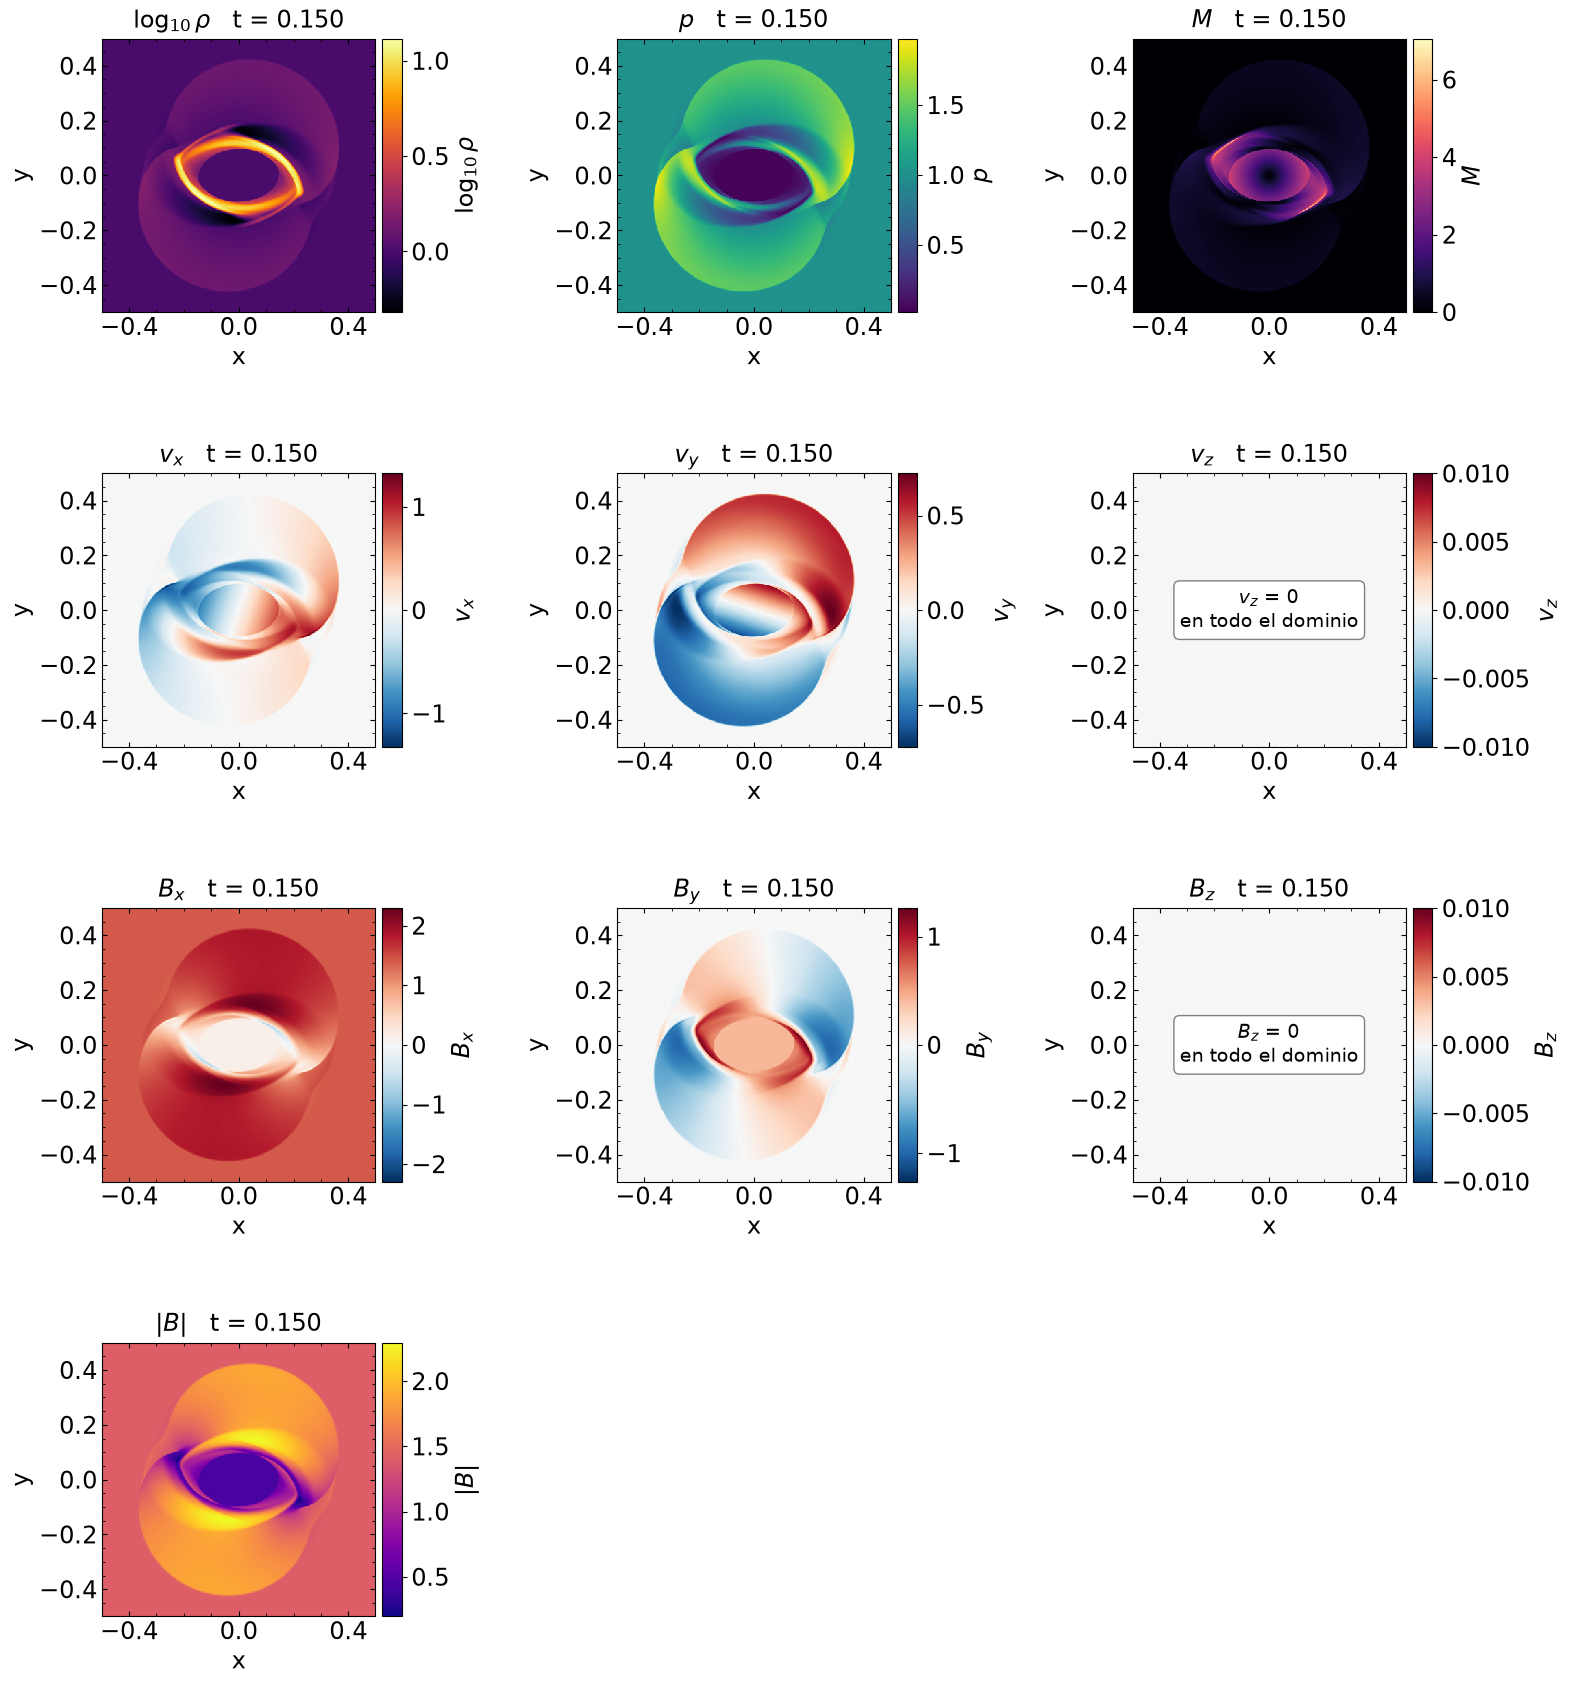

In [8]:
figura(PL[3], "pluto_rotor_0003.png")

La celda siguiente calcula los extremos, la masa y las energías de cada salida, que resumen las tablas de las secciones 3.4.6 y 3.4.7.

In [9]:
def resumen(f):
    """Extremos, masa, energías y máx |div B| de un estado."""
    dx, dy = f["x"][1] - f["x"][0], f["y"][1] - f["y"][0]
    dA = dx * dy
    v2 = f["vx1"]**2 + f["vx2"]**2 + f["vx3"]**2
    if "Bx1s" in f:      # PLUTO: B en las caras (transporte restringido en caras)
        divb = (f["Bx1s"][1:, :] - f["Bx1s"][:-1, :]) / dx + (f["Bx2s"][:, 1:] - f["Bx2s"][:, :-1]) / dy
    else:                # solver en Python: forma en las esquinas que conserva el flux-CT de Tóth
        bx, by = f["Bx1"], f["Bx2"]
        divb = ((bx[1:, 1:] + bx[1:, :-1] - bx[:-1, 1:] - bx[:-1, :-1]) / (2 * dx)
                + (by[1:, 1:] + by[:-1, 1:] - by[1:, :-1] - by[:-1, :-1]) / (2 * dy))
    ek, em, et = (0.5 * f["rho"] * v2).sum() * dA, (0.5 * f["bmag"]**2).sum() * dA, (f["prs"] / (GAMMA - 1)).sum() * dA
    return dict(t=f["t"], rmin=f["rho"].min(), rmax=f["rho"].max(), pmin=f["prs"].min(), pmax=f["prs"].max(),
                mach=f["mach"].max(), bmax=f["bmag"].max(), masa=f["rho"].sum() * dA, ek=ek, em=em, et=et,
                etot=ek + em + et, divb=np.abs(divb).max())

def tabla_evolucion(estados, titulo):
    print(titulo)
    print(" n       t    rho_min  rho_max   p_min   p_max   Mach  |B|max     masa     E_cin   E_mag   E_term   E_total")
    for n, f in estados.items():
        r = resumen(f)
        print(f"{n:2d} {r['t']:.5f} {r['rmin']:8.4f} {r['rmax']:8.4f} {r['pmin']:7.4f} {r['pmax']:7.4f} {r['mach']:6.3f} "
              f"{r['bmax']:7.4f} {r['masa']:.6f} {r['ek']:7.4f} {r['em']:7.4f} {r['et']:7.4f} {r['etot']:.6f}")
    r0, r1 = resumen(estados[0]), resumen(estados[max(estados)])
    perdida = r0["ek"] - r1["ek"]
    print(f"Caída de E_cin: {100 * perdida / r0['ek']:.0f} %; de lo perdido, {100 * (r1['em'] - r0['em']) / perdida:.0f} % pasa a "
          f"energía magnética y {100 * (r1['et'] - r0['et']) / perdida:.0f} % a térmica.")

tabla_evolucion(PL, "PLUTO 400²")

PLUTO 400²
 n       t    rho_min  rho_max   p_min   p_max   Mach  |B|max     masa     E_cin   E_mag   E_term   E_total
 0 0.00000   1.0000  10.0000  1.0000  1.0000  5.333  1.4105 1.327265  0.3643  0.9947  2.5000 3.858995
 1 0.04985   0.8394  17.1030  0.2971  2.5966  6.088  2.9838 1.327265  0.2844  1.0527  2.5220 3.858995
 2 0.09990   0.6373  14.0575  0.0904  2.0643  5.959  2.6697 1.327265  0.1845  1.1100  2.5645 3.858995
 3 0.15000   0.4810  13.0479  0.0198  1.9742  7.054  2.2927 1.327265  0.1290  1.1322  2.5978 3.858995
Caída de E_cin: 65 %; de lo perdido, 58 % pasa a energía magnética y 42 % a térmica.


#### 3.4.5 Descripción de la evolución

Las estructuras que se describen se ven en las figuras de las secciones 3.4.1 a 3.4.4, y los valores numéricos salen de la celda anterior, que calcula para cada salida los extremos, la masa y las energías; las tablas de las secciones 3.4.6 y 3.4.7 los recogen.

**Estado inicial, $t=0$ (figura de la sección 3.4.1).** El disco denso destaca sobre el medio uniforme. La presión y $B_x$ son uniformes, y el mapa de velocidades muestra una rotación rígida. El Mach máximo es 5.333, cerca del borde del disco.

**Primera etapa, $t\approx0.05$ (figura de la sección 3.4.2).** El giro comprime el gas en el borde del disco. La densidad máxima sube de 10 a 17.1, y $|\mathbf{B}|$ alcanza 2.98, el mayor valor de las cuatro salidas. Ya aparece $B_y$, que era nulo: las líneas de campo están siendo arrastradas por el disco.

**Etapa intermedia, $t\approx0.10$ (figura de la sección 3.4.3).** La perturbación se expande más hacia los lados perpendiculares al campo inicial. El disco deja de ser circular, y el centro queda con presión y $|\mathbf{B}|$ menores que los del entorno.

**Estado final, $t=0.15$ (figura de la sección 3.4.4).** El gas denso forma un anillo elíptico y girado que rodea una región central de baja presión. Fuera de él, la perturbación tiene un frente nítido. El Mach máximo, 7.054, aparece en una región muy rarificada, con $p=0.0198$: allí $c_s$ es pequeña, de modo que el valor alto se debe más a la baja presión que a una velocidad mayor.

Los paneles de $v_z$ y $B_z$ no muestran estructura porque ambas variables valen exactamente cero, como indica la nota dentro de cada panel. Su escala de $\pm0.01$ solo se usa para poder dibujarlos. Lo mismo ocurre en $t=0$ con los campos que empiezan uniformes.

#### 3.4.6 Evolución de las cantidades principales (400²)

La siguiente tabla muestra los extremos de las variables en cada salida:

| Salida | $t$ | $\rho$ mín | $\rho$ máx | $p$ mín | $p$ máx | Mach máx | $\lvert\mathbf{B}\rvert$ máx |
|---|---|---|---|---|---|---|---|
| 0 | 0.00000 | 1.0000 | 10.0000 | 1.0000 | 1.0000 | 5.333 | 1.4105 |
| 1 | 0.04985 | 0.8394 | 17.1030 | 0.2971 | 2.5966 | 6.088 | 2.9838 |
| 2 | 0.09990 | 0.6373 | 14.0575 | 0.0904 | 2.0643 | 5.959 | 2.6697 |
| 3 | 0.15000 | 0.4810 | 13.0479 | 0.0198 | 1.9742 | 7.054 | 2.2927 |

#### 3.4.7 Balance de energía: el frenado magnético

La siguiente tabla muestra cómo se reparte la energía en cada salida, y la figura que sigue muestra cuánto cambia cada forma de energía respecto de $t=0$:

| $t$ | $E_\mathrm{cin}$ | $E_\mathrm{mag}$ | $E_\mathrm{term}$ | $E_\mathrm{total}$ |
|---|---|---|---|---|
| 0.00000 | 0.3643 | 0.9947 | 2.5000 | 3.858995 |
| 0.04985 | 0.2844 | 1.0527 | 2.5220 | 3.858995 |
| 0.09990 | 0.1845 | 1.1100 | 2.5645 | 3.858995 |
| 0.15000 | 0.1290 | 1.1322 | 2.5978 | 3.858995 |

La energía cinética cae un 65 % hasta $t=0.15$. De los 0.2353 perdidos, cerca del 58 % pasa a energía magnética y el 42 % a energía térmica. Este es el frenado descrito en la sección 1.1, y la energía total se mantiene. En la figura, la curva de la energía cinética baja lo mismo que suben juntas la magnética y la térmica, y la total queda en cero.

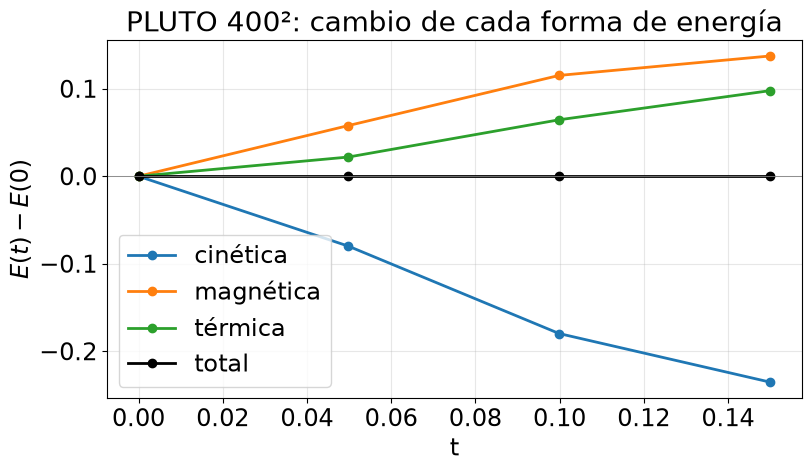

In [10]:
# Cambio de cada forma de energía respecto de t = 0 en las cuatro salidas de PLUTO 400²
R = [resumen(PL[n]) for n in sorted(PL)]
t = [r["t"] for r in R]
fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
for clave, etiqueta, color in (("ek", "cinética", "tab:blue"), ("em", "magnética", "tab:orange"),
                               ("et", "térmica", "tab:green"), ("etot", "total", "k")):
    ax.plot(t, [r[clave] - R[0][clave] for r in R], "o-", color=color, lw=2, label=etiqueta)
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("t"); ax.set_ylabel(r"$E(t) - E(0)$"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("PLUTO 400²: cambio de cada forma de energía")
fig.savefig(FIGURAS / "pluto_energia.png", dpi=150)
plt.show()

### 3.5 Verificación de la corrida

La celda siguiente hace las comprobaciones de la corrida de 400² en $t=0.15$:

- **Conservación:** masa y energía total en el dominio, y el valor máximo de $\lvert\nabla\cdot\mathbf{B}\rvert$, calculado con el campo en las caras de la malla.
- **Componentes en $z$:** que $v_z$ y $B_z$ sigan siendo exactamente cero (sección 2.1).
- **Simetría:** que la solución no cambie al girarla 180° alrededor del centro, como el estado inicial.
- **Fronteras:** cuánto se aparta $\rho$ de 1 en las celdas del borde, para saber si las perturbaciones llegaron a él.
- **Velocidad del frente:** hasta dónde llega la región perturbada ($\lvert p-1\rvert>10^{-3}$) a lo largo de los ejes, y la estimación lineal correspondiente.
- **Presión negativa:** cuántos avisos de presión negativa registró PLUTO en `run.log` en cada malla.

In [11]:
def verificar(f, nombre):
    """Comprobaciones de la sección 3.5 (y 4.3) sobre el estado final."""
    r = resumen(f)
    print(f"== {nombre}, t = {f['t']:.3f} ==")
    print(f"masa = {r['masa']:.6f}   E_total = {r['etot']:.6f}   max|div B| = {r['divb']:.2e}")
    print(f"max|v_z| = {np.abs(f['vx3']).max()}   max|B_z| = {np.abs(f['Bx3']).max()}")
    sim = max(np.abs(f[k] - s * f[k][::-1, ::-1]).max()                 # rotación de 180 grados
              for k, s in (("rho", 1), ("prs", 1), ("vx1", -1), ("vx2", -1), ("Bx1", 1), ("Bx2", 1)))
    print(f"simetría de 180 grados: diferencia máxima = {sim:.1e}")
    borde = np.concatenate([f["rho"][0], f["rho"][-1], f["rho"][:, 0], f["rho"][:, -1]])
    print(f"max|rho - 1| en los bordes = {np.abs(borde - 1).max():.1e}")
    x, y = f["x"], f["y"]
    for eje, c, e in (("y (x ~ 0)", y, f["prs"][np.argmin(np.abs(x)), :]), ("x (y ~ 0)", x, f["prs"][:, np.argmin(np.abs(y))])):
        print(f"frente (|p - 1| > 1e-3) a lo largo del eje {eje}: llega a {np.abs(c[np.abs(e - 1) > 1e-3]).max():.3f}")

def presiones_negativas(N):
    """Cuenta los avisos 'negative p(E)' de PLUTO en run.log."""
    with open(RAIZ / f"pluto_run_{N}" / "run.log") as log:
        return sum("negative p(E)" in l for l in log)

verificar(PL[3], "PLUTO 400²")
print("avisos de presión negativa en run.log:", {N: presiones_negativas(N) for N in MALLAS})
cs, vA = lambda rho: np.sqrt(GAMMA * 1.0 / rho), lambda rho: (5 / np.sqrt(4 * np.pi)) / np.sqrt(rho)
print(f"estimación lineal del frente: perpendicular a B {0.115 + 0.15 * np.hypot(cs(1), vA(1)):.3f}, "
      f"a lo largo de B {0.115 + 0.15 * max(cs(1), vA(1)):.3f}")

== PLUTO 400², t = 0.150 ==
masa = 1.327265   E_total = 3.858995   max|div B| = 1.20e-11
max|v_z| = 0.0   max|B_z| = 0.0
simetría de 180 grados: diferencia máxima = 2.2e-11
max|rho - 1| en los bordes = 4.6e-14
frente (|p - 1| > 1e-3) a lo largo del eje y (x ~ 0): llega a 0.426
frente (|p - 1| > 1e-3) a lo largo del eje x (y ~ 0): llega a 0.356
avisos de presión negativa en run.log: {100: 0, 200: 0, 400: 0}
estimación lineal del frente: perpendicular a B 0.391, a lo largo de B 0.327


La siguiente tabla resume las comprobaciones:

| Comprobación (400²) | Resultado | Lectura |
|---|---|---|
| Masa total | 1.327265 en las cuatro salidas | Se conserva dentro de los decimales mostrados |
| Energía total | 3.858995 en las cuatro salidas | Se conserva dentro de los decimales mostrados |
| $\max\lvert\nabla\cdot\mathbf{B}\rvert$ | $1.20\times10^{-11}$ en $t=0.15$ | Prácticamente nula, frente al tamaño del campo |
| $\max\lvert v_z\rvert$ y $\max\lvert B_z\rvert$ | 0 exacto | Coincide con la sección 2.1 |
| Simetría de 180° | Diferencia máxima $2.2\times10^{-11}$ | $\rho$, $p$, $v_x$, $v_y$, $B_x$, $B_y$ conservan la simetría del estado inicial |
| Bordes en $t=0.15$ | $\max\lvert\rho-1\rvert=4.6\times10^{-14}$ | Las perturbaciones aún no los alcanzan, así que `outflow` no afecta el resultado |
| Avisos en `run.log` | 0 presiones negativas | La corrida no necesitó corrección de presión |
| Repetición | 4 archivos `.dbl` idénticos byte a byte con otra corrida | Resultado reproducible con la misma configuración (comprobado al repetir la corrida durante el proyecto; el notebook no lo repite) |

**Velocidad del frente.** En la teoría lineal, la onda más rápida viaja con $c_f=\sqrt{c_s^2+v_A^2}\approx1.84$ perpendicular a $\mathbf{B}$ y con $\max(c_s,v_A)\approx1.41$ a lo largo de $\mathbf{B}$. Partiendo de $r_1=0.115$, se estiman alcances de 0.391 y 0.327. Medido con $\lvert p-1\rvert>10^{-3}$, el frente llega a 0.426 sobre el eje $y$ y a 0.356 sobre el eje $x$. Son alrededor de un 9 % mayores, y reproducen la anisotropía esperada; es solo una estimación lineal, que no incluye la amplitud finita ni la rotación.

### 3.6 Efecto de la resolución

Se repitió la simulación con 100² y 200² celdas, cambiando solo `X1-grid` y `X2-grid` en `pluto.ini`, sin recompilar. Estos resultados, en $t=0.15$, son la base del estudio de convergencia de la sección 5.3. La celda siguiente los resume.

In [12]:
def log_pluto(N):
    """Pasos y tiempo de cómputo de la corrida de PLUTO, leídos de run.log."""
    texto = (RAIZ / f"pluto_run_{N}" / "run.log").read_text()
    pasos = int(re.findall(r"step:(\d+);", texto)[-1]) + 1          # PLUTO numera los pasos desde 0
    tiempo = re.search(r"Elapsed time\s+(\S+)", texto).group(1)
    return pasos, tiempo

print("   N      dx    pasos  tiempo        rho_min  rho_max   p_min   p_max   Mach     masa     E_total")
for N in MALLAS:
    r, (pasos, tiempo) = resumen(PLf[N]), log_pluto(N)
    print(f"{N:4d} {1 / N:.5f} {pasos:6d}  {tiempo:12s} {r['rmin']:8.4f} {r['rmax']:8.4f} {r['pmin']:7.4f} {r['pmax']:7.4f} "
          f"{r['mach']:6.3f} {r['masa']:.6f} {r['etot']:.6f}")

   N      dx    pasos  tiempo        rho_min  rho_max   p_min   p_max   Mach     masa     E_total
 100 0.01000    190  0d:0h:0m:1s    0.6091  11.6368  0.0329  1.8239  4.187 1.326492 3.858206
 200 0.00500    320  0d:0h:0m:7s    0.5284  12.4997  0.0288  1.9247  4.642 1.327329 3.859012
 400 0.00250    590  0d:0h:1m:9s    0.4810  13.0479  0.0198  1.9742  7.054 1.327265 3.858995


La siguiente tabla compara las tres mallas:

| $N$ | $\Delta x$ | Pasos | Tiempo | $\rho$ mín | $\rho$ máx | $p$ mín | $p$ máx | Mach máx | Masa | $E_\mathrm{total}$ |
|---|---|---|---|---|---|---|---|---|---|---|
| 100 | 0.01000 | 190 | 1 s | 0.6091 | 11.6368 | 0.0329 | 1.8239 | 4.187 | 1.326492 | 3.858206 |
| 200 | 0.00500 | 320 | 7 s | 0.5284 | 12.4997 | 0.0288 | 1.9247 | 4.642 | 1.327329 | 3.859012 |
| 400 | 0.00250 | 590 | 1 min 9 s | 0.4810 | 13.0479 | 0.0198 | 1.9742 | 7.054 | 1.327265 | 3.858995 |

**Lectura de la tabla.**

- $\rho$ máx y $p$ máx aumentan y sus cambios se reducen, porque una malla más fina difunde menos los picos y los choques.
- La masa y la energía difieren un poco entre mallas porque cada una muestrea de forma distinta el borde del disco. Dentro de cada malla, la masa no cambia en los seis decimales mostrados.
- El Mach máximo cambia mucho entre mallas: depende de $p$ mín, un valor local en una región muy rarificada. Por eso no sirve como medida de la solución.

## 4. Parte II: reproducción con un solver en Python

### 4.1 Diseño del solver

El solver parte del esquema de **Lax-Wendroff**, llevado a dos dimensiones en su forma de dos pasos de Richtmyer. Es un esquema de diferencias centradas de segundo orden: no resuelve problemas de Riemann, no reconstruye estados en las caras y no usa limitadores.

Con $U$ el vector de variables conservadas y $F$, $G$ sus flujos físicos en $x$ y en $y$, cada paso tiene dos etapas:

1. **Predictor.** Se estima el estado a medio paso de tiempo en las esquinas de las celdas, promediando las cuatro celdas vecinas y restando la diferencia de flujos:
$$U^{n+\frac12}_{i+\frac12,j+\frac12}=\overline{U}^{\,n}-\frac{\Delta t}{2\Delta x}\,\overline{\delta_x F}^{\,n}-\frac{\Delta t}{2\Delta y}\,\overline{\delta_y G}^{\,n},$$
donde las barras indican promedios sobre las dos filas o columnas vecinas.

2. **Corrector.** Con los flujos calculados en las cuatro esquinas de cada celda se avanza el paso completo en los centros:
$$U^{n+1}_{i,j}=U^n_{i,j}-\frac{\Delta t}{\Delta x}\,\overline{\delta_x F}^{\,n+\frac12}-\frac{\Delta t}{\Delta y}\,\overline{\delta_y G}^{\,n+\frac12}.$$

El flujo en $y$ se obtiene con la misma función que el de $x$, intercambiando las componentes $x\leftrightarrow y$ de la velocidad y del campo.

**Viscosidad artificial.** Al resultado se le suma un término difusivo con un coeficiente adimensional $\nu$:
$$U^{n+1}_{i,j}\;\leftarrow\;U^{n+1}_{i,j}+\nu\left(U_{i+1,j}+U_{i-1,j}+U_{i,j+1}+U_{i,j-1}-4U_{i,j}\right)^n.$$
Con $\nu=0$ el esquema es el Lax-Wendroff sin modificar. La sección 4.3 muestra por qué hizo falta $\nu>0$ y cómo se eligió su valor.

**Paso de tiempo.** Condición CFL de un esquema 2D sin separar direcciones, con la velocidad magnetosónica rápida $c_f$:
$$\Delta t=\frac{\mathrm{CFL}}{\max_{i,j}\left(\dfrac{\lvert v_x\rvert+c_{f,x}}{\Delta x}+\dfrac{\lvert v_y\rvert+c_{f,y}}{\Delta y}\right)},\qquad \mathrm{CFL}=0.4.$$
PLUTO usa la mitad de esa suma (`Src/Time_Stepping/update_stage.c`), de modo que con el mismo número CFL da pasos más largos.

**Fronteras.** `outflow`: se añade una celda fantasma por lado, copia de la última celda (`np.pad`).

**Divergencia de $\mathbf{B}$.** El solver no tiene ningún mecanismo especial para $\nabla\cdot\mathbf{B}$. Para medirla se usa la divergencia en las esquinas de las celdas,
$$(\nabla\cdot\mathbf{B})_{i+\frac12,j+\frac12}=\frac{B_{x,i+1,j}+B_{x,i+1,j+1}-B_{x,i,j}-B_{x,i,j+1}}{2\Delta x}+\frac{B_{y,i,j+1}+B_{y,i+1,j+1}-B_{y,i,j}-B_{y,i+1,j}}{2\Delta y},$$
que es distinta de la de PLUTO, donde $\mathbf{B}$ vive en las caras. Las secciones 4.2 y 4.4 muestran que, en la práctica, esta divergencia se mantiene en el nivel del redondeo mientras las perturbaciones no llegan a las fronteras.

**Diferencias con PLUTO.** La siguiente tabla resume en qué se distingue el solver de la configuración de PLUTO:

| Aspecto | PLUTO (configuración #01) | Solver en Python |
|---|---|---|
| Tipo de esquema | Godunov: volúmenes finitos con solver de Riemann HLLD | Diferencias centradas: Lax-Wendroff de dos pasos |
| Choques | Limitador MC: sin parámetros ajustables | Viscosidad artificial con $\nu$ elegido (sección 4.3) |
| $\nabla\cdot\mathbf{B}$ | Transporte restringido, con $\mathbf{B}$ en las caras | Sin mecanismo especial; se mide en las esquinas |
| Regla de $\Delta t$ | $\frac12\sum_d(\lvert v_d\rvert+c_{f,d})/\Delta_d$ | $\sum_d(\lvert v_d\rvert+c_{f,d})/\Delta_d$ |
| Presión $\le0$ | Fija $p=10^{-12}$ y recalcula la energía | Piso $p=10^{-10}$ en las primitivas; con el $\nu$ elegido no se activa (sección 4.4) |
| Implementación | C compilado | Python con NumPy |

**Variables y funciones físicas.** Conversión entre variables primitivas y conservadas, flujos físicos en $x$ y en $y$ y velocidad magnetosónica rápida.

In [13]:
import numpy as np

# Variables en arreglos de forma (8, nx, ny), con índices [variable, x, y]:
#   primitivas   V = (rho, vx, vy, vz, Bx, By, Bz, p)
#   conservadas  U = (rho, rho*vx, rho*vy, rho*vz, Bx, By, Bz, E)
P_MIN = 1e-10                    # piso de seguridad para la presión
PERM = [0, 2, 1, 3, 5, 4, 6, 7]  # intercambia las componentes x <-> y de la velocidad y del campo


def prim_a_cons(V, gam):
    """Variables primitivas -> conservadas. E = p/(gam-1) + rho v^2/2 + B^2/2 (ecuación 5)."""
    rho, vx, vy, vz, bx, by, bz, p = V
    U = np.empty_like(V)
    U[0] = rho
    U[1], U[2], U[3] = rho * vx, rho * vy, rho * vz
    U[4], U[5], U[6] = bx, by, bz
    U[7] = p / (gam - 1) + 0.5 * rho * (vx**2 + vy**2 + vz**2) + 0.5 * (bx**2 + by**2 + bz**2)
    return U


def presion(U, gam):
    """Presión a partir de las conservadas: se restan de E las energías cinética y magnética."""
    cin = 0.5 * (U[1]**2 + U[2]**2 + U[3]**2) / U[0]
    mag = 0.5 * (U[4]**2 + U[5]**2 + U[6]**2)
    return (gam - 1) * (U[7] - cin - mag)


def cons_a_prim(U, gam):
    """Variables conservadas -> primitivas, con un piso de seguridad para la presión."""
    V = np.empty_like(U)
    V[0] = U[0]
    V[1], V[2], V[3] = U[1] / U[0], U[2] / U[0], U[3] / U[0]
    V[4], V[5], V[6] = U[4], U[5], U[6]
    V[7] = np.maximum(presion(U, gam), P_MIN)
    return V


def flujo_x(V, gam):
    """Flujo físico en la dirección x de las ecuaciones (1)-(4)."""
    rho, vx, vy, vz, bx, by, bz, p = V
    B2 = bx**2 + by**2 + bz**2
    pt = p + 0.5 * B2                                     # presión total
    E = p / (gam - 1) + 0.5 * rho * (vx**2 + vy**2 + vz**2) + 0.5 * B2
    vB = vx * bx + vy * by + vz * bz
    F = np.empty_like(V)
    F[0] = rho * vx
    F[1] = rho * vx * vx - bx * bx + pt
    F[2] = rho * vx * vy - bx * by
    F[3] = rho * vx * vz - bx * bz
    F[4] = 0.0                                            # la componente normal no tiene flujo
    F[5] = vx * by - vy * bx
    F[6] = vx * bz - vz * bx
    F[7] = (E + pt) * vx - bx * vB
    return F


def flujos(V, gam):
    """Flujos físicos en x (F) y en y (G). G se obtiene con flujo_x intercambiando las componentes x <-> y."""
    return flujo_x(V, gam), flujo_x(V[PERM], gam)[PERM]


def vel_rapida_x(V, gam):
    """Velocidad magnetosónica rápida en la dirección x."""
    rho, bx, p = V[0], V[4], V[7]
    a2 = gam * p / rho                                    # sonido al cuadrado
    b2 = (V[4]**2 + V[5]**2 + V[6]**2) / rho              # Alfvén al cuadrado
    s = a2 + b2
    return np.sqrt(0.5 * (s + np.sqrt(np.maximum(s**2 - 4 * a2 * bx**2 / rho, 0.0))))

**Paso de Lax-Wendroff, paso de tiempo y divergencia de $\mathbf{B}$.** El argumento `nu` es la viscosidad artificial; con `nu = 0` el esquema es el Lax-Wendroff de dos pasos sin modificar.

In [14]:
def rellenar(U, borde):
    """Añade una celda fantasma por lado: 'outflow' copia la última celda; 'periodico' da la vuelta."""
    return np.pad(U, ((0, 0), (1, 1), (1, 1)), mode="edge" if borde == "outflow" else "wrap")


def paso_lax_wendroff(U, dt, dx, dy, gam, nu=0.0, borde="outflow"):
    """Un paso de Lax-Wendroff de dos pasos (Richtmyer) en 2D, más una viscosidad artificial nu."""
    Up = rellenar(U, borde)
    F, G = flujos(cons_a_prim(Up, gam), gam)
    # 1) predictor: estado a medio paso de tiempo en las esquinas de las celdas
    Ue = 0.25 * (Up[:, :-1, :-1] + Up[:, 1:, :-1] + Up[:, :-1, 1:] + Up[:, 1:, 1:]) \
        - dt / (4 * dx) * (F[:, 1:, :-1] + F[:, 1:, 1:] - F[:, :-1, :-1] - F[:, :-1, 1:]) \
        - dt / (4 * dy) * (G[:, :-1, 1:] + G[:, 1:, 1:] - G[:, :-1, :-1] - G[:, 1:, :-1])
    Fe, Ge = flujos(cons_a_prim(Ue, gam), gam)
    # 2) corrector: paso completo en los centros con los flujos de las cuatro esquinas
    Un = U - dt / (2 * dx) * (Fe[:, 1:, 1:] + Fe[:, 1:, :-1] - Fe[:, :-1, 1:] - Fe[:, :-1, :-1]) \
           - dt / (2 * dy) * (Ge[:, 1:, 1:] + Ge[:, :-1, 1:] - Ge[:, 1:, :-1] - Ge[:, :-1, :-1])
    # 3) viscosidad artificial: nu por el laplaciano discreto (suma de los 4 vecinos menos 4 veces la celda)
    lap = Up[:, 2:, 1:-1] + Up[:, :-2, 1:-1] + Up[:, 1:-1, 2:] + Up[:, 1:-1, :-2] - 4 * U
    return Un + nu * lap


def paso_dt(U, gam, dx, dy, cfl):
    """dt = CFL / max[(|vx| + cf_x)/dx + (|vy| + cf_y)/dy]."""
    V = cons_a_prim(U, gam)
    cx, cy = vel_rapida_x(V, gam), vel_rapida_x(V[PERM], gam)
    return cfl / np.max((np.abs(V[1]) + cx) / dx + (np.abs(V[2]) + cy) / dy)


def div_b(bx, by, dx, dy):
    """Divergencia de B en las esquinas de las celdas (promedio de diferencias en las dos filas o columnas vecinas)."""
    return ((bx[1:, 1:] + bx[1:, :-1] - bx[:-1, 1:] - bx[:-1, :-1]) / (2 * dx)
            + (by[1:, 1:] + by[:-1, 1:] - by[1:, :-1] - by[:-1, :-1]) / (2 * dy))

### 4.2 Validación del solver

Antes del rotor, la celda siguiente ejecuta dos pruebas con el esquema sin viscosidad ($\nu=0$): una onda de Alfvén, que es un flujo suave con solución exacta, y el tubo de choque de Brio y Wu, que tiene choques.

In [15]:
def onda_alfven(N, direccion, delta=0.1):
    """Onda de Alfvén circularmente polarizada (solución exacta) tras un periodo, sin viscosidad.
    Devuelve el error L1, max|div B| y el cambio relativo de la masa."""
    rho0, p0, b0, n = 1.0, 0.1, 1.0, 4
    nx, ny = (N, n) if direccion == "x" else (n, N)
    dx = dy = 1.0 / N
    X, Y = np.meshgrid((np.arange(nx) + 0.5) * dx, (np.arange(ny) + 0.5) * dy, indexing="ij")
    def exacta(t):
        fase = 2 * np.pi * ((X if direccion == "x" else Y) - b0 / np.sqrt(rho0) * t)
        a, b = delta * np.cos(fase), delta * np.sin(fase)
        V = np.zeros((8, nx, ny)); V[0], V[7] = rho0, p0
        if direccion == "x":
            V[2], V[3], V[5], V[6], V[4] = a, b, -a, -b, b0
        else:
            V[1], V[3], V[4], V[6], V[5] = a, b, -a, -b, b0
        return V
    U, t, T = prim_a_cons(exacta(0.0), 1.4), 0.0, np.sqrt(rho0) / b0
    masa0 = U[0].sum()
    while t < T - 1e-14:
        dt = min(paso_dt(U, 1.4, dx, dy, 0.4), T - t)
        U, t = paso_lax_wendroff(U, dt, dx, dy, 1.4, nu=0.0, borde="periodico"), t + dt
    V, Ve = cons_a_prim(U, 1.4), exacta(T)
    error = np.mean([np.abs(V[k] - Ve[k]).mean() for k in range(1, 7)])
    return error, np.abs(div_b(U[4], U[5], dx, dy)).max(), abs(U[0].sum() - masa0) / masa0

def brio_wu(direccion, N=200, T=0.1, g=2.0):
    """Tubo de choque de Brio y Wu (gamma = 2), sin viscosidad, orientado en x o girado 90 grados en el plano."""
    nx, ny = (N, 4) if direccion == "x" else (4, N)
    dx = dy = 2.0 / N
    c = (np.arange(N) + 0.5) * dx - 1.0
    izq = (c < 0)[:, None] if direccion == "x" else (c < 0)[None, :]
    V = np.zeros((8, nx, ny))
    V[0], V[7], V[6] = np.where(izq, 1.0, 0.125), np.where(izq, 1.0, 0.1), np.where(izq, 0.5, -0.5)
    bt = np.where(izq, 1.0, -1.0)
    if direccion == "x":
        V[4], V[5] = 0.75, bt
    else:
        V[5], V[4] = 0.75, -bt
    U, t, pmin = prim_a_cons(V, g), 0.0, np.inf
    while t < T - 1e-14:
        dt = min(paso_dt(U, g, dx, dy, 0.4), T - t)
        U, t = paso_lax_wendroff(U, dt, dx, dy, g, nu=0.0), t + dt
        pmin = min(pmin, presion(U, g).min())
    return cons_a_prim(U, g), pmin

# [1] flujo suave: convergencia frente a la solución exacta, en x y en y
ok = True
for d in ("x", "y"):
    res = [onda_alfven(N, d) for N in (16, 32, 64, 128)]
    err = np.array([e for e, _, _ in res])
    orden = np.log2(err[:-1] / err[1:])
    print(f"[1] Alfvén en {d}: L1 = " + ", ".join(f"{e:.3e}" for e in err) + "  | orden = " + ", ".join(f"{o:.2f}" for o in orden)
          + f"  | max|div B| = {max(b for _, b, _ in res):.1e}  | cambio de masa = {max(m for _, _, m in res):.1e}")
    ok &= orden[-1] > 1.9
# [2] choques: el mismo problema en x y girado a y debe dar el mismo resultado
(Wx, pmin_x), (Wy, pmin_y) = brio_wu("x"), brio_wu("y")
px, py = Wx[:, :, 1], Wy[:, 1, :]
e2 = np.abs(px - np.array([py[0], py[2], -py[1], py[3], py[5], -py[4], py[6], py[7]])).max()
print(f"[2] Brio-Wu en x frente a y: max|diferencia| = {e2:.2e}")
print(f"    sin viscosidad: rho en [{px[0].min():.4f}, {px[0].max():.4f}] (el estado inicial está en [0.125, 1]), "
      f"presión mínima durante la corrida = {pmin_x:.3f}")
print("RESULTADO:", "TODO OK" if (ok and e2 < 1e-12) else "FALLA")

[1] Alfvén en x: L1 = 6.524e-03, 1.652e-03, 4.138e-04, 1.035e-04  | orden = 1.98, 2.00, 2.00  | max|div B| = 8.9e-16  | cambio de masa = 6.7e-16


[1] Alfvén en y: L1 = 6.524e-03, 1.652e-03, 4.138e-04, 1.035e-04  | orden = 1.98, 2.00, 2.00  | max|div B| = 8.9e-16  | cambio de masa = 4.4e-16
[2] Brio-Wu en x frente a y: max|diferencia| = 1.69e-14
    sin viscosidad: rho en [0.1128, 1.1079] (el estado inicial está en [0.125, 1]), presión mínima durante la corrida = -2.034
RESULTADO: TODO OK


La siguiente tabla resume los resultados:

| Prueba | Qué verifica | Resultado |
|---|---|---|
| Onda de Alfvén circular | Convergencia frente a la solución exacta, en $x$ y en $y$ | Órdenes 1.98, 2.00 y 2.00; masa conservada hasta $7\times10^{-16}$ |
| Brio-Wu en $x$ y en $y$ | Simetría entre direcciones | Diferencia $1.69\times10^{-14}$ |
| Brio-Wu sin viscosidad | Comportamiento en choques | $\rho$ sube a 1.108 (por encima del valor inicial máximo, 1) y la presión llega a $-2.03$ |

En la onda de Alfvén, el error $L_1$ es $6.524\times10^{-3}$, $1.652\times10^{-3}$, $4.138\times10^{-4}$ y $1.035\times10^{-4}$ para $N=16$, 32, 64 y 128: el orden es 2, el esperado para Lax-Wendroff en un flujo suave, y $\max\lvert\nabla\cdot\mathbf{B}\rvert$ queda en $8.9\times10^{-16}$.

El tubo de choque muestra la limitación conocida del esquema: cerca de las discontinuidades aparecen oscilaciones que crean valores nuevos, una densidad mayor que la inicial y una presión negativa, que no tiene sentido físico. En una dimensión el cálculo sobrevive gracias al piso de presión; la sección siguiente muestra qué ocurre en el rotor.

### 4.3 Resultado preliminar y elección de la viscosidad

Como primer intento, se ejecutó el rotor en una malla de 200² con el esquema sin modificar ($\nu=0$). Después, viendo el resultado, se repitió con valores crecientes de $\nu$. La celda siguiente hace las seis corridas, aplica el criterio de elección descrito más abajo y dibuja la figura de esta sección.

   nu     ¿llega a t = 0.15?   primera p < 0      rho mín   rho máx  (en el último instante calculado)
  0.000   no, falla en t = 0.0330  t = 0.0245          0.000   20.009
  0.005   sí                       t = 0.0306          0.159   10.045
  0.010   sí                       t = 0.0853          0.733    8.875
  0.015   sí                       nunca               0.785    7.984
  0.020   sí                       nunca               0.824    7.348
  0.050   sí                       nunca               0.963    5.445

Viscosidad elegida: NU = 0.015


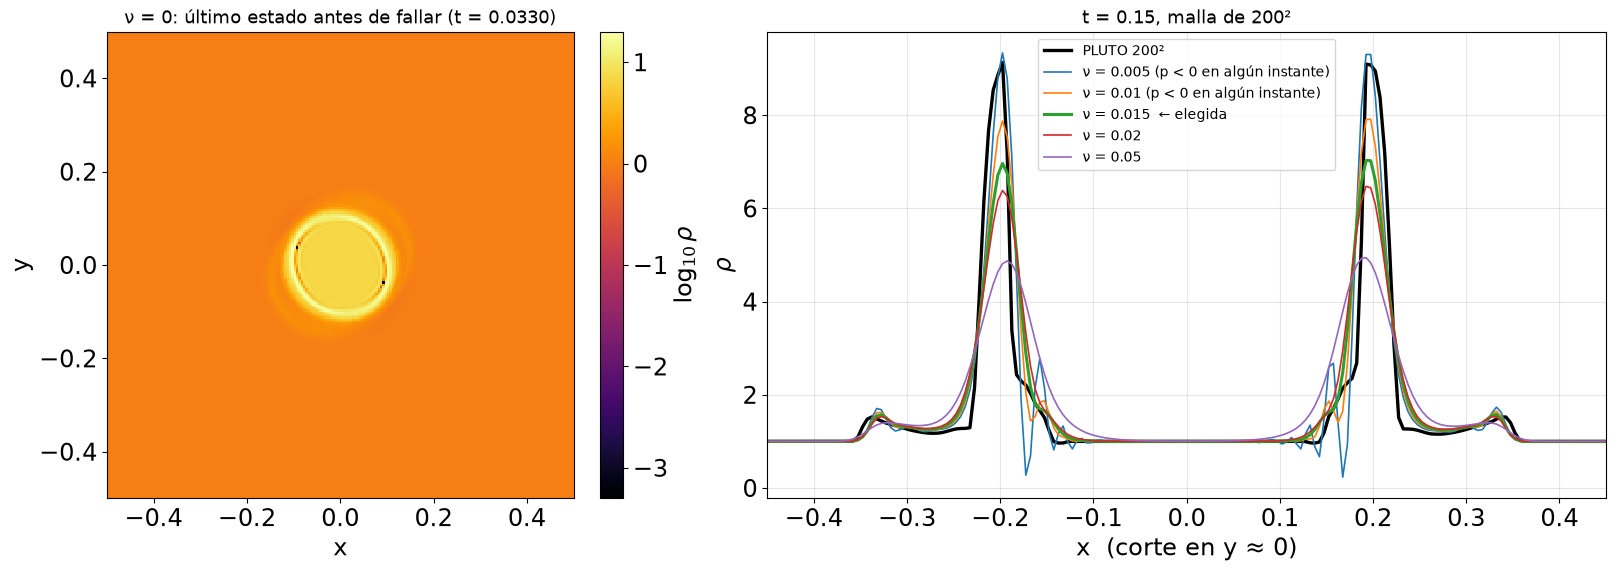

In [16]:
OMEGA, R0, R1 = 20.0, 0.1, 0.115                 # parámetros de init.c
BX0 = 5.0 / np.sqrt(4.0 * np.pi)
CFL = 0.4                                        # el mismo número CFL de pluto.ini

def condicion_inicial(x, y):
    """Primitivas en los centros de celda, igual que Init() de init.c (GEOMETRY == CARTESIAN). Ecuaciones (6) y (7)."""
    X, Y = np.meshgrid(x, y, indexing="ij")
    r = np.sqrt(X**2 + Y**2)
    f = (R1 - r) / (R1 - R0)
    V = np.zeros((8, x.size, y.size))
    V[0], V[7], V[4] = 1.0, 1.0, BX0
    dentro, capa = r <= R0, (r > R0) & (r < R1)
    V[0][dentro], V[1][dentro], V[2][dentro] = 10.0, -OMEGA * Y[dentro], OMEGA * X[dentro]
    V[0][capa] = 1.0 + 9.0 * f[capa]
    V[1][capa] = -f[capa] * OMEGA * Y[capa] * R0 / r[capa]
    V[2][capa] = f[capa] * OMEGA * X[capa] * R0 / r[capa]
    return V

def rotor_prueba(N, nu, T=0.15):
    """Rotor hasta T con viscosidad nu. Se detiene si la solución deja de ser finita o la densidad deja de ser positiva.
    Registra el primer instante en que la presión (sin piso) se vuelve negativa."""
    dx = 1.0 / N
    x = -0.5 + (np.arange(N) + 0.5) * dx
    U, t, pasos, t_pneg = prim_a_cons(condicion_inicial(x, x), GAMMA), 0.0, 0, None
    with np.errstate(all="ignore"):
        while t < T - 1e-13:
            dt = min(paso_dt(U, GAMMA, dx, dx, CFL), T - t)
            U_nuevo = paso_lax_wendroff(U, dt, dx, dx, GAMMA, nu)
            if not np.isfinite(U_nuevo).all() or U_nuevo[0].min() <= 0:
                return dict(nu=nu, completa=False, t=t, t_pneg=t_pneg, U=U, x=x)
            U, t, pasos = U_nuevo, t + dt, pasos + 1
            if t_pneg is None and presion(U, GAMMA).min() < 0:
                t_pneg = t
    return dict(nu=nu, completa=True, t=t, t_pneg=t_pneg, U=U, x=x)

# primer intento sin viscosidad y luego valores crecientes de nu, en la malla de 200²
pruebas = [rotor_prueba(200, nu) for nu in (0.0, 0.005, 0.01, 0.015, 0.02, 0.05)]
print("   nu     ¿llega a t = 0.15?   primera p < 0      rho mín   rho máx  (en el último instante calculado)")
for r in pruebas:
    V = cons_a_prim(r["U"], GAMMA)
    llega = "sí" if r["completa"] else f"no, falla en t = {r['t']:.4f}"
    pneg = "nunca" if r["t_pneg"] is None else f"t = {r['t_pneg']:.4f}"
    print(f"{r['nu']:7.3f}   {llega:24s} {pneg:16s} {V[0].min():8.3f} {V[0].max():8.3f}")

# criterio: el menor nu probado con el que la presión nunca se vuelve negativa
NU = min(r["nu"] for r in pruebas if r["completa"] and r["t_pneg"] is None)
print(f"\nViscosidad elegida: NU = {NU}")

# figura: el intento sin viscosidad y el corte de rho en t = 0.15 para cada nu, frente a PLUTO 200²
x = pruebas[0]["x"]
fig, axs = plt.subplots(1, 2, figsize=(16, 5.6), layout="constrained", gridspec_kw={"width_ratios": [1, 1.6]})
V0 = cons_a_prim(pruebas[0]["U"], GAMMA)
pcm = axs[0].pcolormesh(x, x, np.log10(V0[0]).T, cmap="inferno", shading="nearest", rasterized=True)
fig.colorbar(pcm, ax=axs[0]).set_label(r"$\log_{10}\rho$")
axs[0].set_title(f"ν = 0: último estado antes de fallar (t = {pruebas[0]['t']:.4f})", fontsize=13)
axs[0].set_aspect("equal"); axs[0].set_xlabel("x"); axs[0].set_ylabel("y")
axs[1].plot(PLf[200]["x"], PLf[200]["rho"][:, 100], "k-", lw=2.4, label="PLUTO 200²")
for r in pruebas[1:]:
    V = cons_a_prim(r["U"], GAMMA)
    axs[1].plot(x, V[0][:, 100], lw=2.2 if r["nu"] == NU else 1.2,
                label=f"ν = {r['nu']}" + (" (p < 0 en algún instante)" if r["t_pneg"] else "") + ("  ← elegida" if r["nu"] == NU else ""))
axs[1].set_xlim(-0.45, 0.45); axs[1].grid(alpha=0.3); axs[1].legend(fontsize=10)
axs[1].set_xlabel("x  (corte en y ≈ 0)"); axs[1].set_ylabel(r"$\rho$"); axs[1].set_title("t = 0.15, malla de 200²", fontsize=13)
fig.savefig(FIGURAS / "python_eleccion_viscosidad.png", dpi=130)
plt.show()

La siguiente tabla resume las seis corridas en 200²; como referencia, PLUTO da $\rho$ máx = 12.50 en esta malla (sección 3.6):

| $\nu$ | ¿Llega a $t=0.15$? | Primera presión negativa | $\rho$ mín | $\rho$ máx |
|---|---|---|---|---|
| 0 | No: falla en $t=0.0330$ | $t=0.0245$ | 0.000 | 20.01 |
| 0.005 | Sí | $t=0.0306$ | 0.159 | 10.05 |
| 0.01 | Sí | $t=0.0853$ | 0.733 | 8.88 |
| 0.015 | Sí | nunca | 0.785 | 7.98 |
| 0.02 | Sí | nunca | 0.824 | 7.35 |
| 0.05 | Sí | nunca | 0.963 | 5.45 |

**Qué se obtuvo.** Sin viscosidad, las oscilaciones del tubo de choque aparecen también en el borde del disco, donde el flujo es supersónico (Mach 5.3). En $t=0.0245$ la presión se vuelve negativa y en $t=0.0330$ la densidad llega a cero en algunas celdas y el cálculo se detiene. El panel izquierdo de la figura muestra el último estado calculado: el disco todavía es casi circular, pero en su borde ya hay celdas con densidad prácticamente nula (los puntos negros). El esquema, tal como se usó en la tarea, no sirve para este problema.

**Por qué hace falta $\nu$.** La viscosidad artificial suaviza las discontinuidades lo suficiente para que el esquema no oscile, a cambio de difuminar la solución. El panel derecho muestra ese compromiso: con $\nu=0.005$ el pico de densidad llega casi al de PLUTO, pero hay oscilaciones fuertes en el lado interior del anillo, donde la densidad baja hasta 0.16, y presiones negativas; al aumentar $\nu$ las oscilaciones desaparecen, pero el pico baja y el anillo se ensancha.

**Criterio de elección.** Se tomó el menor $\nu$ de los probados para el que la presión **nunca** se vuelve negativa durante la corrida en 200². Con $\nu=0.01$ la solución final parecía aceptable, pero la presión fue negativa de forma pasajera cerca de $t=0.085$; en una primera revisión, que solo miraba el estado final, ese valor parecía suficiente. El valor elegido es $\nu=0.015$, y se mantiene igual en todas las mallas.

Es una elección empírica, hecha en una sola malla: el valor de $\nu$ es un parámetro ajustado, no una propiedad del problema. Con $\nu$ fijo, el término viscoso equivale a una difusión con coeficiente $\nu\,\Delta x^2/\Delta t$, proporcional a $\Delta x$; por eso el esquema deja de ser de segundo orden y pasa a ser de primer orden, lo que se nota en la convergencia (sección 5.3).

### 4.4 Ejecución

Con $\nu=0.015$, la celda siguiente define las funciones de la corrida y resuelve las tres mallas con CFL = 0.4 hasta $t=0.15$. En cada malla guarda el estado en los mismos tiempos de salida que PLUTO (`dbl.out`) y registra la presión mínima antes del piso en todos los pasos.

In [17]:
def estado(U, t, x, y):
    """Estado como diccionario con las mismas claves que las salidas de PLUTO (sin campo en las caras)."""
    V = cons_a_prim(U, GAMMA)
    f = dict(t=t, x=x, y=y, rho=V[0], vx1=V[1], vx2=V[2], vx3=V[3], Bx1=V[4], Bx2=V[5], Bx3=V[6], prs=V[7])
    return derivadas(f)

def correr_rotor(N, tiempos, nu):
    """Rotor en una malla N x N con viscosidad nu; guarda el estado en los mismos tiempos de salida que PLUTO."""
    dx = 1.0 / N
    x = y = -0.5 + (np.arange(N) + 0.5) * dx
    U, t, pasos, pmin, t0 = prim_a_cons(condicion_inicial(x, y), GAMMA), 0.0, 0, np.inf, time.time()
    salidas = {0: estado(U, t, x, y)}
    for k, tout in enumerate(tiempos[1:], start=1):
        while t < tout - 1e-13:
            dt = min(paso_dt(U, GAMMA, dx, dx, CFL), tout - t)     # el último paso se recorta para llegar a tout
            U, t, pasos = paso_lax_wendroff(U, dt, dx, dx, GAMMA, nu), t + dt, pasos + 1
            pmin = min(pmin, presion(U, GAMMA).min())               # presión antes del piso, en todos los pasos
        salidas[k] = estado(U, t, x, y)
    return salidas, dict(pasos=pasos, segundos=time.time() - t0, pmin=pmin, divb=np.abs(div_b(U[4], U[5], dx, dx)).max())

PY, info = {}, {}
for N in MALLAS:
    PY[N], info[N] = correr_rotor(N, tiempos_pluto(N), NU)
    print(f"N = {N}: {info[N]['pasos']} pasos (PLUTO: {log_pluto(N)[0]}), {info[N]['segundos']:.1f} s, "
          f"p mínima sin piso durante la corrida = {info[N]['pmin']:.4f}, max|div B| = {info[N]['divb']:.1e}")

N = 100: 193 pasos (PLUTO: 190), 0.4 s, p mínima sin piso durante la corrida = 0.0204, max|div B| = 1.5e-04


N = 200: 424 pasos (PLUTO: 320), 4.1 s, p mínima sin piso durante la corrida = 0.0460, max|div B| = 4.5e-07


N = 400: 922 pasos (PLUTO: 590), 50.6 s, p mínima sin piso durante la corrida = 0.0432, max|div B| = 1.7e-11


La siguiente tabla resume las tres corridas:

| $N$ | Pasos Python | Pasos PLUTO | Tiempo Python* | $p$ mínima sin piso | $\max\lvert\nabla\cdot\mathbf{B}\rvert$ en $t=0.15$ |
|---|---|---|---|---|---|
| 100 | 193 | 190 | 0.6 s | 0.0204 | $1.5\times10^{-4}$ |
| 200 | 424 | 320 | 6.5 s | 0.0460 | $4.5\times10^{-7}$ |
| 400 | 922 | 590 | 72.9 s | 0.0432 | $1.7\times10^{-11}$ |

Python da más pasos porque su condición CFL es más estricta que la de PLUTO (sección 4.1): con el mismo CFL = 0.4, su $\Delta t$ es menor. La presión se mantiene positiva en todos los pasos de las tres mallas, así que el piso no interviene.

La divergencia de $\mathbf{B}$ queda en el nivel del redondeo en 400², pero no en las mallas gruesas. El error se concentra en las celdas junto a las fronteras: en 100² la viscosidad ensancha tanto la perturbación que esta alcanza el borde ($\lvert\rho-1\rvert\approx10^{-4}$ allí), y la frontera `outflow`, que copia la última celda, no conserva la divergencia. En 400² la perturbación no llega al borde y el problema no aparece.

\* Tiempos de la ejecución guardada en este notebook; cambian ligeramente en cada ejecución.

In [18]:
verificar(PY[400][3], "Python 400²")

== Python 400², t = 0.150 ==
masa = 1.327265   E_total = 3.858995   max|div B| = 1.67e-11
max|v_z| = 0.0   max|B_z| = 0.0
simetría de 180 grados: diferencia máxima = 3.4e-14
max|rho - 1| en los bordes = 4.9e-12
frente (|p - 1| > 1e-3) a lo largo del eje y (x ~ 0): llega a 0.436
frente (|p - 1| > 1e-3) a lo largo del eje x (y ~ 0): llega a 0.366


**Verificación en 400².** La siguiente tabla resume las comprobaciones de la celda anterior:

| Comprobación | Resultado |
|---|---|
| Masa total | 1.327265 en las cuatro salidas |
| Energía total | 3.858995, sin cambio en $t=0.15$ |
| $\max\lvert\nabla\cdot\mathbf{B}\rvert$ en $t=0.15$ (forma en las esquinas) | $1.67\times10^{-11}$ |
| $\max\lvert v_z\rvert$ y $\max\lvert B_z\rvert$ | 0 exacto |
| Simetría de 180° | Diferencia máxima $3.4\times10^{-14}$ |
| Bordes en $t=0.15$ | $\max\lvert\rho-1\rvert=4.9\times10^{-12}$: las perturbaciones no llegan |
| Presión $\le0$ | No ocurre en ningún paso: la mínima sin piso es 0.043 |

### 4.5 Resultados: mapas de la solución en Python

Las siguientes figuras usan las mismas variables y escalas de color que las de PLUTO, para compararlas de forma directa.

#### 4.5.1 $t=0$

Las figuras se hacen con la misma función `figura` de la sección 3.4, también con pyPLUTO, pasándole los límites de color de PLUTO (`ref`) para que se puedan comparar directamente.

Image class created at nwin 1


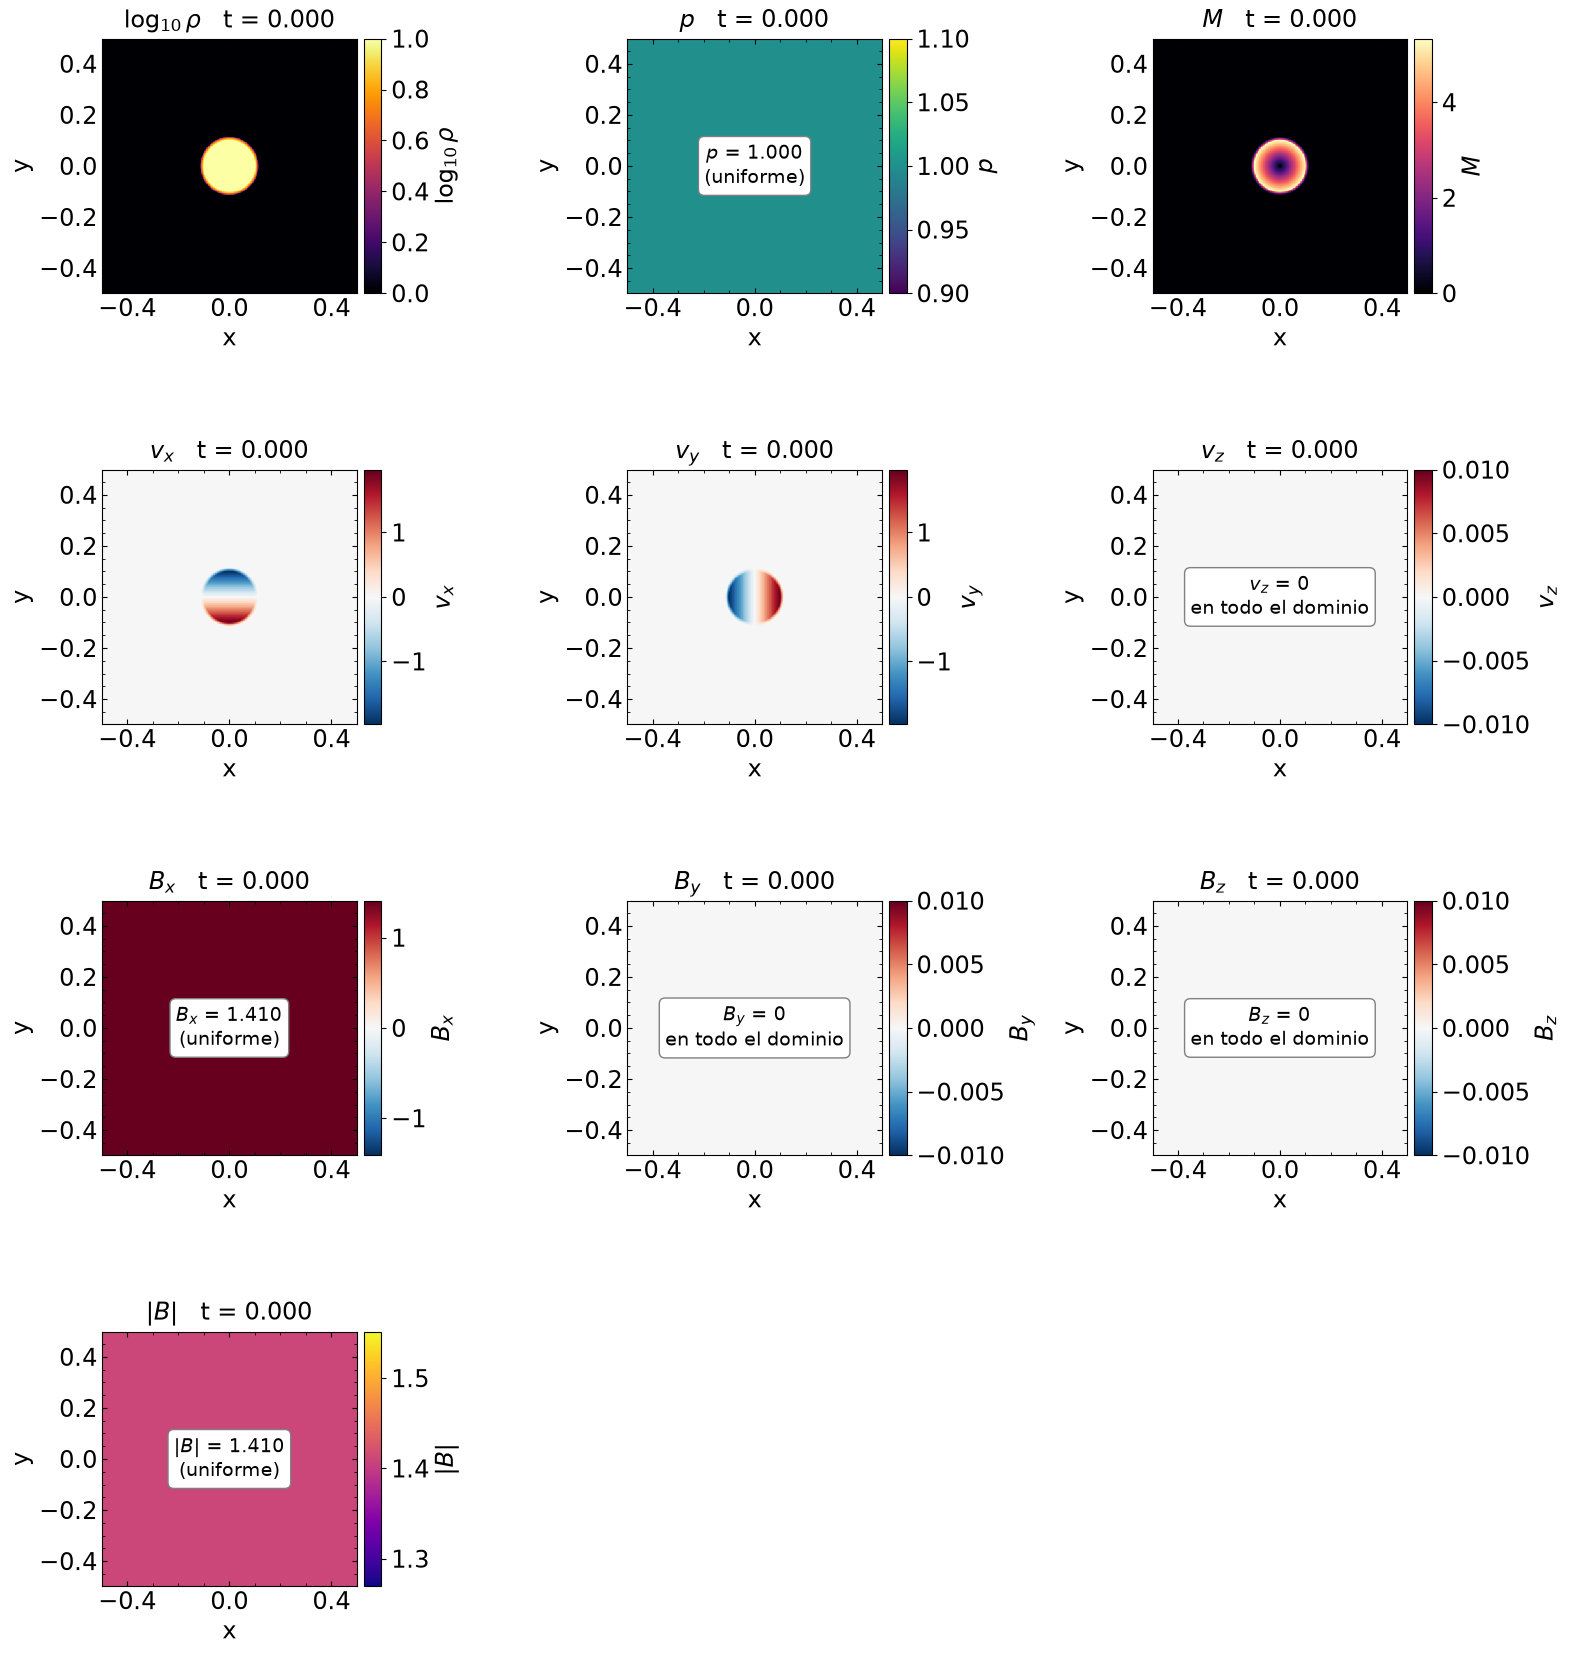

In [19]:
figura(PY[400][0], "python_rotor_N400_0000.png", ref=PL[0])

#### 4.5.2 $t\approx0.05$

Image class created at nwin 1


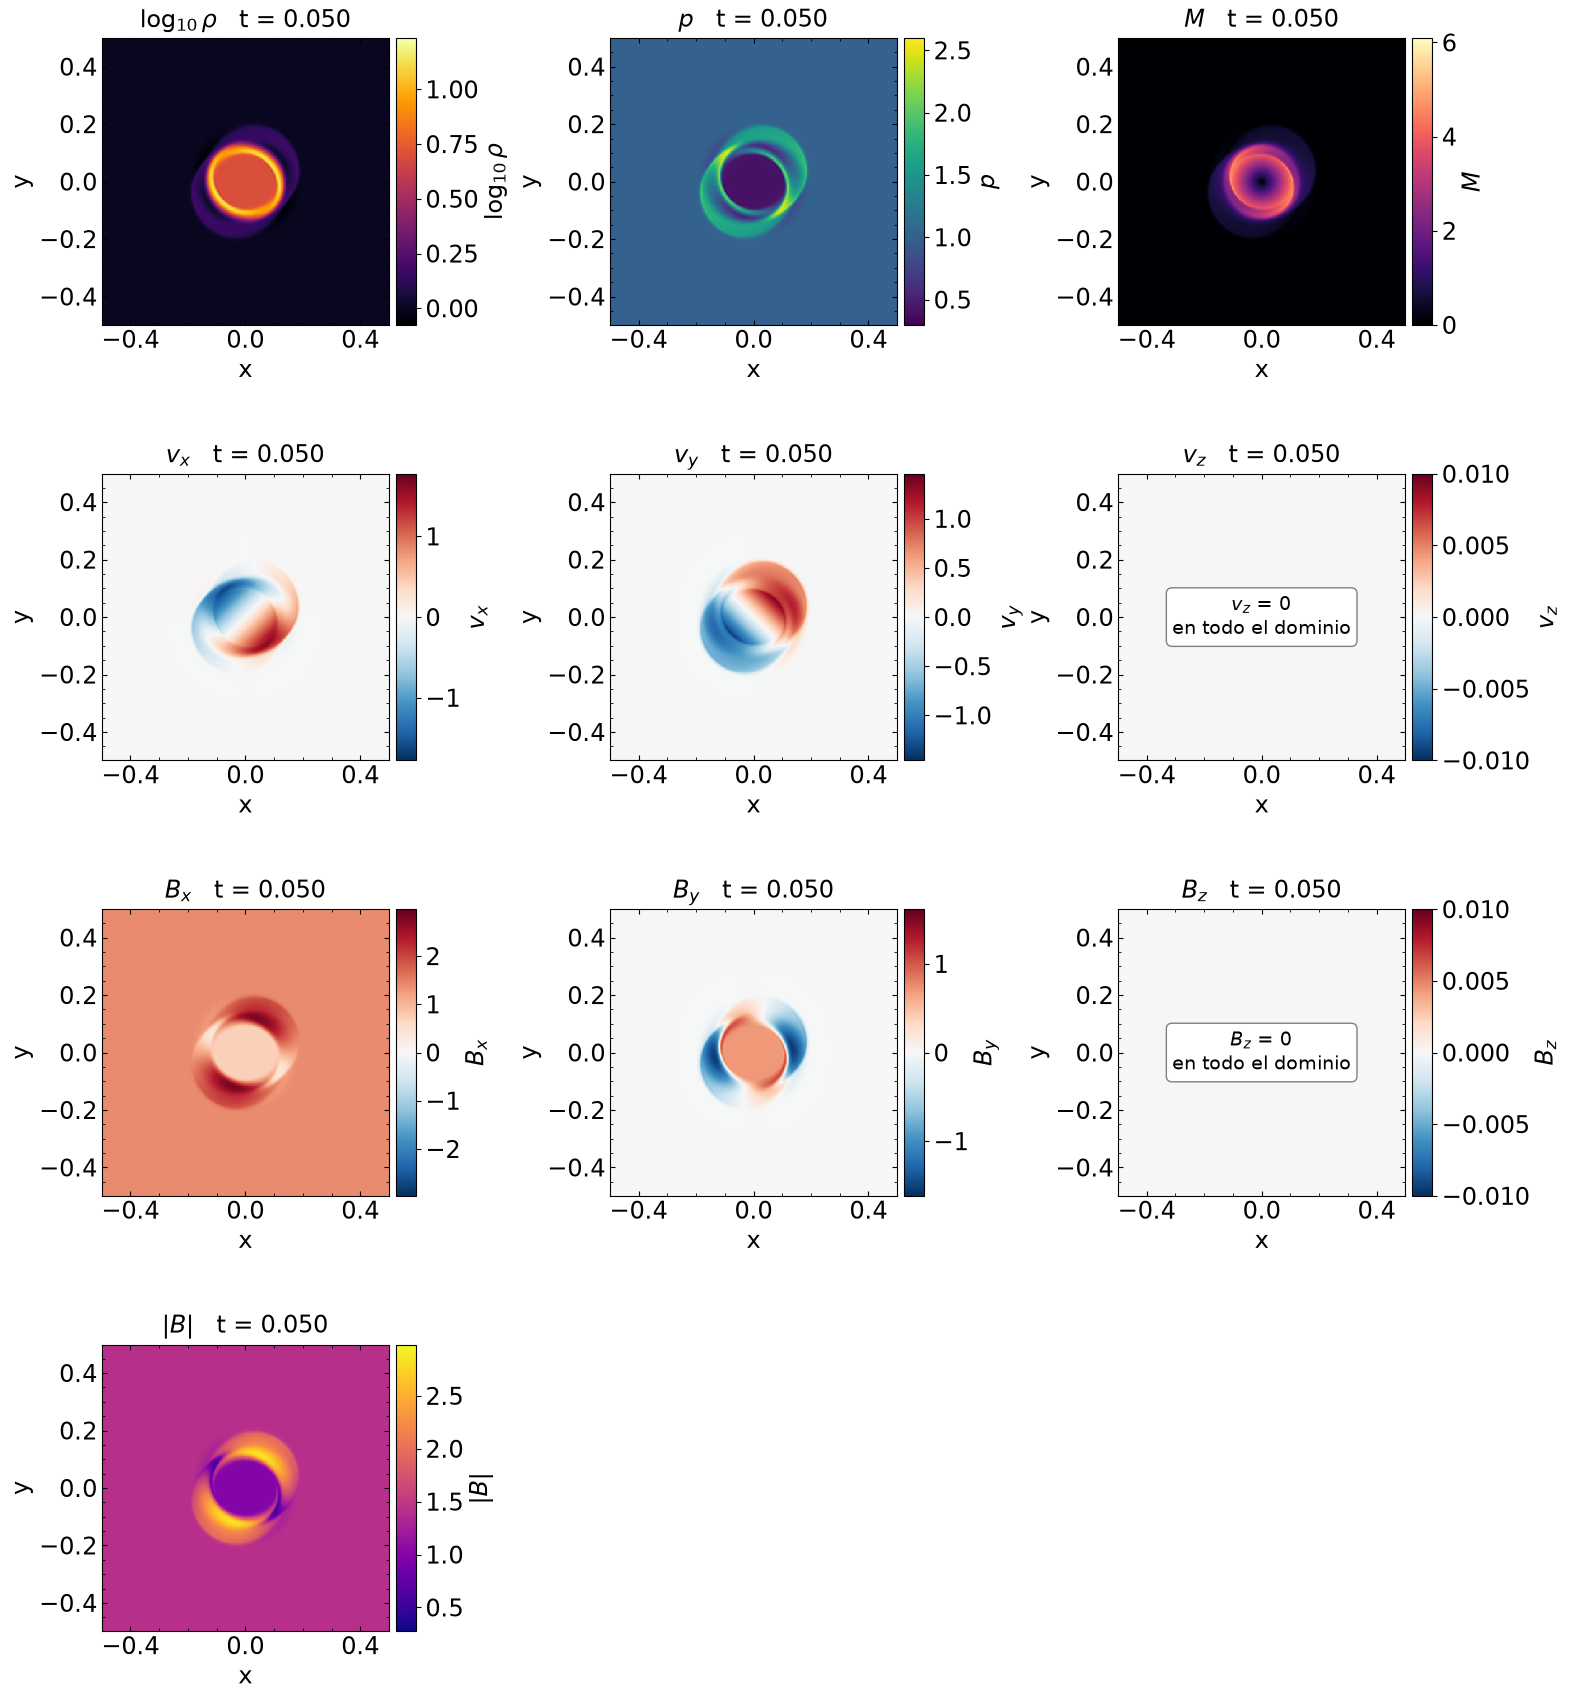

In [20]:
figura(PY[400][1], "python_rotor_N400_0001.png", ref=PL[1])

#### 4.5.3 $t\approx0.10$

Image class created at nwin 1


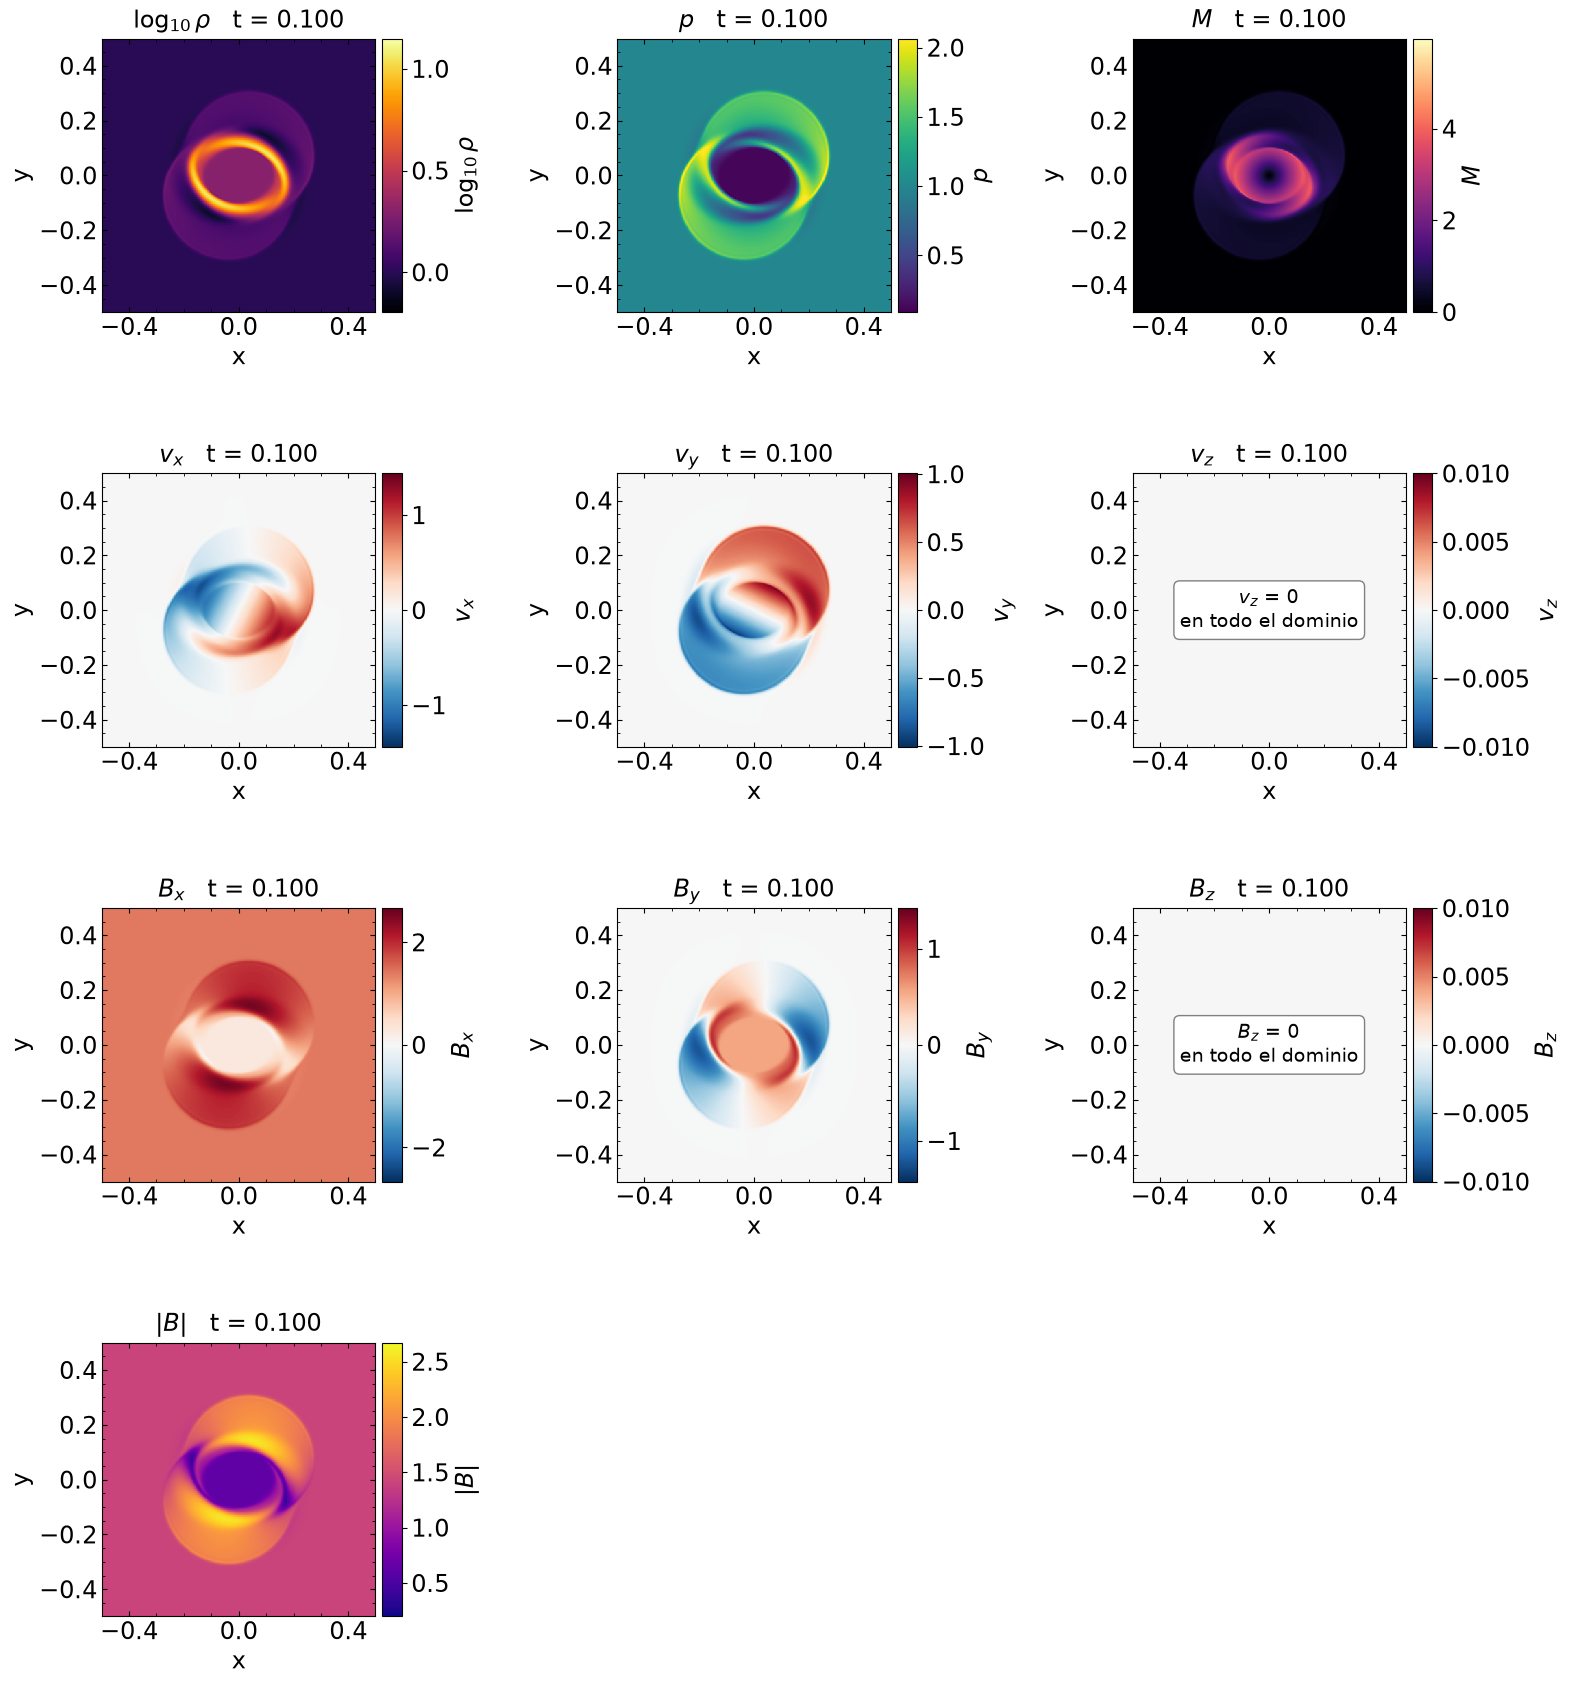

In [21]:
figura(PY[400][2], "python_rotor_N400_0002.png", ref=PL[2])

#### 4.5.4 $t=0.15$

Image class created at nwin 1


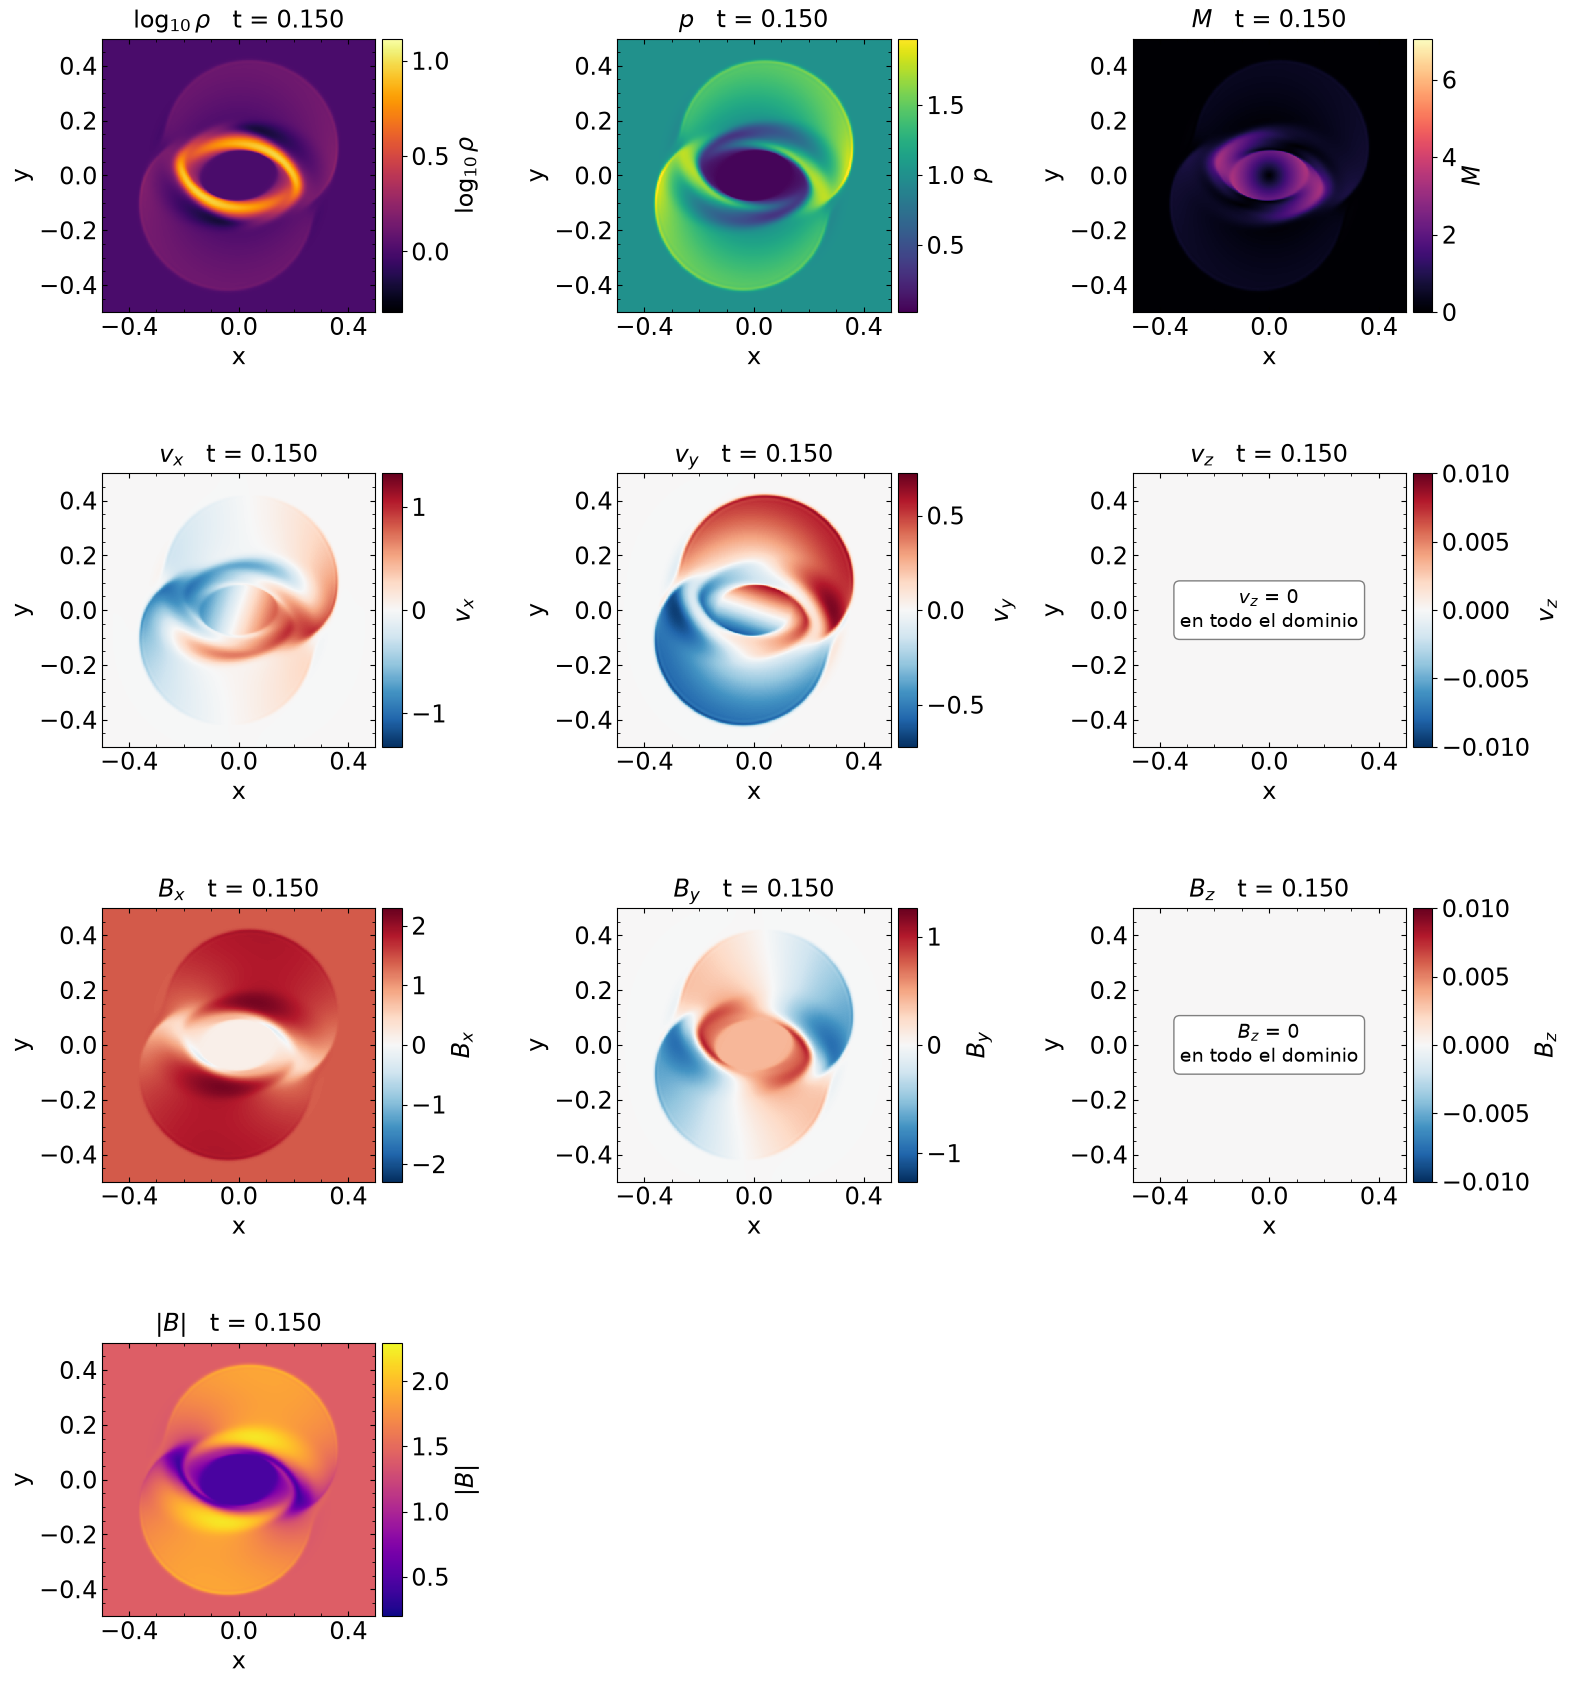

In [22]:
figura(PY[400][3], "python_rotor_N400_0003.png", ref=PL[3])

El solver reproduce la misma secuencia física de la sección 3.4: compresión en el borde del disco, arrastre de las líneas de campo, formación del anillo elíptico y expansión del frente. Las estructuras son más suaves que en PLUTO: el anillo denso es más ancho y su máximo más bajo, por la viscosidad artificial.

La celda siguiente calcula los extremos y las energías de cada salida.

In [23]:
tabla_evolucion(PY[400], "Python 400²")

Python 400²
 n       t    rho_min  rho_max   p_min   p_max   Mach  |B|max     masa     E_cin   E_mag   E_term   E_total
 0 0.00000   1.0000  10.0000  1.0000  1.0000  5.333  1.4105 1.327265  0.3643  0.9947  2.5000 3.858995
 1 0.04985   0.8679  13.8121  0.3186  2.4949  4.830  2.8524 1.327265  0.2779  1.0484  2.5328 3.858995
 2 0.09990   0.8244  11.4599  0.0953  2.1127  3.979  2.5586 1.327265  0.1767  1.1009  2.5814 3.858995
 3 0.15000   0.6685   9.2650  0.0433  2.0748  3.298  2.1958 1.327265  0.1199  1.1205  2.6187 3.858995
Caída de E_cin: 67 %; de lo perdido, 51 % pasa a energía magnética y 49 % a térmica.


La siguiente tabla muestra los extremos de las variables en cada salida:

| Salida | $t$ | $\rho$ mín | $\rho$ máx | $p$ mín | $p$ máx | Mach máx | $\lvert\mathbf{B}\rvert$ máx |
|---|---|---|---|---|---|---|---|
| 0 | 0.00000 | 1.0000 | 10.0000 | 1.0000 | 1.0000 | 5.333 | 1.4105 |
| 1 | 0.04985 | 0.8679 | 13.8121 | 0.3186 | 2.4949 | 4.830 | 2.8524 |
| 2 | 0.09990 | 0.8244 | 11.4599 | 0.0953 | 2.1127 | 3.979 | 2.5586 |
| 3 | 0.15000 | 0.6685 | 9.2650 | 0.0433 | 2.0748 | 3.298 | 2.1958 |

En $t=0.15$, las energías son $E_\mathrm{cin}=0.1199$, $E_\mathrm{mag}=1.1205$ y $E_\mathrm{term}=2.6187$; PLUTO da 0.1290, 1.1322 y 2.5978. La energía cinética cae un 67 % (65 % en PLUTO), y de lo perdido el 51 % pasa al campo magnético (58 % en PLUTO). Los dos códigos describen el mismo frenado magnético, pero en Python una parte mayor de la energía se convierte en calor: es el efecto esperado de la viscosidad artificial, que disipa energía cinética y magnética en las zonas de gradientes fuertes.

Los extremos cambian más. $\rho$ máx es 9.27 frente a 13.05, menor incluso que el de PLUTO en 100² (11.64, sección 3.6), y el Mach máximo es 3.30 frente a 7.05: la difusión llena en parte la región rarificada ($p$ mín 0.043 frente a 0.020), y allí el Mach depende mucho de $p$.

La figura siguiente muestra, como la de la sección 3.4.7 para PLUTO, cuánto cambia cada forma de energía respecto de $t=0$ en la corrida de Python.

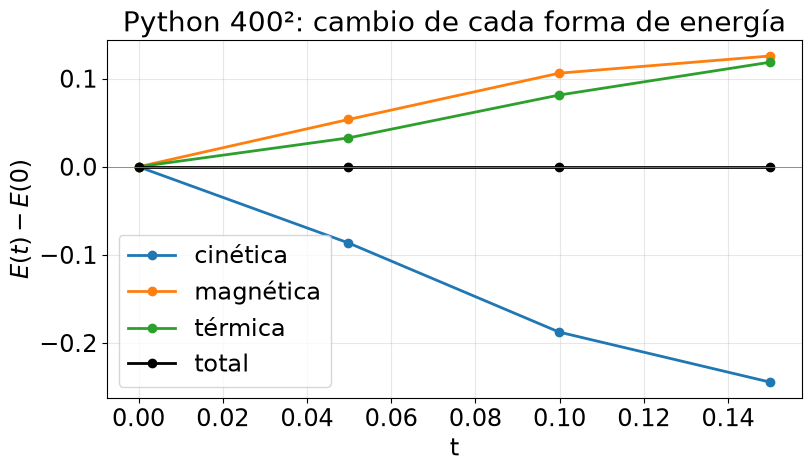

In [24]:
# Cambio de cada forma de energía respecto de t = 0 en las cuatro salidas de Python 400²
R = [resumen(PY[400][n]) for n in sorted(PY[400])]
t = [r["t"] for r in R]
fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
for clave, etiqueta, color in (("ek", "cinética", "tab:blue"), ("em", "magnética", "tab:orange"),
                               ("et", "térmica", "tab:green"), ("etot", "total", "k")):
    ax.plot(t, [r[clave] - R[0][clave] for r in R], "o-", color=color, lw=2, label=etiqueta)
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("t"); ax.set_ylabel(r"$E(t) - E(0)$"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Python 400²: cambio de cada forma de energía")
fig.savefig(FIGURAS / "python_energia.png", dpi=150)
plt.show()

## 5. Comparación entre PLUTO y Python

### 5.1 Métricas

No existe solución exacta para el rotor. Por eso se usan dos tipos de medida, ambos sobre las celdas de la malla.

**Diferencia entre códigos en una misma malla**, con $a$ = Python y $b$ = PLUTO:

$$L_1=\frac{\sum\lvert a-b\rvert}{\sum\lvert b\rvert},\qquad L_2=\sqrt{\frac{\sum(a-b)^2}{\sum b^2}},\qquad \frac{L_\infty}{\mathrm{rango}}=\frac{\max\lvert a-b\rvert}{\max b-\min b}.$$

$P_{99}$/rango es el percentil 99 de $\lvert a-b\rvert$ dividido entre el rango, y muestra el tamaño de la diferencia sin el 1 % de celdas más extremas.

**Convergencia.** Como no hay solución exacta, se comparan mallas sucesivas. La solución de la malla $2N$ se promedia en bloques de 2×2 hasta la malla $N$ ($\bar u_{2N}$) y se calcula, para cada código y cada variable:

- $\delta(N)=\langle\lvert u_N-\bar u_{2N}\rvert\rangle$, cuánto cambia la solución al duplicar la resolución;
- $d(N)=\langle\lvert u^\mathrm{Python}_N-u^\mathrm{PLUTO}_N\rvert\rangle$, la diferencia entre códigos en la misma malla.

Si el error se comporta como $N^{-p}$, $\delta(N)$ también, y el orden se estima como $p=\log_2[\delta(100)/\delta(200)]$. Con tres mallas hay una sola estimación de $p$ por variable.

In [25]:
# (clave, etiqueta, paridad ante una rotación de 180 grados)
VARS = [("rho", r"$\rho$", +1), ("prs", r"$p$", +1), ("vx1", r"$v_x$", -1), ("vx2", r"$v_y$", -1),
        ("Bx1", r"$B_x$", +1), ("Bx2", r"$B_y$", +1), ("mach", r"$M$", +1), ("bmag", r"$|B|$", +1)]

def normas(a, b):
    """Diferencia de a (Python) respecto de b (PLUTO): L1 y L2 relativas, L_inf y P99 sobre el rango de b."""
    d, rango = a - b, b.max() - b.min()
    n1, n2 = np.abs(b).sum(), np.sqrt((b**2).sum())
    return dict(L1=np.abs(d).sum() / n1 if n1 > 0 else np.nan, L2=np.sqrt((d**2).sum()) / n2 if n2 > 0 else np.nan,
                Linf=np.abs(d).max() / rango if rango > 0 else np.nan, P99=np.percentile(np.abs(d), 99) / rango if rango > 0 else np.nan)

def cortes(fp, fy):
    """Cortes superpuestos por el centro del dominio (y ~ 0 y x ~ 0), con la diferencia debajo de cada variable."""
    x, y, N = fp["x"], fp["y"], fp["x"].size
    for corte in ("y", "x"):
        fig = plt.figure(figsize=(14, 21))
        gs = fig.add_gridspec(8, 2, height_ratios=[3, 1] * 4, hspace=0.55, wspace=0.25)
        s = (slice(None), N // 2) if corte == "y" else (N // 2, slice(None))
        coord = x if corte == "y" else y
        for k, (clave, etq, _) in enumerate(VARS):
            r, c = divmod(k, 2)
            a1, a2 = fig.add_subplot(gs[2 * r, c]), fig.add_subplot(gs[2 * r + 1, c])
            a1.plot(coord, fp[clave][s], "k-", lw=1.6, label="PLUTO")
            a1.plot(coord, fy[clave][s], "r--", lw=1.1, label="Python")
            a1.set_title(f"{etq}   ({corte} = {(y if corte == 'y' else x)[N // 2]:+.5f}, t = {fp['t']:.3f})", fontsize=15)
            a2.plot(coord, fy[clave][s] - fp[clave][s], "b-", lw=0.9); a2.axhline(0, color="gray", lw=0.5)
            a2.set_ylabel("Py − PLUTO", fontsize=11); a2.set_xlabel("x" if corte == "y" else "y", fontsize=13)
            plt.setp(a1.get_xticklabels(), visible=False)
            if k == 0:
                a1.legend(fontsize=12)
        fig.suptitle(f"Corte a lo largo de {'x' if corte == 'y' else 'y'}, N = {N}", fontsize=17, y=0.91)
        fig.savefig(FIGURAS / f"compare_cut_{corte}_0003.png", dpi=130, bbox_inches="tight")
        plt.show()

def mapas(fp, fy):
    """(1) PLUTO | Python | diferencia para log rho y p; (2) diferencias de las 8 variables sobre el rango de PLUTO."""
    x, y, t = fp["x"], fp["y"], fp["t"]
    fig, axs = plt.subplots(2, 3, figsize=(17, 10))
    for r, (clave, etq, cm, tr) in enumerate([("rho", r"$\log_{10}\rho$", "inferno", np.log10), ("prs", r"$p$", "viridis", lambda a: a)]):
        A, B = tr(fp[clave]), tr(fy[clave])
        for c, (arr, ttl) in enumerate([(A, "PLUTO"), (B, "Python")]):
            pcm = axs[r, c].pcolormesh(x, y, arr.T, cmap=cm, vmin=A.min(), vmax=A.max(), shading="nearest", rasterized=True)
            fig.colorbar(pcm, ax=axs[r, c], fraction=0.046, pad=0.03).set_label(etq); axs[r, c].set_title(f"{ttl}: {etq}   t = {t:.3f}")
        m = np.abs(B - A).max()
        pcm = axs[r, 2].pcolormesh(x, y, (B - A).T, cmap="RdBu_r", vmin=-m, vmax=m, shading="nearest", rasterized=True)
        fig.colorbar(pcm, ax=axs[r, 2], fraction=0.046, pad=0.03).set_label("Python − PLUTO"); axs[r, 2].set_title(f"Diferencia ({etq})")
        for ax in axs[r]:
            ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
    fig.tight_layout(); fig.savefig(FIGURAS / "compare_maps_rho_p_0003.png", dpi=130); plt.show()
    fig, axs = plt.subplots(3, 3, figsize=(16, 14), layout="constrained")
    axs.ravel()[-1].set_visible(False)
    for ax, (clave, etq, _) in zip(axs.ravel(), VARS):
        rango = fp[clave].max() - fp[clave].min()
        D = (fy[clave] - fp[clave]) / (rango if rango > 0 else 1.0)
        m = max(np.abs(D).max(), 1e-12)
        pcm = ax.pcolormesh(x, y, D.T, cmap="RdBu_r", vmin=-m, vmax=m, shading="nearest", rasterized=True)
        fig.colorbar(pcm, ax=ax, fraction=0.046, pad=0.03).set_label("(Py − PLUTO) / rango PLUTO")
        ax.set_title(f"{etq}   max|dif|/rango = {m:.2e}", fontsize=13); ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
    fig.suptitle(f"Diferencias normalizadas, t = {t:.3f}, N = 400", fontsize=15)
    fig.savefig(FIGURAS / "compare_diff_all_0003.png", dpi=130); plt.show()

### 5.2 Comparación en 400²

#### 5.2.1 Cortes superpuestos

Las siguientes figuras superponen los cortes de PLUTO y Python por el centro del dominio. Las curvas tienen la misma forma, con los frentes en las mismas posiciones. Debajo de cada variable aparece la diferencia: es pequeña fuera de las discontinuidades y crece en los bordes del anillo denso ($x\approx\pm0.2$ en el corte por $y\approx0$), donde Python rebaja el pico de $\rho$ de 10.8 a 8.3.

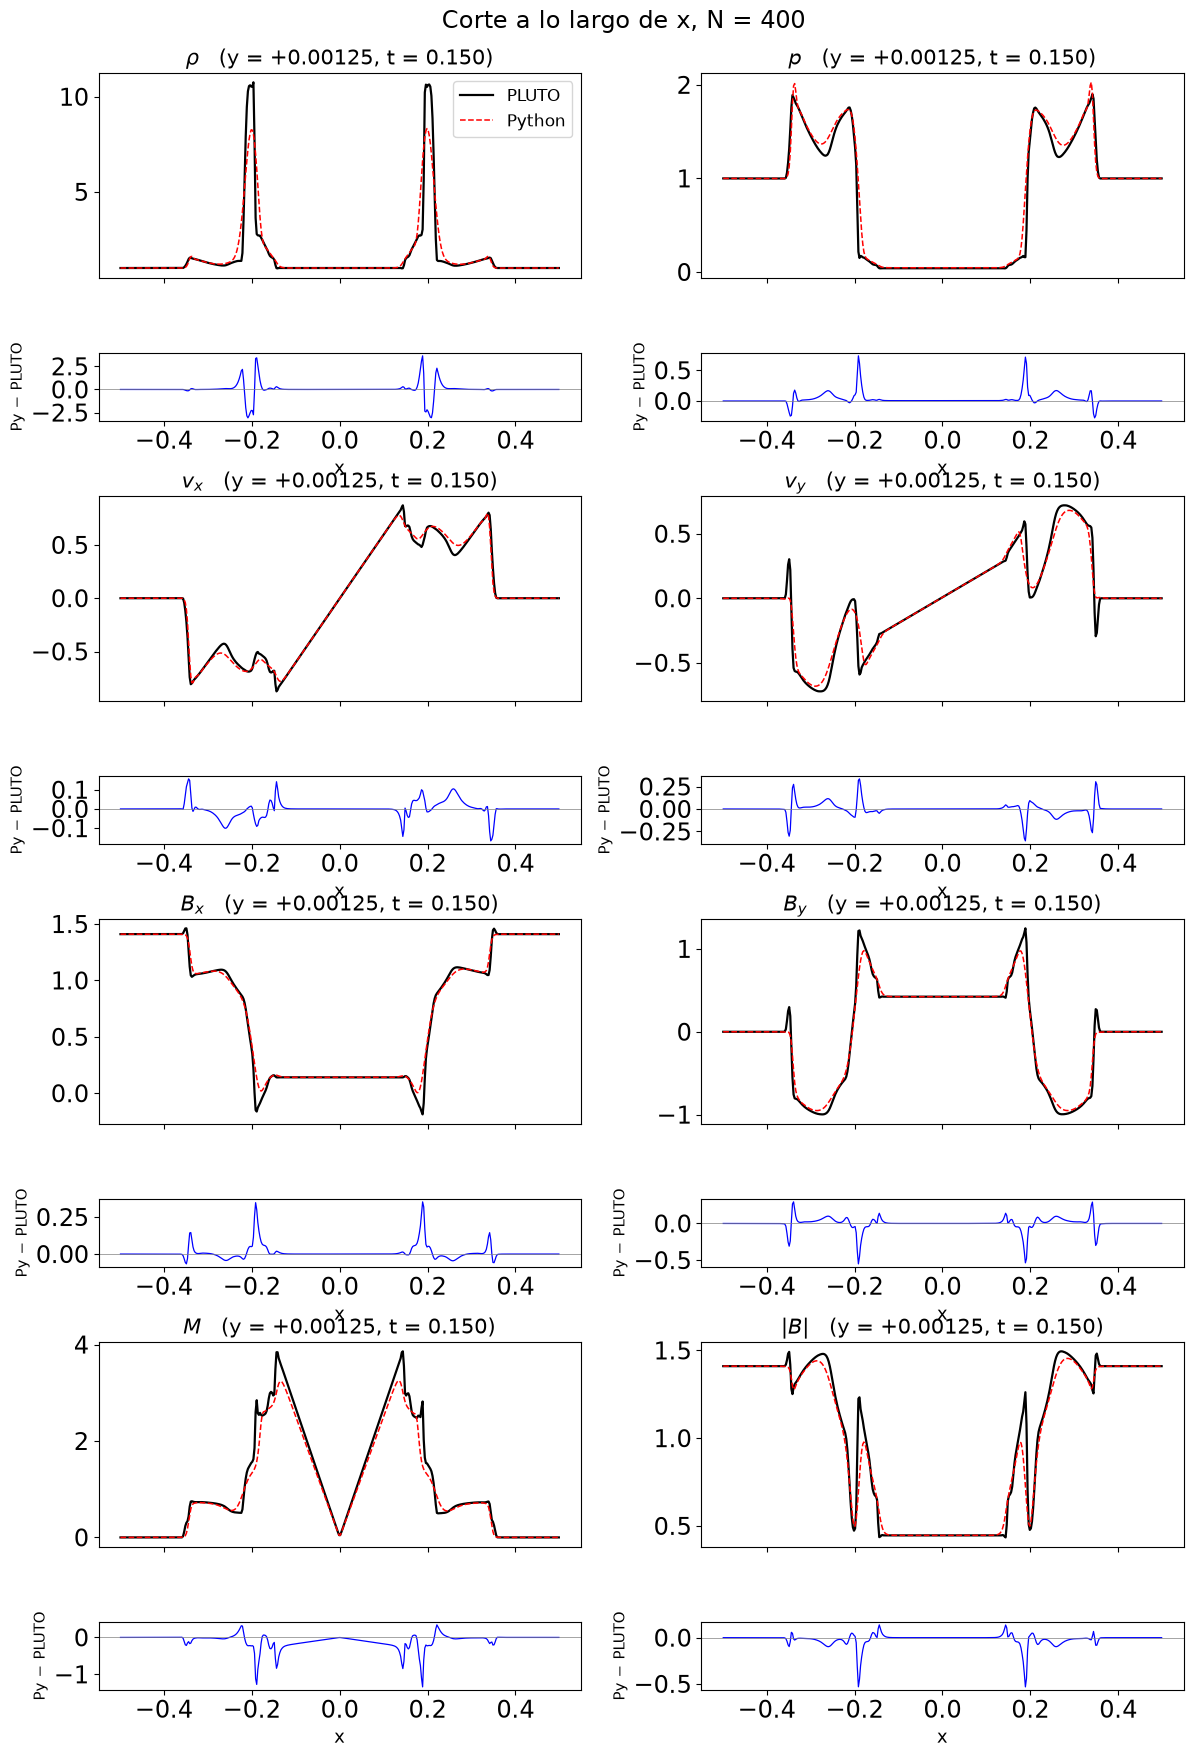

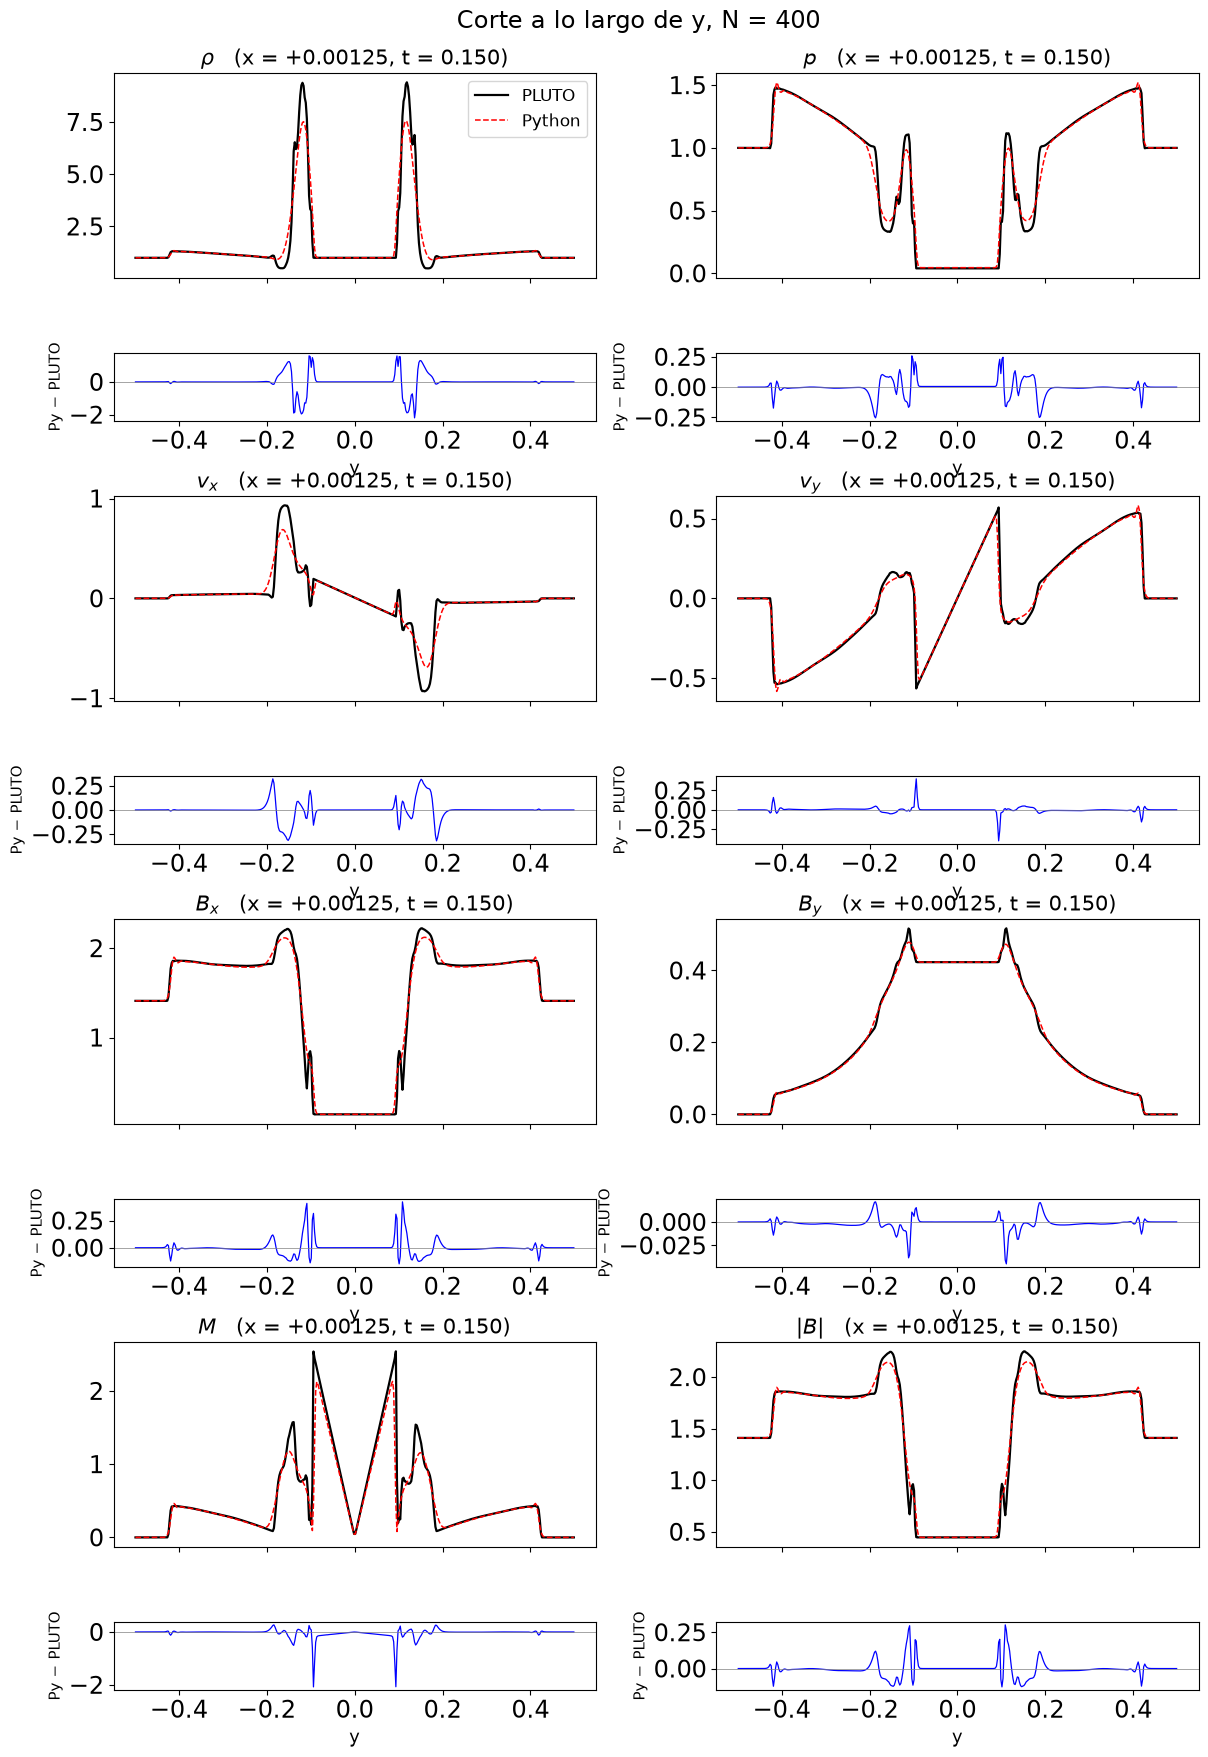

In [26]:
cortes(PL[3], PY[400][3])

#### 5.2.2 Mapas

Las siguientes figuras muestran los mapas de PLUTO, de Python y de su diferencia para $\log_{10}\rho$ y $p$, y la diferencia normalizada de las ocho variables.

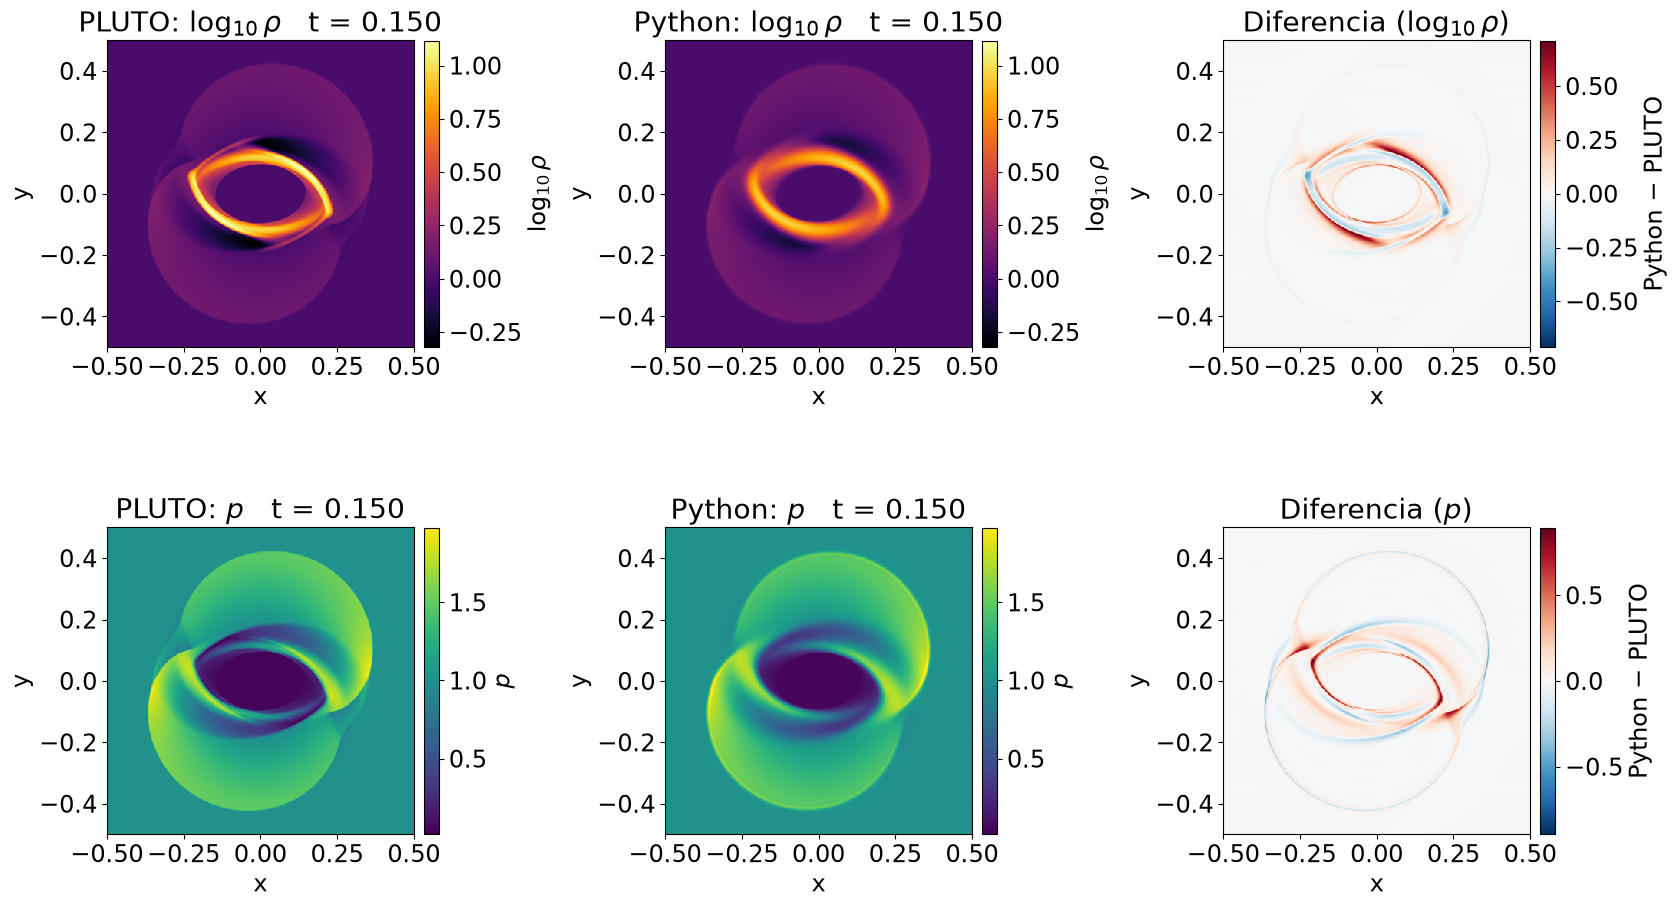

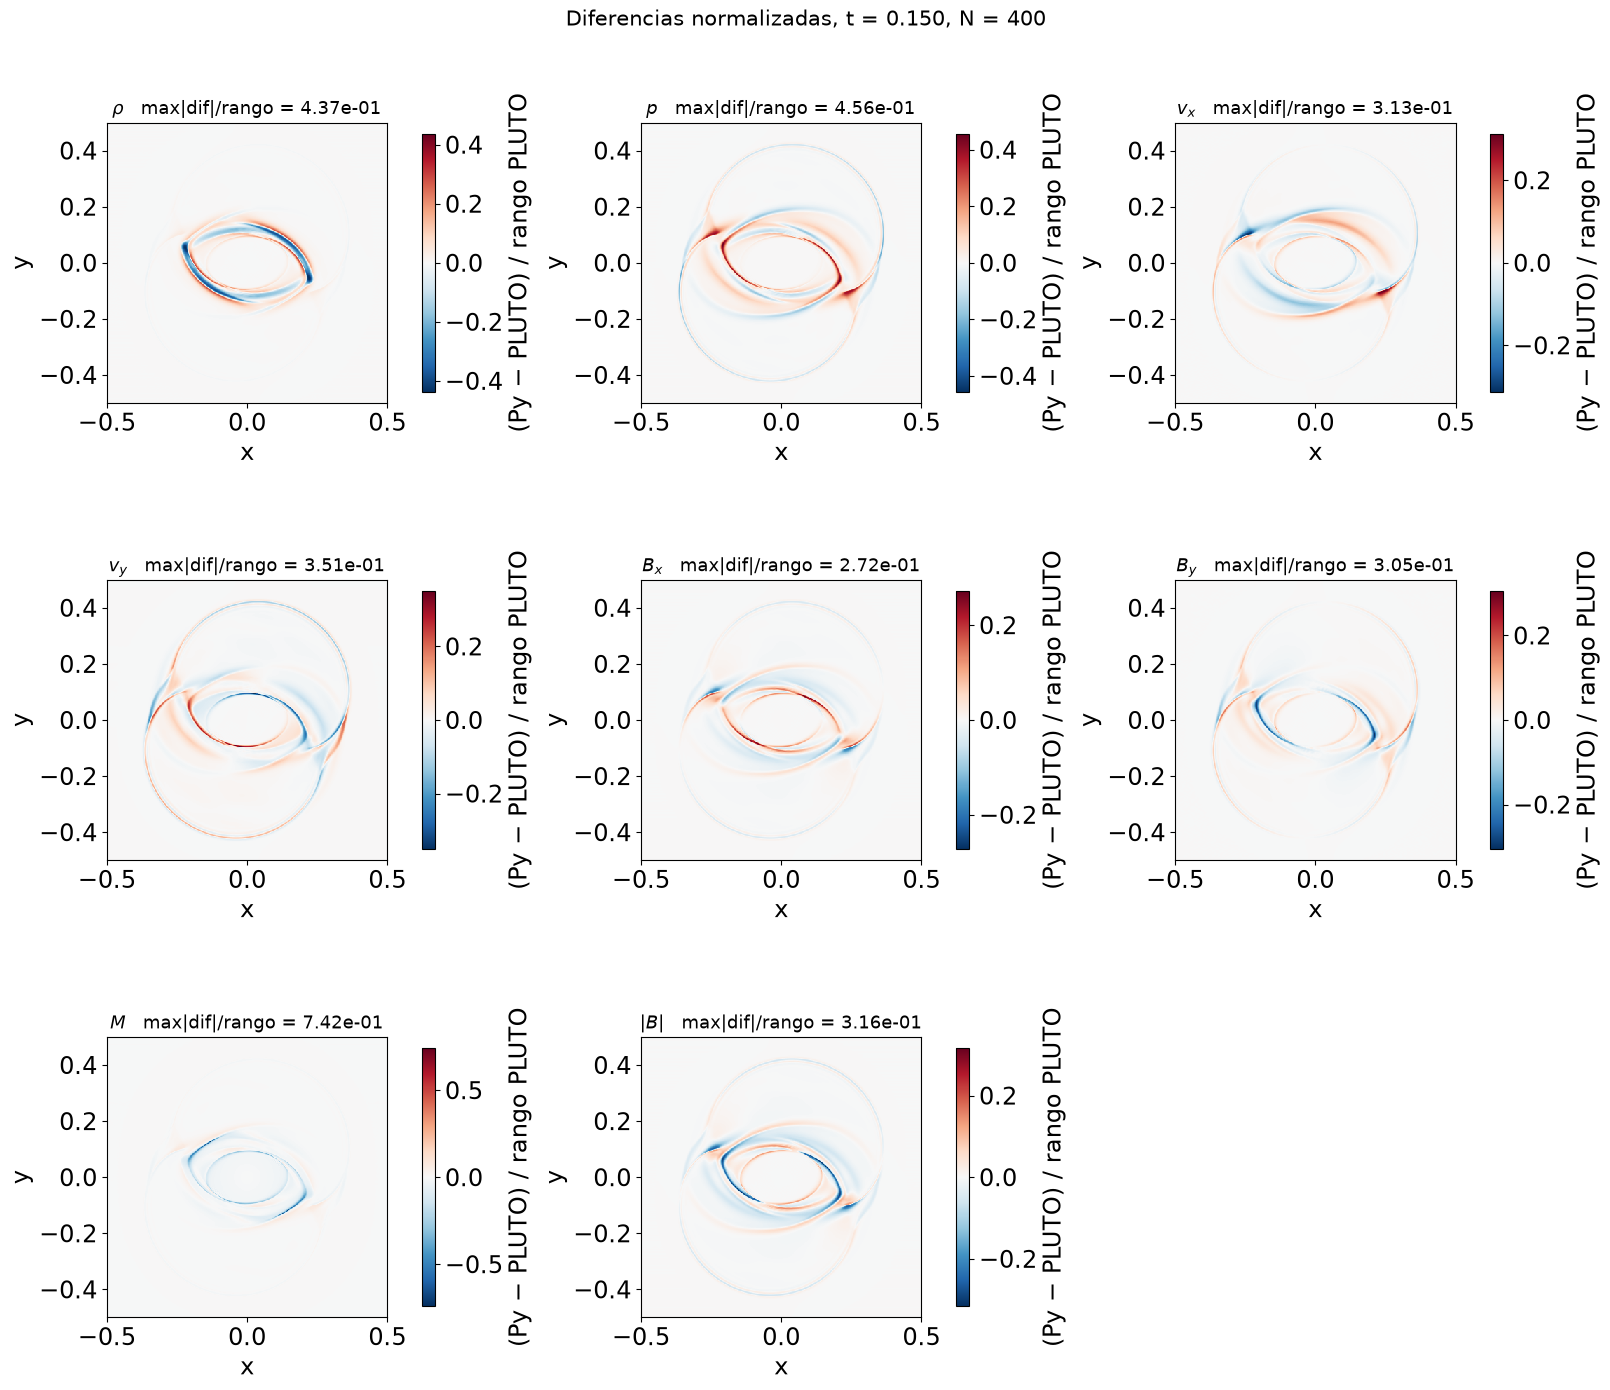

In [27]:
mapas(PL[3], PY[400][3])

Las diferencias no están repartidas al azar. Se concentran en los bordes del anillo denso y, con menor amplitud, en el frente externo. Son zonas de gradientes fuertes: la viscosidad artificial ensancha las discontinuidades, así que el anillo de Python es más ancho y menos alto, y la diferencia aparece como pares de bandas de signo opuesto a cada lado de cada frente.

#### 5.2.3 Normas en $t=0.15$

La celda siguiente calcula las normas de la sección 5.1 para las ocho variables.

In [28]:
print("t = 0.15, N = 400.  Python respecto de PLUTO")
print(f"{'var':>5} {'L1 rel':>10} {'L2 rel':>10} {'Linf/rango':>11} {'P99/rango':>10}")
for clave, _, _ in VARS:
    e = normas(PY[400][3][clave], PL[3][clave])
    print(f"{clave:>5} {e['L1']:10.2e} {e['L2']:10.2e} {e['Linf']:11.2e} {e['P99']:10.2e}")

t = 0.15, N = 400.  Python respecto de PLUTO
  var     L1 rel     L2 rel  Linf/rango  P99/rango
  rho   8.84e-02   2.61e-01    4.37e-01   2.14e-01
  prs   2.48e-02   6.70e-02    4.56e-01   1.63e-01
  vx1   1.53e-01   2.27e-01    3.13e-01   1.04e-01
  vx2   8.36e-02   1.43e-01    3.51e-01   1.25e-01
  Bx1   1.26e-02   3.61e-02    2.72e-01   8.59e-02
  Bx2   7.54e-02   1.34e-01    3.05e-01   7.98e-02
 mach   1.38e-01   2.58e-01    7.42e-01   1.15e-01
 bmag   1.23e-02   3.42e-02    3.16e-01   1.08e-01


La siguiente tabla muestra las normas en $t=0.15$:

| Variable | $L_1$ rel. | $L_2$ rel. | $L_\infty$/rango | $P_{99}$/rango |
|---|---|---|---|---|
| $\rho$ | $8.84\times10^{-2}$ | $2.61\times10^{-1}$ | $4.37\times10^{-1}$ | $2.14\times10^{-1}$ |
| $p$ | $2.48\times10^{-2}$ | $6.70\times10^{-2}$ | $4.56\times10^{-1}$ | $1.63\times10^{-1}$ |
| $v_x$ | $1.53\times10^{-1}$ | $2.27\times10^{-1}$ | $3.13\times10^{-1}$ | $1.04\times10^{-1}$ |
| $v_y$ | $8.36\times10^{-2}$ | $1.43\times10^{-1}$ | $3.51\times10^{-1}$ | $1.25\times10^{-1}$ |
| $B_x$ | $1.26\times10^{-2}$ | $3.61\times10^{-2}$ | $2.72\times10^{-1}$ | $8.59\times10^{-2}$ |
| $B_y$ | $7.54\times10^{-2}$ | $1.34\times10^{-1}$ | $3.05\times10^{-1}$ | $7.98\times10^{-2}$ |
| $M$ | $1.38\times10^{-1}$ | $2.58\times10^{-1}$ | $7.42\times10^{-1}$ | $1.15\times10^{-1}$ |
| $\lvert\mathbf{B}\rvert$ | $1.23\times10^{-2}$ | $3.42\times10^{-2}$ | $3.16\times10^{-1}$ | $1.08\times10^{-1}$ |

La diferencia relativa global en $L_1$ va de $1.2\times10^{-2}$ en $B_x$ y $\lvert\mathbf{B}\rvert$ a $1.5\times10^{-1}$ en $v_x$, es decir, del 1.2 % al 15 %. El máximo local llega al 74 % del rango en el número de Mach, que depende de la presión en la región rarificada, y el percentil 99 queda entre 0.08 y 0.21 del rango. $B_x$ y $\lvert\mathbf{B}\rvert$ son las variables que mejor coinciden; $\rho$ y las velocidades, que cambian bruscamente en el anillo, las que más difieren.

#### 5.2.4 Evolución de $L_1$ relativo

La celda siguiente calcula $L_1$ en las tres salidas posteriores a $t=0$.

In [29]:
print("L1 relativa (Python respecto de PLUTO, 400²)")
print("  var  " + "  ".join(f"t={PL[n]['t']:.5f}" for n in (1, 2, 3)))
for clave in ("rho", "prs", "vx1", "vx2", "Bx1", "Bx2"):
    print(f"{clave:>5}  " + "    ".join(f"{normas(PY[400][n][clave], PL[n][clave])['L1']:.2e}" for n in (1, 2, 3)))

L1 relativa (Python respecto de PLUTO, 400²)
  var  t=0.04985  t=0.09990  t=0.15000
  rho  2.99e-02    6.31e-02    8.84e-02
  prs  1.06e-02    1.89e-02    2.48e-02
  vx1  7.43e-02    1.10e-01    1.53e-01
  vx2  5.79e-02    7.23e-02    8.36e-02
  Bx1  3.75e-03    8.07e-03    1.26e-02
  Bx2  6.76e-02    7.22e-02    7.54e-02


La siguiente tabla muestra cómo evoluciona la diferencia:

| Variable | $t=0.04985$ | $t=0.09990$ | $t=0.15000$ |
|---|---|---|---|
| $\rho$ | $2.99\times10^{-2}$ | $6.31\times10^{-2}$ | $8.84\times10^{-2}$ |
| $p$ | $1.06\times10^{-2}$ | $1.89\times10^{-2}$ | $2.48\times10^{-2}$ |
| $v_x$ | $7.43\times10^{-2}$ | $1.10\times10^{-1}$ | $1.53\times10^{-1}$ |
| $v_y$ | $5.79\times10^{-2}$ | $7.23\times10^{-2}$ | $8.36\times10^{-2}$ |
| $B_x$ | $3.75\times10^{-3}$ | $8.07\times10^{-3}$ | $1.26\times10^{-2}$ |
| $B_y$ | $6.76\times10^{-2}$ | $7.22\times10^{-2}$ | $7.54\times10^{-2}$ |

En $t=0$ los dos códigos parten del mismo estado. Después la diferencia crece en todas las variables, a medida que se forman y se acentúan las discontinuidades que la viscosidad difumina; en $\rho$ pasa de $2.99\times10^{-2}$ a $8.84\times10^{-2}$. En $B_y$ crece poco, de $6.8\times10^{-2}$ a $7.5\times10^{-2}$.

### 5.3 Convergencia

La celda siguiente calcula $\delta(N)$, $d(N)$ y los órdenes en $t=0.15$, y dibuja la figura de convergencia.

  var   dPL(100)   dPL(200)  p PLUTO   dPY(100)   dPY(200)  p Python    d(100)    d(200)    d(400)  p de d  d/delta(200)
  rho   5.99e-02   3.93e-02     0.61   6.84e-02   5.48e-02      0.32  1.52e-01  1.38e-01  1.17e-01    0.19        352.2 %
  prs   1.66e-02   9.39e-03     0.82   2.56e-02   1.75e-02      0.55  4.48e-02  3.54e-02  2.58e-02    0.40        376.8 %
  vx1   1.22e-02   6.57e-03     0.89   1.59e-02   1.18e-02      0.43  3.23e-02  2.71e-02  2.04e-02    0.33        412.9 %
  vx2   1.14e-02   6.39e-03     0.83   1.75e-02   1.13e-02      0.63  2.57e-02  2.00e-02  1.40e-02    0.44        313.6 %
  Bx1   1.12e-02   6.66e-03     0.75   1.61e-02   1.15e-02      0.48  2.90e-02  2.41e-02  1.78e-02    0.35        362.2 %
  Bx2   1.02e-02   5.87e-03     0.80   1.45e-02   9.72e-03      0.57  2.23e-02  1.87e-02  1.37e-02    0.35        318.8 %


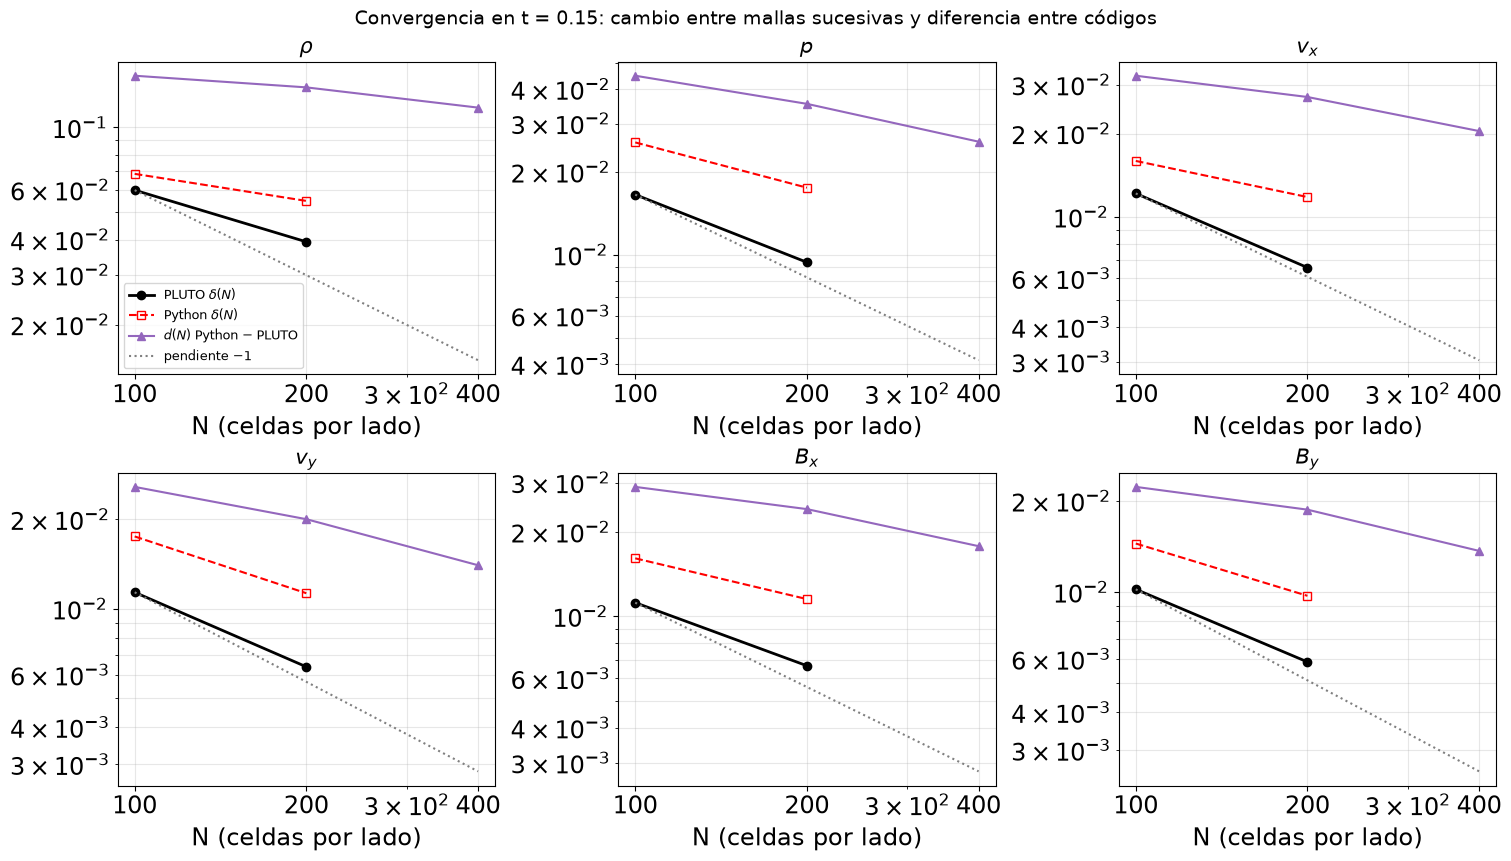

In [30]:
CONV_VARS = [("rho", r"$\rho$"), ("prs", r"$p$"), ("vx1", r"$v_x$"), ("vx2", r"$v_y$"), ("Bx1", r"$B_x$"), ("Bx2", r"$B_y$")]

def promedio_bloques(a, n):
    """Promedia una malla fina en bloques hasta n x n celdas (cada celda gruesa contiene 2x2 finas)."""
    m = a.shape[0] // n
    return a.reshape(n, m, n, m).mean(axis=(1, 3))

def cambio(fin, N, clave):
    """delta(N) = < |u_N - u_2N promediado a N| >, el cambio de la solución al duplicar la resolución."""
    return np.abs(fin[N][clave] - promedio_bloques(fin[2 * N][clave], N)).mean()

PYf = {N: PY[N][max(PY[N])] for N in MALLAS}            # estado final de Python en cada malla
assert all(abs(PYf[N]["t"] - PLf[N]["t"]) < 1e-12 for N in MALLAS)
filas = []
print(f"{'var':>5} {'dPL(100)':>10} {'dPL(200)':>10} {'p PLUTO':>8} {'dPY(100)':>10} {'dPY(200)':>10} {'p Python':>9}"
      f" {'d(100)':>9} {'d(200)':>9} {'d(400)':>9} {'p de d':>7} {'d/delta(200)':>13}")
for clave, etq in CONV_VARS:
    dpl = [cambio(PLf, N, clave) for N in (100, 200)]
    dpy = [cambio(PYf, N, clave) for N in (100, 200)]
    d = [np.abs(PYf[N][clave] - PLf[N][clave]).mean() for N in MALLAS]
    p_d = -np.polyfit(np.log(MALLAS), np.log(d), 1)[0]          # ajuste d ~ N^(-p) con las tres mallas
    filas.append((clave, etq, dpl, dpy, d))
    print(f"{clave:>5} {dpl[0]:10.2e} {dpl[1]:10.2e} {np.log2(dpl[0] / dpl[1]):8.2f} {dpy[0]:10.2e} {dpy[1]:10.2e} "
          f"{np.log2(dpy[0] / dpy[1]):9.2f} {d[0]:9.2e} {d[1]:9.2e} {d[2]:9.2e} {p_d:7.2f} {100 * d[1] / dpl[1]:12.1f} %")

fig, axs = plt.subplots(2, 3, figsize=(15, 8.5), layout="constrained")
for ax, (clave, etq, dpl, dpy, d) in zip(axs.ravel(), filas):
    ax.loglog((100, 200), dpl, "o-", color="k", lw=2, label=r"PLUTO $\delta(N)$")
    ax.loglog((100, 200), dpy, "s--", color="r", mfc="none", label=r"Python $\delta(N)$")
    ax.loglog(MALLAS, d, "^-", color="tab:purple", label=r"$d(N)$ Python − PLUTO")
    ax.loglog(MALLAS, dpl[0] * 100 / np.array(MALLAS), ":", color="gray", label="pendiente −1")
    ax.set_title(etq, fontsize=15); ax.set_xlabel("N (celdas por lado)"); ax.set_xticks(MALLAS, [str(N) for N in MALLAS])
    ax.grid(True, which="both", alpha=0.3)
axs[0, 0].legend(fontsize=9)
fig.suptitle("Convergencia en t = 0.15: cambio entre mallas sucesivas y diferencia entre códigos", fontsize=14)
fig.savefig(FIGURAS / "convergencia.png", dpi=150); plt.show()

#### 5.3.1 Cambio entre mallas sucesivas

La siguiente tabla muestra cuánto cambia la solución de cada código al duplicar la resolución:

| Variable | PLUTO $\delta(100)$ | PLUTO $\delta(200)$ | Python $\delta(100)$ | Python $\delta(200)$ | Orden PLUTO | Orden Python |
|---|---|---|---|---|---|---|
| $\rho$ | $5.99\times10^{-2}$ | $3.93\times10^{-2}$ | $6.84\times10^{-2}$ | $5.48\times10^{-2}$ | 0.61 | 0.32 |
| $p$ | $1.66\times10^{-2}$ | $9.39\times10^{-3}$ | $2.56\times10^{-2}$ | $1.75\times10^{-2}$ | 0.82 | 0.55 |
| $v_x$ | $1.22\times10^{-2}$ | $6.57\times10^{-3}$ | $1.59\times10^{-2}$ | $1.18\times10^{-2}$ | 0.89 | 0.43 |
| $v_y$ | $1.14\times10^{-2}$ | $6.39\times10^{-3}$ | $1.75\times10^{-2}$ | $1.13\times10^{-2}$ | 0.83 | 0.63 |
| $B_x$ | $1.12\times10^{-2}$ | $6.66\times10^{-3}$ | $1.61\times10^{-2}$ | $1.15\times10^{-2}$ | 0.75 | 0.48 |
| $B_y$ | $1.02\times10^{-2}$ | $5.87\times10^{-3}$ | $1.45\times10^{-2}$ | $9.72\times10^{-3}$ | 0.80 | 0.57 |

PLUTO converge con órdenes de 0.61 a 0.89 y el solver en Python con 0.32 a 0.63. En los dos casos el orden queda por debajo de 1, como se espera en un problema con choques: aunque ambos métodos son de segundo orden en flujos suaves (sección 4.2), las discontinuidades reducen el orden global. En Python el orden es menor por la viscosidad artificial, que con $\nu$ fijo añade un error de primer orden (sección 4.3). Sus cambios $\delta(N)$ son entre 1.1 y 1.9 veces los de PLUTO: su solución todavía cambia más al refinar.

**Cautela.** Con tres mallas hay una sola estimación del orden por variable, y la malla de 100² todavía resuelve mal el anillo denso. Por eso los valores de $p$ son aproximados.

#### 5.3.2 Diferencia entre códigos

La siguiente tabla muestra la diferencia entre los códigos en cada malla:

| Variable | $d(100)$ | $d(200)$ | $d(400)$ | Orden de $d$ | $d/\delta_\mathrm{PLUTO}$ en $N=200$ |
|---|---|---|---|---|---|
| $\rho$ | $1.52\times10^{-1}$ | $1.38\times10^{-1}$ | $1.17\times10^{-1}$ | 0.19 | 352 % |
| $p$ | $4.48\times10^{-2}$ | $3.54\times10^{-2}$ | $2.58\times10^{-2}$ | 0.40 | 377 % |
| $v_x$ | $3.23\times10^{-2}$ | $2.71\times10^{-2}$ | $2.04\times10^{-2}$ | 0.33 | 413 % |
| $v_y$ | $2.57\times10^{-2}$ | $2.00\times10^{-2}$ | $1.40\times10^{-2}$ | 0.44 | 314 % |
| $B_x$ | $2.90\times10^{-2}$ | $2.41\times10^{-2}$ | $1.78\times10^{-2}$ | 0.35 | 362 % |
| $B_y$ | $2.23\times10^{-2}$ | $1.87\times10^{-2}$ | $1.37\times10^{-2}$ | 0.35 | 319 % |

En la misma malla, los dos códigos se separan entre 3.1 y 4.1 veces lo que cambia PLUTO al pasar de 200² a 400². La diferencia está dominada por el método (Lax-Wendroff con viscosidad frente a HLLD con limitador), no por detalles de implementación.

Aun así, $d(N)$ disminuye al refinar en todas las variables, aunque despacio, con órdenes de 0.19 a 0.44. Las dos soluciones se acercan entre sí a medida que se refina la malla, lo que es coherente con que ambas converjan a la misma solución; con la convergencia lenta de Python harían falta mallas mucho más finas para que la diferencia fuera pequeña.

### 5.4 Fuentes de error y artefactos

La siguiente tabla resume las fuentes de diferencia identificadas:

| Fuente | Evidencia | Efecto |
|---|---|---|
| Viscosidad artificial | $\nu=0.015$ ensancha las discontinuidades; picos más bajos y más calentamiento en Python | Domina la diferencia entre códigos y reduce el orden de convergencia de Python |
| Oscilaciones de Lax-Wendroff | Sin viscosidad: presión negativa en Brio-Wu y fallo del rotor en $t=0.033$ | Obligan a usar $\nu>0$; con el valor elegido desaparecen |
| Elección empírica de $\nu$ | Elegido en 200² y mantenido en las tres mallas | El resultado depende de un parámetro ajustado |
| Truncamiento en choques | Orden menor que 1 en ambos códigos | Domina el error de cada código frente a la solución continua |
| Fronteras `outflow` con viscosidad | $\nabla\cdot\mathbf{B}$ de $1.5\times10^{-4}$ en los bordes de 100² | Solo en mallas gruesas, donde la perturbación difundida llega al borde |
| Regla de $\Delta t$ | 922 frente a 590 pasos en 400² | Contribución menor, no aislada |
| Pocas mallas | Una sola estimación del orden por variable | Los valores de $p$ son aproximados |

### 5.5 Comparación con la literatura

El artículo de PLUTO reporta este mismo problema en 400² en $t=0.15$ [3], con una combinación de algoritmos distinta: reconstrucción parabólica, HLLC y trazado característico. La celda siguiente calcula los rangos de este trabajo, y la tabla que sigue los compara con los publicados:

In [31]:
for nombre, f in (("PLUTO", PL[3]), ("Python", PY[400][3])):
    b2 = 0.5 * f["bmag"]**2
    print(f"{nombre:6s} 400², t = 0.15:  rho en [{f['rho'].min():.4f}, {f['rho'].max():.4f}]   B²/2 en [{b2.min():.4f}, {b2.max():.4f}]")

PLUTO  400², t = 0.15:  rho en [0.4810, 13.0479]   B²/2 en [0.0194, 2.6282]
Python 400², t = 0.15:  rho en [0.6685, 9.2650]   B²/2 en [0.0760, 2.4107]


| Fuente | $\rho$ | $B^2/2$ |
|---|---|---|
| Mignone et al. (2007), 400² [3] | 0.483 – 13.21 | 0.0177 – 2.642 |
| Este trabajo, PLUTO 400² | 0.4810 – 13.0479 | 0.0194 – 2.6282 |
| Este trabajo, Python 400² | 0.6685 – 9.2650 | 0.0760 – 2.4107 |

PLUTO coincide con el artículo dentro de alrededor del 1 % en los máximos de $\rho$ y $B^2/2$, y algo más en el mínimo de $B^2/2$; los métodos no son idénticos (reconstrucción lineal frente a parabólica). El solver en Python queda más lejos: su $\rho$ máx es un 30 % menor que el del artículo, coherente con la difusión de la viscosidad artificial.

Además, coincide con la literatura que el orden de convergencia sea bajo por las discontinuidades, como reportan Londrillo y Del Zanna [5].

## 6. Conclusiones

**PLUTO.** Se reprodujo la configuración #01 hasta $t=0.15$, sin modificar `init.c`. En 400² se conservan la masa y la energía, $\nabla\cdot\mathbf{B}$ queda en $10^{-11}$, $v_z$ y $B_z$ permanecen en cero, y la corrida es reproducible byte a byte.

**Python.** El solver, escrito solo con NumPy a partir del esquema de Lax-Wendroff, convergió con orden 2 en un flujo suave, pero el esquema sin modificar oscila en los choques y falló en el rotor en $t=0.033$. Fue necesario añadir una viscosidad artificial, cuyo valor ($\nu=0.015$) se eligió a partir de un resultado preliminar en 200². Con ella reprodujo el rotor: conserva la masa y la energía, mantiene la presión positiva sin usar el piso y, en 400², $\nabla\cdot\mathbf{B}$ en $10^{-11}$.

**Comparación.** En 400², la diferencia relativa en $L_1$ entre códigos va del 1.2 % al 15 %, concentrada en los bordes del anillo denso y en los frentes. Se explica por la viscosidad artificial: el anillo de Python es más ancho y su $\rho$ máx (9.27) es menor que el de PLUTO en 100². Al comparar mallas sucesivas, PLUTO converge con órdenes de 0.61–0.89 y Python con 0.32–0.63, y la diferencia entre ambos disminuye al refinar, aunque despacio.

**Literatura.** Los rangos de PLUTO coinciden con los publicados en 400² [3], con diferencias de alrededor del 1 % en los máximos. El solver en Python queda por debajo, como se espera de un método más difusivo.

**Física.** Ambos muestran el mismo frenado magnético: la energía cinética cae un 65–67 %, y alrededor de la mitad de esa pérdida pasa a energía magnética (58 % en PLUTO y 51 % en Python); el resto se convierte en energía térmica, más en Python por la disipación de la viscosidad artificial.

**Limitaciones.**

- No hay solución exacta: la convergencia se estima comparando mallas sucesivas, y con tres mallas hay una sola estimación del orden por variable.
- El valor de $\nu$ se eligió de forma empírica, en una sola malla, y se mantuvo fijo; con $\nu$ fijo el esquema es de primer orden.
- En las mallas gruesas la perturbación difundida alcanza las fronteras, donde $\nabla\cdot\mathbf{B}$ deja de conservarse.
- Las contribuciones de cada diferencia de método a la diferencia entre códigos no se aislaron una por una.

**Posibles mejoras, a partir del estado del arte.** Las dificultades encontradas son justamente las que motivaron el desarrollo de los métodos que usa PLUTO:

- **Esquemas de Godunov.** En lugar de una viscosidad fija en todo el dominio, la disipación puede salir de un solver de Riemann aproximado, que la adapta a las ondas de cada cara: HLL como paso más sencillo y HLLD para resolver además las discontinuidades de Alfvén.
- **Reconstrucción con limitadores** (MUSCL, van Leer). Evita las oscilaciones cerca de los choques sin un parámetro ajustable, y es lo que hace PLUTO con el limitador MC.
- **Control de $\nabla\cdot\mathbf{B}$** con transporte restringido [5] y un tratamiento de fronteras compatible con él, para que la divergencia se conserve también en los bordes.
- **Integración temporal de mayor orden** con propiedades TVD (Shu y Osher) y esquemas de alto orden como ADER-DG [6].
- **Mallas más finas a costo razonable**, con refinamiento adaptativo (Athena++) o aceleradores (Idefix, gPLUTO); el solver en NumPy tarda cerca de un minuto en 400².



## Referencias

1. J. Nikl, M. Kuchařík y S. Weber, *High-order curvilinear finite element magneto-hydrodynamics I: a conservative Lagrangian scheme*, arXiv:2110.11669 (2021).
2. R. Gueroult, J.-M. Rax y N. J. Fisch, *Wave propagation in rotating magnetised plasmas*, arXiv:2209.15346 (2022).
3. A. Mignone et al., *PLUTO: a numerical code for computational astrophysics*, Astrophys. J. Suppl. **170**, 228 (2007).
4. B. van der Holst, R. Keppens y Z. Meliani, *A multidimensional grid-adaptive relativistic magnetofluid code*, arXiv:0807.0713 (2008).
5. P. Londrillo y L. Del Zanna, *On the divergence-free condition in Godunov-type schemes for ideal magnetohydrodynamics: the upwind constrained transport method*, J. Comput. Phys. **195**, 17 (2004); arXiv:astro-ph/0310183.
6. M. Dumbser, I. Peshkov, E. Romenski y O. Zanotti, *High order ADER schemes for a unified first order hyperbolic formulation of Newtonian continuum mechanics coupled with electro-dynamics*, arXiv:1612.02093 (2016).
7. PLUTO, sitio oficial del código: https://plutocode.ph.unito.it